## EDA Step 1 — 원본 데이터 한 건을 직접 뜯어보자

In [1]:
from pathlib import Path
import json
import wave

# --------------------------------------------------
# 1. 저장소 / 원본 데이터 위치 찾기
# --------------------------------------------------
current = Path.cwd().resolve()

if (current / "src").is_dir():
    REPO_ROOT = current
elif (current.parent / "src").is_dir():
    REPO_ROOT = current.parent
else:
    raise FileNotFoundError(
        f"저장소 root를 찾지 못했습니다. 현재 위치: {current}"
    )

DATA_ROOT = REPO_ROOT / "data" / "raw_original"

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"원본 데이터 폴더가 없습니다: {DATA_ROOT}")

print("REPO_ROOT :", REPO_ROOT)
print("DATA_ROOT :", DATA_ROOT)


# --------------------------------------------------
# 2. 원본 파일 전체를 확장자 기준으로 확인
# --------------------------------------------------
wav_paths = sorted(DATA_ROOT.rglob("*.wav"))
json_paths = sorted(DATA_ROOT.rglob("*.json"))

print("\n[전체 파일 수]")
print("WAV :", len(wav_paths))
print("JSON:", len(json_paths))

print("\n[WAV 경로 예시]")
for path in wav_paths[:3]:
    print(path.relative_to(DATA_ROOT))

print("\n[JSON 경로 예시]")
for path in json_paths[:3]:
    print(path.relative_to(DATA_ROOT))


# --------------------------------------------------
# 3. Training JSON 하나를 직접 선택
# --------------------------------------------------
training_jsons = [
    path for path in json_paths
    if "training" in str(path).lower()
]

if not training_jsons:
    raise RuntimeError("Training JSON을 찾지 못했습니다.")

sample_json_path = training_jsons[0]

with sample_json_path.open("r", encoding="utf-8") as f:
    sample_json = json.load(f)

print("\n[선택한 JSON]")
print(sample_json_path.relative_to(DATA_ROOT))

print("\n[JSON 최상위 key]")
print(list(sample_json.keys()))


# --------------------------------------------------
# 4. utterances 구조 확인
# --------------------------------------------------
utterances = sample_json.get("utterances")

print("\n[utterances]")
print("type :", type(utterances).__name__)
print("count:", len(utterances) if isinstance(utterances, list) else None)

if isinstance(utterances, list) and len(utterances) > 0:
    first_utterance = utterances[0]

    print("\n[첫 번째 utterance의 key]")
    print(list(first_utterance.keys()))

    print("\n[첫 번째 utterance 실제 값]")
    for key, value in first_utterance.items():
        print(
            f"{key:15s} | "
            f"type={type(value).__name__:10s} | "
            f"value={value!r}"
        )


# --------------------------------------------------
# 5. 같은 stem의 WAV 찾기
# --------------------------------------------------
stem = sample_json_path.stem

matching_wavs = [
    path for path in wav_paths
    if path.stem == stem
]

print("\n[같은 stem의 WAV]")
print("stem:", stem)
print("matching WAV count:", len(matching_wavs))

for path in matching_wavs:
    print(path.relative_to(DATA_ROOT))


# --------------------------------------------------
# 6. WAV 기본 정보 확인
# --------------------------------------------------
if len(matching_wavs) == 1:
    sample_wav_path = matching_wavs[0]

    with wave.open(str(sample_wav_path), "rb") as wav_file:
        channels = wav_file.getnchannels()
        sample_rate = wav_file.getframerate()
        sample_width = wav_file.getsampwidth()
        frame_count = wav_file.getnframes()

    duration_seconds = frame_count / sample_rate

    print("\n[WAV 기본 정보]")
    print("channels       :", channels)
    print("sample_rate    :", sample_rate)
    print("sample_width   :", sample_width, "bytes")
    print("frame_count    :", frame_count)
    print("duration       :", round(duration_seconds, 3), "seconds")
else:
    print("\nWAV가 정확히 1개 매칭되지 않았으므로 WAV 정보 확인은 중단합니다.")

REPO_ROOT : C:\Users\YW\Study\02_Projects\DCC_2026\prelim
DATA_ROOT : C:\Users\YW\Study\02_Projects\DCC_2026\prelim\data\raw_original

[전체 파일 수]
WAV : 32840
JSON: 32840

[WAV 경로 예시]
Training\1.원천데이터\TS_서울_구급\651e464d69a4f266f062680b_20220101.wav
Training\1.원천데이터\TS_서울_구급\651e464d69a4f266f0626810_20220101.wav
Training\1.원천데이터\TS_서울_구급\651e464d69a4f266f062681a_20220101.wav

[JSON 경로 예시]
Training\2.라벨링데이터\TL_서울_구급\651e464d69a4f266f062680b_20220101.json
Training\2.라벨링데이터\TL_서울_구급\651e464d69a4f266f0626810_20220101.json
Training\2.라벨링데이터\TL_서울_구급\651e464d69a4f266f062681a_20220101.json

[선택한 JSON]
Training\2.라벨링데이터\TL_서울_구급\651e464d69a4f266f062680b_20220101.json

[JSON 최상위 key]
['_id', 'audioPath', 'recordId', 'status', 'startAt', 'endAt', 'utterances', 'mediaType', 'gender', 'address', 'disasterLarge', 'disasterMedium', 'urgencyLevel', 'sentiment', 'symptom', 'triage']

[utterances]
type : list
count: 21

[첫 번째 utterance의 key]
['id', 'startAt', 'endAt', 'text', 'speaker']

[첫 번째 utterance 실제

| Key              | 공식 의미     | 자료형                  | 쉽게 말하면                      |
| ---------------- | --------- | -------------------- | --------------------------- |
| `_id`            | 작업아이디     | String               | 이 라벨링 작업/데이터 레코드를 식별하는 ID   |
| `audioPath`      | 오디오파일 경로  | String               | 대응되는 WAV가 원래 어디 있는지 나타내는 경로 |
| `recordId`       | 녹취아이디     | String               | 해당 녹취 자체를 식별하는 ID           |
| `status`         | 구축 단계별 상태 | String/Number 형태로 관찰 | 데이터 구축·라벨링 진행 상태            |
| `startAt`        | 시작 시점     | Number               | 전체 녹취의 시작 위치                |
| `endAt`          | 종료 시점     | Number               | 전체 녹취의 종료 위치                |
| `utterances`     | 발화        | Array                | 이 통화 안에 들어 있는 개별 발화들의 목록    |
| `mediaType`      | 접수/접수채널   | String               | 어떤 채널로 접수된 신고인지             |
| `gender`         | 신고자 성별    | String               | 신고자의 성별                     |
| `address`        | 주소        | String               | 신고 관련 주소                    |
| `disasterLarge`  | 대분류       | String               | 신고 상황의 큰 유형                 |
| `disasterMedium` | 중분류       | String               | 대분류 아래 세부 유형                |
| `urgencyLevel`   | 긴급도 레벨    | String               | 신고의 긴급도                     |
| `sentiment`      | 감정 분류     | String               | 신고자의 감정 상태 분류               |
| `symptom`        | 환자증상      | Array                | 환자의 증상들                     |
| `triage`         | 환자분류      | String               | 환자의 응급도/분류 결과               |


1. 전체 원본 데이터
   WAV  32,840
   JSON 32,840

2. 공식 call 수 합계
   Training 29,200
   Validation 3,640
   합계 32,840

3. 원본 observation unit
   call 단위

4. call 하나
   WAV 1개 + JSON 1개로 구성되는 구조로 관찰됨

5. 샘플 JSON 하나
   utterances 21개 포함

6. utterance 하나
   id / startAt / endAt / text / speaker

7. 샘플 WAV
   mono
   8 kHz
   16-bit PCM
   47.64 sec

8. M2 분석 단위
   call 내부의 utterance

## EDA Step 2 전체 데이터 무결성 검사

In [2]:
from collections import Counter

# --------------------------------------------------
# EDA Step 2
# 전체 파일 구조 / WAV-JSON pairing 무결성 검사
# --------------------------------------------------

def get_split(path: Path) -> str:
    relative_parts = path.relative_to(DATA_ROOT).parts

    if not relative_parts:
        return "UNKNOWN"

    return relative_parts[0]


# 1. Training / Validation별 WAV, JSON 개수
wav_split_counts = Counter(get_split(path) for path in wav_paths)
json_split_counts = Counter(get_split(path) for path in json_paths)

print("[Split별 WAV 수]")
for split, count in sorted(wav_split_counts.items()):
    print(f"{split:12s}: {count:,}")

print("\n[Split별 JSON 수]")
for split, count in sorted(json_split_counts.items()):
    print(f"{split:12s}: {count:,}")


# 2. split + stem을 고유 ID로 사용
wav_keys = [
    (get_split(path), path.stem)
    for path in wav_paths
]

json_keys = [
    (get_split(path), path.stem)
    for path in json_paths
]


# 3. 중복 확인
wav_key_counts = Counter(wav_keys)
json_key_counts = Counter(json_keys)

duplicate_wav_keys = [
    key for key, count in wav_key_counts.items()
    if count > 1
]

duplicate_json_keys = [
    key for key, count in json_key_counts.items()
    if count > 1
]

print("\n[중복 검사]")
print("중복 WAV key :", len(duplicate_wav_keys))
print("중복 JSON key:", len(duplicate_json_keys))


# 4. WAV ↔ JSON pairing 검사
wav_key_set = set(wav_keys)
json_key_set = set(json_keys)

wav_without_json = wav_key_set - json_key_set
json_without_wav = json_key_set - wav_key_set

print("\n[Pairing 검사]")
print("WAV만 존재 :", len(wav_without_json))
print("JSON만 존재:", len(json_without_wav))
print("정상 pair 수:", len(wav_key_set & json_key_set))


# 5. 공식 규모 확인
print("\n[공식 규모 검증]")

training_pair_count = sum(
    1
    for split, stem in wav_key_set & json_key_set
    if split.lower() == "training"
)

validation_pair_count = sum(
    1
    for split, stem in wav_key_set & json_key_set
    if split.lower() == "validation"
)

print("Training pairs  :", f"{training_pair_count:,}")
print("Validation pairs:", f"{validation_pair_count:,}")

assert training_pair_count == 29_200
assert validation_pair_count == 3_640

assert len(duplicate_wav_keys) == 0
assert len(duplicate_json_keys) == 0

assert len(wav_without_json) == 0
assert len(json_without_wav) == 0

print("\nPASS: 파일 수, 중복, WAV-JSON pairing, 공식 split 규모 모두 정상")

[Split별 WAV 수]
Training    : 29,200
Validation  : 3,640

[Split별 JSON 수]
Training    : 29,200
Validation  : 3,640

[중복 검사]
중복 WAV key : 0
중복 JSON key: 0

[Pairing 검사]
WAV만 존재 : 0
JSON만 존재: 0
정상 pair 수: 32840

[공식 규모 검증]
Training pairs  : 29,200
Validation pairs: 3,640

PASS: 파일 수, 중복, WAV-JSON pairing, 공식 split 규모 모두 정상


공식 제공 규모와 로컬 데이터 규모가 일치하고, 32,840개의 WAV와 JSON이 모두 중복 없이 1:1로 정상 pairing되어 있다. 

샘플 확인 결과 원본 단위는 전화통화 한 건이며, JSON 내부의 utterances를 이용해 M2의 발화 단위 sample을 구성하는 구조임을 확인했다.

## EDA Step 3 JSON Schema 전체 검증

In [3]:
from collections import Counter, defaultdict
import json
import time

# --------------------------------------------------
# EDA Step 3
# 전체 JSON의 top-level schema / dtype 일관성 검사
# --------------------------------------------------

expected_keys = {
    "_id",
    "audioPath",
    "recordId",
    "status",
    "startAt",
    "endAt",
    "utterances",
    "mediaType",
    "gender",
    "address",
    "disasterLarge",
    "disasterMedium",
    "urgencyLevel",
    "sentiment",
    "symptom",
    "triage",
}

key_presence = Counter()
type_counts = defaultdict(Counter)

missing_key_patterns = Counter()
extra_key_patterns = Counter()

utterance_count_by_split = defaultdict(list)

started = time.perf_counter()

for i, json_path in enumerate(json_paths, start=1):

    with json_path.open("r", encoding="utf-8") as f:
        document = json.load(f)

    split = get_split(json_path)

    # -----------------------------
    # 1. top-level key 존재 여부
    # -----------------------------
    actual_keys = set(document.keys())

    for key in actual_keys:
        key_presence[key] += 1

    missing_keys = tuple(sorted(expected_keys - actual_keys))
    extra_keys = tuple(sorted(actual_keys - expected_keys))

    if missing_keys:
        missing_key_patterns[missing_keys] += 1

    if extra_keys:
        extra_key_patterns[extra_keys] += 1

    # -----------------------------
    # 2. key별 Python 자료형
    # -----------------------------
    for key, value in document.items():
        type_counts[key][type(value).__name__] += 1

    # -----------------------------
    # 3. utterances 기본 구조
    # -----------------------------
    utterances = document.get("utterances")

    if isinstance(utterances, list):
        utterance_count_by_split[split].append(len(utterances))

    # 진행상황
    if i % 5000 == 0:
        print(f"processed {i:,}/{len(json_paths):,} JSON files")


elapsed = time.perf_counter() - started


# --------------------------------------------------
# 결과 출력
# --------------------------------------------------

print("\n[처리 완료]")
print(f"JSON files : {len(json_paths):,}")
print(f"elapsed    : {elapsed:.1f} sec")


print("\n[Top-level key 존재 개수]")
for key in sorted(key_presence):
    print(f"{key:20s}: {key_presence[key]:,}")


print("\n[누락 key pattern]")
if missing_key_patterns:
    for pattern, count in missing_key_patterns.most_common():
        print(count, pattern)
else:
    print("없음")


print("\n[추가 key pattern]")
if extra_key_patterns:
    for pattern, count in extra_key_patterns.most_common():
        print(count, pattern)
else:
    print("없음")


print("\n[Key별 자료형]")
for key in sorted(type_counts):
    print(f"{key:20s}: {dict(type_counts[key])}")


print("\n[통화당 utterance 수 기본 통계]")
for split in sorted(utterance_count_by_split):
    values = utterance_count_by_split[split]

    print(
        f"{split:12s} "
        f"calls={len(values):,} "
        f"min={min(values)} "
        f"max={max(values)} "
        f"mean={sum(values)/len(values):.2f}"
    )

processed 5,000/32,840 JSON files
processed 10,000/32,840 JSON files


KeyboardInterrupt: 

# Mission 2 Raw Data EDA 확장 — 실행 전 안내

이 아래의 Step 4~13은 **코드만 구현된 상태**이며 아직 실행 결과가 아닙니다. 위 Step 1~3의 기존 셀·출력·순서는 그대로 보존합니다.

실행은 Checkpoint A → G 순서로 진행합니다. 각 checkpoint의 마지막 검사를 통과하기 전에는 다음 checkpoint를 실행하지 않습니다. 특히 schema, label mapping, timestamp, crop boundary, 경로 mapping 또는 leakage 가정이 깨지면 그 자리에서 중단합니다.

Mission 2에서 모델 입력 후보로 다루는 것은 실제 발화 음성과 duration = endAt - startAt뿐입니다. call ID, utterance ID, split, 경로, annotation row는 **무결성·추적·내부 그룹 검증용 metadata**이며 모델 feature가 아닙니다. text와 금지 annotation은 아래 코드에서 읽지 않습니다.

Cache는 사용자가 셀을 실행할 때만 tmp/mission2_eda 아래에 생성됩니다. 기존 tmp 내용은 삭제하거나 덮어쓰지 않으며, source inventory·seed·feature 설정이 정확히 일치할 때만 재사용합니다.


In [4]:
import hashlib
import json
import math
import sys
import warnings
from collections import Counter, defaultdict
from numbers import Real
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, Markdown, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

if "REPO_ROOT" not in globals():
    REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").is_dir():
    raise RuntimeError(f"저장소 루트에서 Notebook을 실행하세요: {REPO_ROOT}")
if "DATA_ROOT" not in globals():
    DATA_ROOT = REPO_ROOT / "data" / "raw_original"

SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from dcc_data.audio import read_wav_info
from dcc_data.mission2 import milliseconds_to_frame
from dcc_data.mission2_features import HOP_LENGTH, N_FFT, N_MFCC, read_call_waveform

SPEAKER_LABELS = {
    0: "speaker=0 (119 agent)",
    1: "speaker=1 (caller)",
}
SPLIT_ORDER = ["Training", "Validation"]
SPLIT_COLORS = {
    "Training": "#1f77b4",
    "Validation": "#ff7f0e",
}
SPEAKER_COLORS = {
    0: "#2f5597",
    1: "#c55a11",
}

EXPECTED_CALL_COUNTS = {
    "Training": 29_200,
    "Validation": 3_640,
}
BOUNDARY_TOLERANCE_MS = 50.0
EDA_RANDOM_SEED = 42

CACHE_SCHEMA_VERSION = "mission2_raw_eda_v1"
CACHE_DIR = REPO_ROOT / "tmp" / "mission2_eda"
SAVE_FIGURES = False
FIGURE_DIR = REPO_ROOT / "reports" / "figures" / "mission2_eda"

plt.rcParams.update(
    {
        "figure.figsize": (10, 5.5),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "axes.grid": True,
        "grid.alpha": 0.22,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def maybe_save_figure(fig, filename: str) -> None:
    """Save only when the user deliberately enables SAVE_FIGURES."""
    if not SAVE_FIGURES:
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / filename, dpi=200, bbox_inches="tight")


def finite_numeric(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    return values[np.isfinite(values)]


def ecdf_xy(values) -> tuple[np.ndarray, np.ndarray]:
    ordered = np.sort(np.asarray(values, dtype=float))
    ordered = ordered[np.isfinite(ordered)]
    if len(ordered) == 0:
        return ordered, ordered
    probabilities = np.arange(1, len(ordered) + 1) / len(ordered)
    return ordered, probabilities


def weighted_ecdf_xy(values, weights) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[keep], weights[keep]
    if len(values) == 0:
        return np.array([]), np.array([])
    order = np.argsort(values)
    ordered_values = values[order]
    ordered_weights = weights[order]
    return ordered_values, np.cumsum(ordered_weights) / ordered_weights.sum()


def display_table(frame: pd.DataFrame, max_rows: int = 30, decimals: int = 4) -> None:
    bounded = frame.head(max_rows).copy()
    numeric_columns = bounded.select_dtypes(include=[np.number]).columns
    bounded[numeric_columns] = bounded[numeric_columns].round(decimals)
    display(bounded)


def is_real_number(value) -> bool:
    return isinstance(value, Real) and not isinstance(value, (bool, np.bool_))


def source_inventory_signature(paths: list[Path]) -> str:
    """Hash path, size, and mtime only; file bodies are not read for cache validation."""
    digest = hashlib.sha256()
    for path in sorted(paths, key=lambda item: item.as_posix().casefold()):
        stat = path.stat()
        relative = path.relative_to(DATA_ROOT).as_posix()
        digest.update(
            f"{relative}|{stat.st_size}|{stat.st_mtime_ns}\n".encode("utf-8")
        )
    return digest.hexdigest()


## EDA Step 4 — Utterance Manifest & Integrity

**Checkpoint A**

1. **무엇을 측정하는가:** call-level WAV/JSON pair를 utterance-level 행으로 확장하고 label, timestamp, identifier, WAV header, crop boundary를 검사합니다.
2. **입력:** Step 1~3에서 확인한 raw_original의 WAV/JSON 경로와 utterances의 id, startAt, endAt, speaker만 사용합니다. text와 기타 annotation은 읽지 않습니다.
3. **출력 의미:** utterance_df는 후속 분석의 단일 기준 테이블이며, call_df와 integrity_issue_df는 규모·경계·오류를 추적합니다.
4. **잘못될 수 있는 경우:** Step 1~3을 건너뛰었거나 원본 파일이 바뀌었거나 cache metadata가 불일치하면 결과를 신뢰할 수 없습니다. 50 ms 이내 overrun은 반올림/인코딩 허용 후보로 따로 표시하고 그보다 큰 초과만 critical로 분리합니다.
5. **다음 판단 연결:** 마지막 critical invariant가 모두 통과한 경우에만 Step 5로 이동합니다.

기존 Step 2가 이미 pairing을 검증했으므로 다시 별도 manifest 파일을 가정하지 않습니다. call_id는 split 안에서 WAV/JSON을 연결하는 파일 stem입니다. utterance_id와 annotation_row는 추적용일 뿐 모델 입력이 아닙니다.


1. 통화 데이터를 발화 단위로 쪼갠다.
2. 각 발화의 startAt/endAt/speaker가 정상인지 본다.
3. 해당 시간대로 WAV를 실제로 잘라도 문제가 없는지 본다.
4. 규정상 금지된 text·annotation은 사용하지 않는다.
5. 심각한 오류가 0개일 때만 다음 EDA로 간다.

In [5]:
MANIFEST_CACHE_PATH = CACHE_DIR / "utterance_manifest_v1.parquet"
CALL_CACHE_PATH = CACHE_DIR / "call_manifest_v1.parquet"
INTEGRITY_CACHE_PATH = CACHE_DIR / "integrity_issues_v1.parquet"
MANIFEST_META_PATH = CACHE_DIR / "utterance_manifest_meta_v1.json"
REBUILD_UTTERANCE_CACHE = False

INTEGRITY_COLUMNS = [
    "severity",
    "issue_type",
    "split",
    "call_id",
    "utterance_id",
    "record_key",
    "details",
]


def build_verified_pairs() -> list[tuple[str, str, Path, Path]]:
    required_names = [
        "DATA_ROOT",
        "wav_paths",
        "json_paths",
        "get_split",
        "wav_without_json",
        "json_without_wav",
    ]
    missing = [name for name in required_names if name not in globals()]
    if missing:
        raise RuntimeError(
            "Step 1~3을 먼저 실행하세요. 누락된 변수: " + ", ".join(missing)
        )

    wav_by_key = {(get_split(path), path.stem): path for path in wav_paths}
    json_by_key = {(get_split(path), path.stem): path for path in json_paths}
    common_keys = sorted(set(wav_by_key) & set(json_by_key))
    return [
        (split, stem, wav_by_key[(split, stem)], json_by_key[(split, stem)])
        for split, stem in common_keys
    ]


def build_utterance_manifest(
    paired_files: list[tuple[str, str, Path, Path]],
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    utterance_rows = []
    call_rows = []
    issues = []

    def add_issue(
        severity: str,
        issue_type: str,
        split: str,
        call_id: str,
        *,
        utterance_id=None,
        record_key=None,
        details="",
    ) -> None:
        issues.append(
            {
                "severity": severity,
                "issue_type": issue_type,
                "split": split,
                "call_id": call_id,
                "utterance_id": utterance_id,
                "record_key": record_key,
                "details": str(details),
            }
        )

    for call_number, (split, stem, wav_path, json_path) in enumerate(
        paired_files, start=1
    ):
        wav_info = None
        wav_duration_sec = np.nan
        wav_error = ""
        try:
            wav_info = read_wav_info(wav_path)
            wav_duration_sec = wav_info.frame_count / wav_info.sample_rate
        except Exception as exc:
            wav_error = f"{type(exc).__name__}: {exc}"
            add_issue("critical", "wav_header_read_error", split, stem, details=wav_error)

        utterances = None
        json_error = ""
        try:
            with json_path.open("r", encoding="utf-8") as stream:
                document = json.load(stream)
            utterances = document.get("utterances")
            if not isinstance(utterances, list):
                add_issue(
                    "critical",
                    "invalid_utterances_container",
                    split,
                    stem,
                    details=f"type={type(utterances).__name__}",
                )
                utterances = []
        except Exception as exc:
            json_error = f"{type(exc).__name__}: {exc}"
            add_issue("critical", "json_read_error", split, stem, details=json_error)
            utterances = []

        call_rows.append(
            {
                "split": split,
                "call_id": stem,
                "audio_path": wav_path.relative_to(DATA_ROOT).as_posix(),
                "json_path": json_path.relative_to(DATA_ROOT).as_posix(),
                "utterance_count_declared": len(utterances),
                "channels": np.nan if wav_info is None else wav_info.channels,
                "sample_rate": np.nan if wav_info is None else wav_info.sample_rate,
                "sample_width_bytes": np.nan
                if wav_info is None
                else wav_info.sample_width,
                "frame_count": np.nan if wav_info is None else wav_info.frame_count,
                "wav_duration_sec": wav_duration_sec,
                "wav_read_ok": wav_info is not None,
                "wav_error": wav_error,
                "json_read_ok": json_error == "",
                "json_error": json_error,
            }
        )

        for annotation_row, utterance in enumerate(utterances):
            record_key = f"{split}|{stem}|{annotation_row}"
            if not isinstance(utterance, dict):
                add_issue(
                    "critical",
                    "utterance_not_object",
                    split,
                    stem,
                    record_key=record_key,
                    details=f"type={type(utterance).__name__}",
                )
                continue

            utterance_id = utterance.get("id")
            start_at = utterance.get("startAt")
            end_at = utterance.get("endAt")
            speaker = utterance.get("speaker")

            if utterance_id is None:
                add_issue(
                    "warning",
                    "missing_utterance_id",
                    split,
                    stem,
                    record_key=record_key,
                )

            start_valid = is_real_number(start_at) and np.isfinite(float(start_at))
            end_valid = is_real_number(end_at) and np.isfinite(float(end_at))
            speaker_type_valid = isinstance(speaker, (int, np.integer)) and not isinstance(
                speaker, (bool, np.bool_)
            )
            speaker_valid = speaker_type_valid and int(speaker) in (0, 1)

            if start_at is None:
                add_issue(
                    "critical",
                    "missing_startAt",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                )
            elif not start_valid:
                add_issue(
                    "critical",
                    "invalid_startAt_type_or_value",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"type={type(start_at).__name__}, value={start_at!r}",
                )

            if end_at is None:
                add_issue(
                    "critical",
                    "missing_endAt",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                )
            elif not end_valid:
                add_issue(
                    "critical",
                    "invalid_endAt_type_or_value",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"type={type(end_at).__name__}, value={end_at!r}",
                )

            if speaker is None:
                add_issue(
                    "critical",
                    "missing_speaker",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                )
            elif not speaker_type_valid:
                add_issue(
                    "critical",
                    "invalid_speaker_dtype",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"type={type(speaker).__name__}, value={speaker!r}",
                )
            elif not speaker_valid:
                add_issue(
                    "critical",
                    "invalid_speaker_value",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"value={speaker!r}",
                )

            start_ms = float(start_at) if start_valid else np.nan
            end_ms = float(end_at) if end_valid else np.nan
            duration_sec = (
                (end_ms - start_ms) / 1000.0
                if np.isfinite(start_ms) and np.isfinite(end_ms)
                else np.nan
            )

            if np.isfinite(start_ms) and start_ms < 0:
                add_issue(
                    "critical",
                    "negative_startAt",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"startAt_ms={start_ms}",
                )
            if np.isfinite(duration_sec) and duration_sec <= 0:
                add_issue(
                    "critical",
                    "non_positive_duration",
                    split,
                    stem,
                    utterance_id=utterance_id,
                    record_key=record_key,
                    details=f"duration_sec={duration_sec}",
                )

            raw_start_frame = np.nan
            raw_end_frame = np.nan
            crop_start_frame = np.nan
            crop_end_frame = np.nan
            boundary_overrun_ms = np.nan
            boundary_status = "unverified"
            crop_ok = False

            timestamp_order_ok = (
                np.isfinite(start_ms)
                and np.isfinite(end_ms)
                and start_ms >= 0
                and end_ms > start_ms
            )
            if wav_info is not None and timestamp_order_ok:
                raw_start_frame = milliseconds_to_frame(start_ms, wav_info.sample_rate)
                raw_end_frame = milliseconds_to_frame(end_ms, wav_info.sample_rate)
                boundary_overrun_ms = end_ms - wav_duration_sec * 1000.0

                if raw_start_frame >= wav_info.frame_count:
                    boundary_status = "start_after_wav"
                    add_issue(
                        "critical",
                        "startAt_out_of_bounds",
                        split,
                        stem,
                        utterance_id=utterance_id,
                        record_key=record_key,
                        details=f"startAt_ms={start_ms}, wav_ms={wav_duration_sec * 1000:.3f}",
                    )
                elif boundary_overrun_ms > BOUNDARY_TOLERANCE_MS:
                    boundary_status = "critical_overrun"
                    add_issue(
                        "critical",
                        "endAt_out_of_bounds",
                        split,
                        stem,
                        utterance_id=utterance_id,
                        record_key=record_key,
                        details=f"overrun_ms={boundary_overrun_ms:.3f}",
                    )
                else:
                    boundary_status = (
                        "within_tolerance"
                        if boundary_overrun_ms > 0
                        else "within_wav"
                    )
                    if boundary_overrun_ms > 0:
                        add_issue(
                            "warning",
                            "endAt_overrun_within_tolerance",
                            split,
                            stem,
                            utterance_id=utterance_id,
                            record_key=record_key,
                            details=f"overrun_ms={boundary_overrun_ms:.3f}",
                        )
                    crop_start_frame = max(0, raw_start_frame)
                    crop_end_frame = min(raw_end_frame, wav_info.frame_count)
                    crop_ok = crop_end_frame > crop_start_frame
                    if not crop_ok:
                        add_issue(
                            "critical",
                            "empty_crop_after_rounding",
                            split,
                            stem,
                            utterance_id=utterance_id,
                            record_key=record_key,
                            details=(
                                f"frames=[{crop_start_frame}, {crop_end_frame}), "
                                f"raw=[{raw_start_frame}, {raw_end_frame})"
                            ),
                        )

            utterance_rows.append(
                {
                    "split": split,
                    "call_id": stem,
                    "record_key": record_key,
                    "utterance_id": utterance_id,
                    "annotation_row": annotation_row,
                    "speaker": int(speaker) if speaker_valid else np.nan,
                    "startAt_ms": start_ms,
                    "endAt_ms": end_ms,
                    "duration_sec": duration_sec,
                    "audio_path": wav_path.relative_to(DATA_ROOT).as_posix(),
                    "json_path": json_path.relative_to(DATA_ROOT).as_posix(),
                    "sample_rate": np.nan
                    if wav_info is None
                    else wav_info.sample_rate,
                    "channels": np.nan if wav_info is None else wav_info.channels,
                    "sample_width_bytes": np.nan
                    if wav_info is None
                    else wav_info.sample_width,
                    "wav_duration_sec": wav_duration_sec,
                    "raw_start_frame": raw_start_frame,
                    "raw_end_frame": raw_end_frame,
                    "crop_start_frame": crop_start_frame,
                    "crop_end_frame": crop_end_frame,
                    "boundary_overrun_ms": boundary_overrun_ms,
                    "boundary_status": boundary_status,
                    "crop_ok": bool(crop_ok),
                }
            )

        if call_number % 2_000 == 0 or call_number == len(paired_files):
            print(f"manifest progress: {call_number:,}/{len(paired_files):,} calls")

    utterance_df = pd.DataFrame(utterance_rows)
    call_df = pd.DataFrame(call_rows)

    if not utterance_df.empty:
        identifier_mask = utterance_df["utterance_id"].notna()
        duplicate_identifier_mask = identifier_mask & utterance_df.duplicated(
            ["split", "call_id", "utterance_id"], keep=False
        )
        for row in utterance_df.loc[duplicate_identifier_mask].itertuples():
            add_issue(
                "warning",
                "duplicate_utterance_id_within_call",
                row.split,
                row.call_id,
                utterance_id=row.utterance_id,
                record_key=row.record_key,
            )

        valid_interval_mask = (
            np.isfinite(utterance_df["startAt_ms"])
            & np.isfinite(utterance_df["endAt_ms"])
        )
        duplicate_interval_mask = valid_interval_mask & utterance_df.duplicated(
            ["split", "call_id", "startAt_ms", "endAt_ms"], keep=False
        )
        for row in utterance_df.loc[duplicate_interval_mask].itertuples():
            add_issue(
                "warning",
                "duplicate_interval_within_call",
                row.split,
                row.call_id,
                utterance_id=row.utterance_id,
                record_key=row.record_key,
                details=f"[{row.startAt_ms}, {row.endAt_ms}] ms",
            )

        per_call = (
            utterance_df.groupby(["split", "call_id"], observed=True)
            .agg(
                utterance_count=("record_key", "size"),
                speaker0_count=("speaker", lambda values: int((values == 0).sum())),
                speaker1_count=("speaker", lambda values: int((values == 1).sum())),
            )
            .reset_index()
        )
        call_df = call_df.merge(
            per_call, on=["split", "call_id"], how="left", validate="one_to_one"
        )
    else:
        call_df["utterance_count"] = 0
        call_df["speaker0_count"] = 0
        call_df["speaker1_count"] = 0

    count_columns = ["utterance_count", "speaker0_count", "speaker1_count"]
    call_df[count_columns] = call_df[count_columns].fillna(0).astype(int)
    integrity_issue_df = pd.DataFrame(issues, columns=INTEGRITY_COLUMNS)
    return utterance_df, call_df, integrity_issue_df


Manifest parquet cache reused: C:\Users\YW\Study\02_Projects\DCC_2026\prelim\tmp\mission2_eda


### Dataset summary

,split,calls,utterances,wav_header_failures,json_read_failures
0,Training,29200,889358,0,0
1,Validation,3640,111947,0,0


### Parquet roundtrip row counts

,dataframe,rows
0,utterance_df,1001305
1,call_df,32840
2,integrity_issue_df,6


...

,issue_type,count,severity
0,json_read_error,0,critical
1,wav_header_read_error,0,critical
2,invalid_utterances_container,0,critical
3,utterance_not_object,0,critical
4,missing_utterance_id,0,warning
5,duplicate_utterance_id_within_call,0,warning
6,duplicate_interval_within_call,6,warning
7,missing_speaker,0,critical
8,invalid_speaker_dtype,0,critical
9,invalid_speaker_value,0,critical


### Representative issue samples

,severity,issue_type,split,call_id,utterance_id,record_key,details
0,warning,duplicate_interval_within_call,Training,651e4b1829d82455557a200b_20220502,wavesurfer_82b9a29978,Training|651e4b1829d82455557a200b_20220502|23,"[52917.0, 53599.0] ms"
1,warning,duplicate_interval_within_call,Training,651e4b1829d82455557a200b_20220502,wavesurfer_gaqavvtcq6g,Training|651e4b1829d82455557a200b_20220502|24,"[52917.0, 53599.0] ms"
2,warning,duplicate_interval_within_call,Training,651e4bc5df6bf0d825aa56fa_20220505,wavesurfer_iedgleldo1g,Training|651e4bc5df6bf0d825aa56fa_20220505|23,"[44148.0, 44839.0] ms"
3,warning,duplicate_interval_within_call,Training,651e4bc5df6bf0d825aa56fa_20220505,wavesurfer_5609q1dal0o,Training|651e4bc5df6bf0d825aa56fa_20220505|24,"[44148.0, 44839.0] ms"
4,warning,duplicate_interval_within_call,Training,651e4c5b48bae907503799a9_20220602,wavesurfer_kd7dt2fr3so,Training|651e4c5b48bae907503799a9_20220602|17,"[28548.0, 29321.0] ms"
5,warning,duplicate_interval_within_call,Training,651e4c5b48bae907503799a9_20220602,wavesurfer_14b5qqq0p5,Training|651e4c5b48bae907503799a9_20220602|18,"[28548.0, 29321.0] ms"


### Utterances per call

,split,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,Training,29200.0,30.4575,11.3829,2.0,12.0,16.0,22.0,29.0,36.0,52.0,65.0,98.0
1,Validation,3640.0,30.7547,11.5191,3.0,12.0,16.0,22.0,29.0,37.0,53.0,64.0,95.0


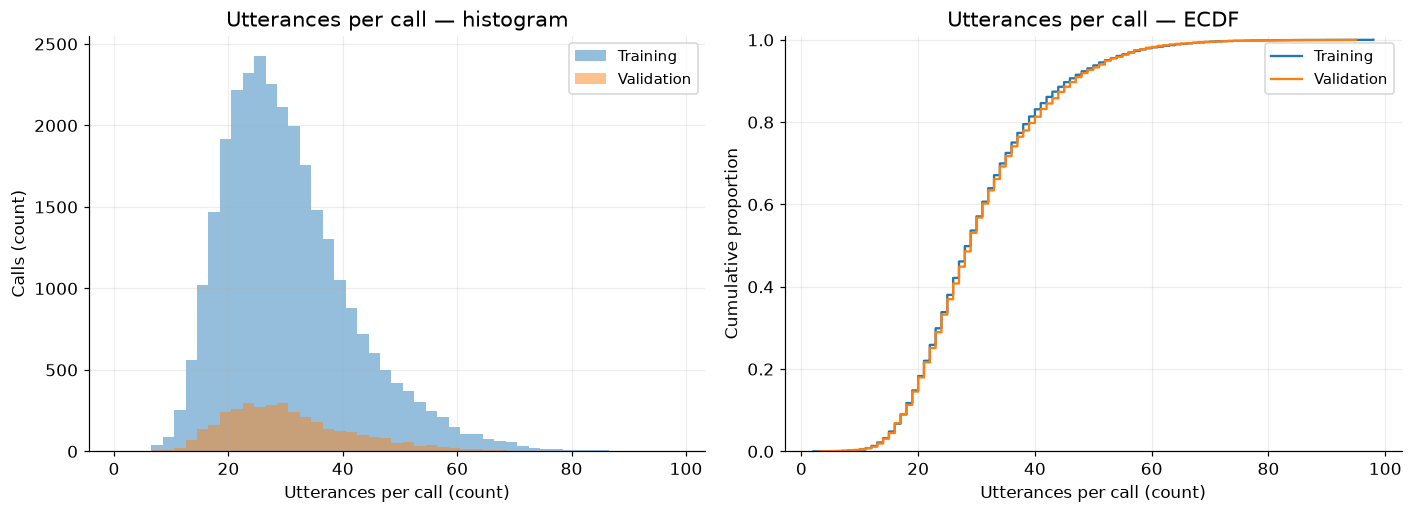

CHECKPOINT A PASS: Step 5로 이동할 수 있습니다.


In [6]:
RECOVERY_DIR = CACHE_DIR / "_recovery"
RECOVERY_PATHS = {
    "utterance_df": RECOVERY_DIR / "utterance_df.pkl",
    "call_df": RECOVERY_DIR / "call_df.pkl",
    "integrity_issue_df": RECOVERY_DIR / "integrity_issue_df.pkl",
}
EXPECTED_RECOVERY_ROWS = {
    "utterance_df": 1_001_305,
    "call_df": 32_840,
    "integrity_issue_df": 6,
}
ALLOW_RAW_RESCAN = False

cache_files_exist = all(
    path.is_file()
    for path in [
        MANIFEST_CACHE_PATH,
        CALL_CACHE_PATH,
        INTEGRITY_CACHE_PATH,
        MANIFEST_META_PATH,
    ]
)
recovery_files_exist = all(path.is_file() for path in RECOVERY_PATHS.values())
cached_meta = None
if cache_files_exist:
    try:
        cached_meta = json.loads(MANIFEST_META_PATH.read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"Manifest cache metadata를 읽지 못해 재생성합니다: {exc}")

if recovery_files_exist:
    recovery_inventory = {
        name: {
            "path": path.relative_to(REPO_ROOT).as_posix(),
            "size_bytes": path.stat().st_size,
            "mtime_ns": path.stat().st_mtime_ns,
        }
        for name, path in RECOVERY_PATHS.items()
    }
    source_signature = hashlib.sha256(
        json.dumps(recovery_inventory, sort_keys=True).encode("utf-8")
    ).hexdigest()
elif cached_meta is not None:
    recovery_inventory = cached_meta.get("recovery_files", {})
    source_signature = cached_meta["source_signature"]
else:
    raise RuntimeError(
        "Parquet cache와 recovery pickle이 모두 없습니다. "
        "원본 재스캔은 ALLOW_RAW_RESCAN=False로 차단했습니다."
    )

manifest_cache_meta = {
    "schema_version": CACHE_SCHEMA_VERSION,
    "cache_origin": "completed_step4_recovery_pickle",
    "source_signature": source_signature,
    "source_signature_kind": "recovery path-size-mtime inventory",
    "recovery_files": recovery_inventory,
    "boundary_tolerance_ms": BOUNDARY_TOLERANCE_MS,
    "call_id_definition": "file stem; use (split, call_id) as group key",
    "allowed_annotation_fields": ["id", "startAt", "endAt", "speaker"],
    "raw_rescan_performed": False,
}

use_manifest_cache = (
    not REBUILD_UTTERANCE_CACHE
    and cache_files_exist
    and cached_meta is not None
    and cached_meta.get("schema_version") == CACHE_SCHEMA_VERSION
    and cached_meta.get("source_signature") == source_signature
)

if use_manifest_cache:
    utterance_df = pd.read_parquet(MANIFEST_CACHE_PATH, engine="pyarrow")
    call_df = pd.read_parquet(CALL_CACHE_PATH, engine="pyarrow")
    integrity_issue_df = pd.read_parquet(INTEGRITY_CACHE_PATH, engine="pyarrow")
    parquet_row_counts = {
        "utterance_df": len(utterance_df),
        "call_df": len(call_df),
        "integrity_issue_df": len(integrity_issue_df),
    }
    expected_cache_rows = cached_meta.get("parquet_roundtrip_rows")
    if expected_cache_rows is not None:
        assert parquet_row_counts == expected_cache_rows, (
            f"Parquet cache row mismatch: {parquet_row_counts} != "
            f"{expected_cache_rows}"
        )
    manifest_cache_meta = cached_meta
    print("Manifest parquet cache reused:", CACHE_DIR)
else:
    if not recovery_files_exist:
        raise RuntimeError(
            "Recovery pickle이 없어 원본 재스캔 없이 복구할 수 없습니다. "
            "ALLOW_RAW_RESCAN은 안전상 False로 유지합니다."
        )
    print("Recovery pickle loading - raw WAV/JSON rescan is skipped.")
    utterance_df = pd.read_pickle(RECOVERY_PATHS["utterance_df"])
    call_df = pd.read_pickle(RECOVERY_PATHS["call_df"])
    integrity_issue_df = pd.read_pickle(RECOVERY_PATHS["integrity_issue_df"])
    recovery_row_counts = {
        "utterance_df": len(utterance_df),
        "call_df": len(call_df),
        "integrity_issue_df": len(integrity_issue_df),
    }
    assert recovery_row_counts == EXPECTED_RECOVERY_ROWS, (
        f"Recovery row mismatch: {recovery_row_counts} != "
        f"{EXPECTED_RECOVERY_ROWS}"
    )
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    utterance_df.to_parquet(MANIFEST_CACHE_PATH, engine="pyarrow", index=False)
    call_df.to_parquet(CALL_CACHE_PATH, engine="pyarrow", index=False)
    integrity_issue_df.to_parquet(INTEGRITY_CACHE_PATH, engine="pyarrow", index=False)
    parquet_row_counts = {
        "utterance_df": len(pd.read_parquet(MANIFEST_CACHE_PATH, engine="pyarrow")),
        "call_df": len(pd.read_parquet(CALL_CACHE_PATH, engine="pyarrow")),
        "integrity_issue_df": len(pd.read_parquet(INTEGRITY_CACHE_PATH, engine="pyarrow")),
    }
    assert parquet_row_counts == recovery_row_counts, (
        f"Parquet roundtrip row mismatch: {parquet_row_counts} != "
        f"{recovery_row_counts}"
    )
    manifest_cache_meta["parquet_roundtrip_rows"] = parquet_row_counts
    MANIFEST_META_PATH.write_text(
        json.dumps(manifest_cache_meta, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Manifest parquet cache recovered and verified:", CACHE_DIR)

dataset_summary = (
    call_df.groupby("split", observed=True)
    .agg(
        calls=("call_id", "nunique"),
        utterances=("utterance_count", "sum"),
        wav_header_failures=("wav_read_ok", lambda values: int((~values).sum())),
        json_read_failures=("json_read_ok", lambda values: int((~values).sum())),
    )
    .reindex(SPLIT_ORDER)
    .reset_index()
)

issue_types_to_show = [
    "json_read_error",
    "wav_header_read_error",
    "invalid_utterances_container",
    "utterance_not_object",
    "missing_utterance_id",
    "duplicate_utterance_id_within_call",
    "duplicate_interval_within_call",
    "missing_speaker",
    "invalid_speaker_dtype",
    "invalid_speaker_value",
    "missing_startAt",
    "missing_endAt",
    "invalid_startAt_type_or_value",
    "invalid_endAt_type_or_value",
    "negative_startAt",
    "non_positive_duration",
    "startAt_out_of_bounds",
    "endAt_out_of_bounds",
    "endAt_overrun_within_tolerance",
    "empty_crop_after_rounding",
]
observed_issue_counts = integrity_issue_df["issue_type"].value_counts()
observed_issue_types = set(integrity_issue_df["issue_type"])
integrity_summary = pd.DataFrame(
    {
        "issue_type": issue_types_to_show,
        "count": [int(observed_issue_counts.get(name, 0)) for name in issue_types_to_show],
    }
)
integrity_summary["severity"] = [
    (
        integrity_issue_df.loc[
            integrity_issue_df["issue_type"] == issue_type, "severity"
        ].iloc[0]
        if issue_type in observed_issue_types
        else (
            "warning"
            if issue_type
            in {
                "missing_utterance_id",
                "duplicate_utterance_id_within_call",
                "duplicate_interval_within_call",
                "endAt_overrun_within_tolerance",
            }
            else "critical"
        )
    )
    for issue_type in issue_types_to_show
]

runtime_pairing_evidence = all(
    name in globals()
    for name in ["paired_files", "wav_without_json", "json_without_wav"]
)
if runtime_pairing_evidence:
    pairing_summary = pd.DataFrame(
        [
            {"metric": "WAV only", "count": len(wav_without_json)},
            {"metric": "JSON only", "count": len(json_without_wav)},
            {"metric": "paired calls", "count": len(paired_files)},
        ]
    )
else:
    pairing_summary = pd.DataFrame(
        [
            {"metric": "recovered paired calls", "count": len(call_df)},
            {"metric": "missing audio_path", "count": int(call_df["audio_path"].isna().sum())},
            {"metric": "missing json_path", "count": int(call_df["json_path"].isna().sum())},
        ]
    )

cache_roundtrip_summary = pd.DataFrame(
    [{"dataframe": name, "rows": rows} for name, rows in parquet_row_counts.items()]
)

call_count_statistics = (
    call_df.groupby("split", observed=True)["utterance_count"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .reindex(SPLIT_ORDER)
    .rename_axis("split")
    .reset_index()
)

display(Markdown("### Dataset summary"))
display_table(dataset_summary)
display(Markdown("### Parquet roundtrip row counts"))
display_table(cache_roundtrip_summary)
display(Markdown("### WAV / JSON pairing summary"))
display_table(pairing_summary)
display(Markdown("### Integrity summary"))
display_table(integrity_summary, max_rows=50)
display(Markdown("### Representative issue samples"))
display_table(integrity_issue_df, max_rows=20)
display(Markdown("### Utterances per call"))
display_table(call_count_statistics)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
maximum_count = int(call_df["utterance_count"].max())
bins = np.arange(0.5, maximum_count + 1.5, 2)
for split in SPLIT_ORDER:
    values = call_df.loc[call_df["split"] == split, "utterance_count"]
    axes[0].hist(
        values,
        bins=bins,
        alpha=0.48,
        label=split,
        color=SPLIT_COLORS[split],
    )
    x_values, y_values = ecdf_xy(values)
    axes[1].step(
        x_values,
        y_values,
        where="post",
        label=split,
        color=SPLIT_COLORS[split],
    )
axes[0].set(
    title="Utterances per call — histogram",
    xlabel="Utterances per call (count)",
    ylabel="Calls (count)",
)
axes[1].set(
    title="Utterances per call — ECDF",
    xlabel="Utterances per call (count)",
    ylabel="Cumulative proportion",
)
axes[1].set_ylim(0, 1.01)
for axis in axes:
    axis.legend()
fig.tight_layout()
maybe_save_figure(fig, "step04_utterances_per_call.png")
plt.show()

critical_issue_count = int(
    (integrity_issue_df["severity"] == "critical").sum()
)
actual_call_counts = (
    call_df.groupby("split", observed=True)["call_id"].nunique().to_dict()
)
observed_speakers = set(
    utterance_df.loc[utterance_df["speaker"].notna(), "speaker"].astype(int).unique()
)

assert actual_call_counts == EXPECTED_CALL_COUNTS, (
    f"공식 call 수 불일치: actual={actual_call_counts}, "
    f"expected={EXPECTED_CALL_COUNTS}"
)
if runtime_pairing_evidence:
    assert len(wav_without_json) == 0 and len(json_without_wav) == 0, (
        "WAV/JSON pairing 오류가 있습니다."
    )
assert call_df["audio_path"].notna().all(), "Recovery audio_path 누락"
assert call_df["json_path"].notna().all(), "Recovery json_path 누락"
assert observed_speakers == {0, 1}, (
    f"speaker mapping을 확정할 수 없습니다. observed={observed_speakers}"
)
assert critical_issue_count == 0, (
    f"critical integrity issue {critical_issue_count:,}건. "
    "위 summary와 sample을 확인하고 여기서 중단하세요."
)

print("CHECKPOINT A PASS: Step 5로 이동할 수 있습니다.")


### Checkpoint A 판정

아래 조건이 모두 충족돼야 Step 5를 실행합니다.

- Training/Validation call 수가 각각 29,200 / 3,640과 일치
- WAV only = 0, JSON only = 0
- speaker 값이 0과 1로만 정상 확인
- missing/invalid timestamp와 non-positive duration 없음
- 50 ms tolerance를 넘는 out-of-bound 및 empty crop 없음
- JSON/WAV read failure 없음

warning은 자동 무시하지 않습니다. duplicate interval·identifier 또는 tolerance 이내 overrun이 있으면 대표 sample과 원인을 먼저 검토합니다. Checkpoint A의 assert가 실패하면 뒤 Step 코드는 존재하더라도 실행하지 않습니다.


### Step 4 결과 정리

총 32,840개 통화에서 약 100만 개의 발화 구간을 만들었다. Training은 889,358개, Validation은 111,947개 발화였다.

WAV 파일이나 JSON 파일을 읽지 못한 경우는 없었고, 발화자의 구분값(speaker), 시작·끝 시간, 음성 자르기 범위에서도 분석을 중단해야 할 심각한 문제는 발견되지 않았다.

다만 3개 통화에서 같은 시간 구간이 두 번 기록된 경우가 있었고, 총 6개 발화가 이에 해당했다. 이 문제는 전체 데이터에 비해 매우 적고 치명적인 오류로 분류되지는 않았으므로 삭제하지 않고 이후 중복·겹침 분석 단계에서 다시 확인하기로 했다.

통화 하나에 포함된 발화 수는 Training과 Validation이 매우 비슷했다. 평균은 각각 약 30.5개, 30.8개였고 중앙값은 둘 다 29개였다.

누적분포 그래프(ECDF)에서도 Training과 Validation의 선이 거의 겹쳤다. 즉, 통화당 발화 수라는 기준에서는 두 데이터셋의 구조가 크게 다르지 않았다.

따라서 Step 4는 통과했고, 다음 단계에서 발화자의 비율과 발화 길이 차이를 확인해도 되는 상태다.

## EDA Step 5 — Target / Duration EDA

**Checkpoint B**

1. **무엇을 측정하는가:** speaker class의 count·proportion·majority baseline과 duration 분포를 전체 및 split별로 비교합니다.
2. **입력:** Checkpoint A를 통과한 crop 가능한 utterance_df만 사용합니다.
3. **출력 의미:** 평균뿐 아니라 median, IQR, P01/P05/P95/P99와 ECDF overlap을 함께 보며 class·split 차이의 크기를 판단합니다.
4. **잘못될 수 있는 경우:** 극단 duration이 축을 압축할 수 있어 plot만 P99에서 제한합니다. 원본 통계와 행은 clipping하지 않습니다. class 평균 차이만으로 분류 가능성을 결론내리지 않습니다.
5. **다음 판단 연결:** duration 자체의 차이, overlap, split 안정성을 확인한 뒤 blinded listening과 acoustic sampling strata를 정의합니다.


신고자와 119대원의 발화 개수와 말한 길이가 실제로 다른지 확인하는 단계

In [7]:
valid_utterance_mask = (
    utterance_df["crop_ok"].astype(bool)
    & utterance_df["speaker"].isin([0, 1])
    & np.isfinite(utterance_df["duration_sec"])
    & (utterance_df["duration_sec"] > 0)
)
analysis_utterance_df = utterance_df.loc[valid_utterance_mask].copy()
analysis_utterance_df["speaker"] = analysis_utterance_df["speaker"].astype(int)
analysis_utterance_df["speaker_label"] = analysis_utterance_df["speaker"].map(
    SPEAKER_LABELS
)

split_target_distribution = (
    analysis_utterance_df.groupby(["split", "speaker"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)
split_target_distribution["proportion"] = (
    split_target_distribution["count"]
    / split_target_distribution.groupby("split", observed=True)["count"].transform("sum")
)
overall_target_distribution = (
    analysis_utterance_df.groupby("speaker", observed=True)
    .size()
    .rename("count")
    .reset_index()
)
overall_target_distribution["split"] = "Overall"
overall_target_distribution["proportion"] = (
    overall_target_distribution["count"] / overall_target_distribution["count"].sum()
)
target_distribution = pd.concat(
    [overall_target_distribution, split_target_distribution],
    ignore_index=True,
)
target_distribution["speaker_label"] = target_distribution["speaker"].map(
    SPEAKER_LABELS
)
target_distribution = target_distribution[
    ["split", "speaker", "speaker_label", "count", "proportion"]
]

majority_rows = []
for scope, scope_frame in [
    ("Overall", analysis_utterance_df),
    *[
        (split, analysis_utterance_df.loc[analysis_utterance_df["split"] == split])
        for split in SPLIT_ORDER
    ],
]:
    counts = scope_frame["speaker"].value_counts()
    majority_speaker = int(counts.idxmax())
    majority_rows.append(
        {
            "scope": scope,
            "majority_speaker": majority_speaker,
            "majority_label": SPEAKER_LABELS[majority_speaker],
            "majority_count": int(counts.max()),
            "total_utterances": int(counts.sum()),
            "majority_accuracy": float(counts.max() / counts.sum()),
        }
    )
majority_baseline_df = pd.DataFrame(majority_rows)


def duration_statistics(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    rows = []
    for group_key, group in frame.groupby(group_columns, observed=True):
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        values = finite_numeric(group["duration_sec"])
        row = dict(zip(group_columns, group_key))
        row.update(
            {
                "count": int(len(values)),
                "mean_sec": values.mean(),
                "std_sec": values.std(),
                "min_sec": values.min(),
                "p01_sec": values.quantile(0.01),
                "p05_sec": values.quantile(0.05),
                "q1_sec": values.quantile(0.25),
                "median_sec": values.median(),
                "q3_sec": values.quantile(0.75),
                "iqr_sec": values.quantile(0.75) - values.quantile(0.25),
                "p95_sec": values.quantile(0.95),
                "p99_sec": values.quantile(0.99),
                "max_sec": values.max(),
            }
        )
        rows.append(row)
    return pd.DataFrame(rows)


duration_summary = duration_statistics(
    analysis_utterance_df, ["split", "speaker"]
)
duration_summary["speaker_label"] = duration_summary["speaker"].map(SPEAKER_LABELS)
duration_summary = duration_summary[
    [
        "split",
        "speaker",
        "speaker_label",
        "count",
        "mean_sec",
        "std_sec",
        "min_sec",
        "p01_sec",
        "p05_sec",
        "q1_sec",
        "median_sec",
        "q3_sec",
        "iqr_sec",
        "p95_sec",
        "p99_sec",
        "max_sec",
    ]
]

training_durations = analysis_utterance_df.loc[
    analysis_utterance_df["split"] == "Training", "duration_sec"
]
duration_internal_edges = np.unique(
    training_durations.quantile([0.20, 0.40, 0.60, 0.80]).to_numpy()
)
duration_bin_edges = np.concatenate(
    ([-np.inf], duration_internal_edges, [np.inf])
)
duration_bin_labels = [
    f"Bin {index + 1}" for index in range(len(duration_bin_edges) - 1)
]
analysis_utterance_df["duration_bin"] = pd.cut(
    analysis_utterance_df["duration_sec"],
    bins=duration_bin_edges,
    labels=duration_bin_labels,
    include_lowest=True,
)
duration_bin_cutoffs = pd.DataFrame(
    {
        "boundary": [f"Training Q{int(q * 100):02d}" for q in [0.20, 0.40, 0.60, 0.80]],
        "duration_sec": training_durations.quantile([0.20, 0.40, 0.60, 0.80]).to_numpy(),
    }
)
duration_bin_speaker = (
    analysis_utterance_df.groupby(["duration_bin", "speaker"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)
duration_bin_speaker["proportion_within_bin"] = (
    duration_bin_speaker["count"]
    / duration_bin_speaker.groupby("duration_bin", observed=True)["count"].transform("sum")
)

display(Markdown("### Target distribution"))
display_table(target_distribution, max_rows=20)
display(Markdown("### Majority baseline"))
display_table(majority_baseline_df)
display(Markdown("### Duration statistics by split × speaker"))
display_table(duration_summary, max_rows=20)
display(Markdown("### Training-derived duration bin cutoffs"))
display_table(duration_bin_cutoffs)


### Target distribution

,split,speaker,speaker_label,count,proportion
0,Overall,0,speaker=0 (119 agent),481006,0.4804
1,Overall,1,speaker=1 (caller),520299,0.5196
2,Training,0,speaker=0 (119 agent),427161,0.4803
3,Training,1,speaker=1 (caller),462197,0.5197
4,Validation,0,speaker=0 (119 agent),53845,0.4810
5,Validation,1,speaker=1 (caller),58102,0.5190


### Majority baseline

,scope,majority_speaker,majority_label,majority_count,total_utterances,majority_accuracy
0,Overall,1,speaker=1 (caller),520299,1001305,0.5196
1,Training,1,speaker=1 (caller),462197,889358,0.5197
2,Validation,1,speaker=1 (caller),58102,111947,0.5190


### Duration statistics by split × speaker

,split,speaker,speaker_label,count,mean_sec,std_sec,min_sec,p01_sec,p05_sec,q1_sec,median_sec,q3_sec,iqr_sec,p95_sec,p99_sec,max_sec
0,Training,0,speaker=0 (119 agent),427161,1.8232,1.4128,0.010,0.290,0.4280,0.883,1.402,2.308,1.425,4.6990,7.1000,19.802
1,Training,1,speaker=1 (caller),462197,2.1190,1.8271,0.009,0.300,0.4300,0.809,1.490,2.826,2.017,5.9652,8.5010,24.172
2,Validation,0,speaker=0 (119 agent),53845,1.8193,1.4116,0.100,0.290,0.4242,0.880,1.399,2.306,1.426,4.6730,7.0711,17.152
3,Validation,1,speaker=1 (caller),58102,2.1152,1.8294,0.090,0.299,0.4300,0.806,1.485,2.824,2.018,5.9519,8.4920,18.451


### Training-derived duration bin cutoffs

,boundary,duration_sec
0,Training Q20,0.7420
1,Training Q40,1.1730
2,Training Q60,1.7742
3,Training Q80,2.9390


### Step 5 중간 결과

신고자와 119대원의 발화 수는 약 52:48로 거의 균형적이었다. 따라서 한쪽 데이터가 지나치게 많은 문제는 없었다. 가장 많은 클래스인 신고자로 전부 예측해도 약 52% Accuracy가 나오므로, 이후 모델 성능은 이 수치를 기본 기준으로 비교해야 한다.

발화 길이는 신고자가 119대원보다 조금 긴 경향이 있었다. 보통 발화의 길이는 두 집단이 비슷했지만, 긴 발화 쪽에서는 신고자의 발화가 더 긴 경향이 더 뚜렷했다.

특히 이 패턴이 Training과 Validation에서 거의 동일하게 나타났다. 따라서 발화 길이는 신고자/119대원 구분에 도움이 될 가능성이 있는 정보로 볼 수 있다.

다만 두 집단의 보통 발화 길이는 상당히 비슷하기 때문에 발화 길이만으로 둘을 충분히 구분할 수 있다고 결론내릴 수는 없다. 다음 그래프에서 두 집단의 길이 분포가 실제로 얼마나 겹치는지 확인해야 한다.

이후 음성을 직접 들을 때 특정 길이에 편중되지 않도록 Training 발화 길이를 기준으로 5개 구간으로 나눠 샘플을 뽑기로 했다.

### 이 그래프에서 확인할 것

- **Count / proportion bar:** class imbalance와 Training–Validation 비율 차이
- **Histogram:** duration 분포 형태와 긴 tail
- **ECDF:** 두 speaker 분포의 전체 overlap과 shift
- **Boxplot:** median, IQR, extreme sample
- **Duration-bin stacked bar:** 길이 구간별 speaker 구성 변화

모든 duration plot은 동일한 Training+Validation P99 x-axis를 사용합니다. P99 밖의 관측치는 통계에서 제거하지 않고 그림의 축에서만 제외합니다.


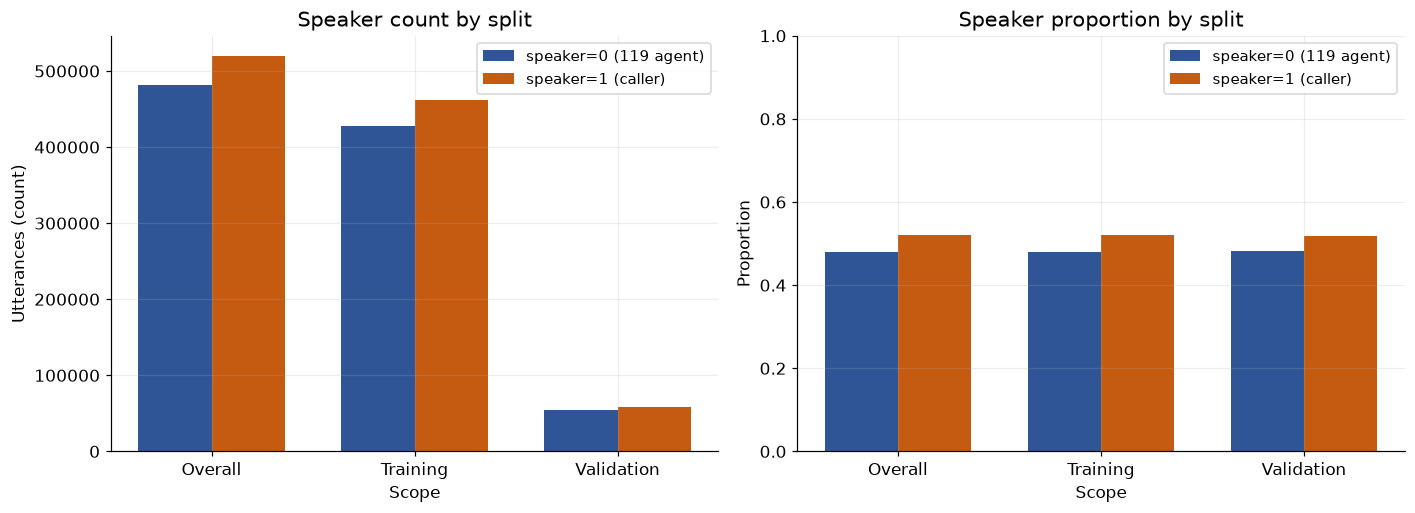

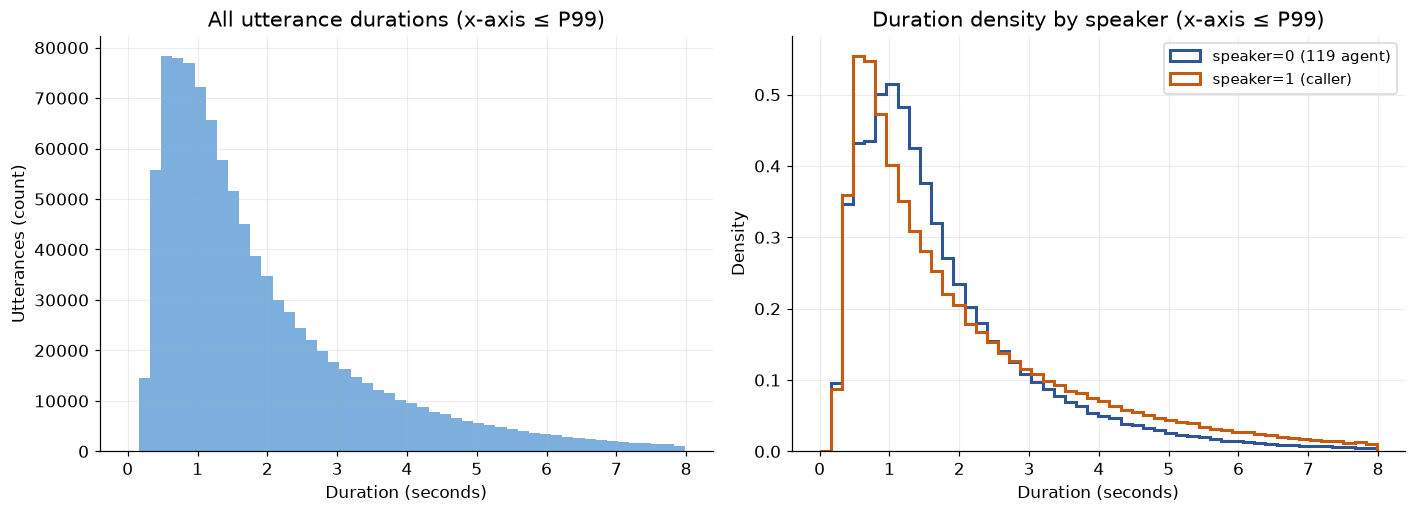

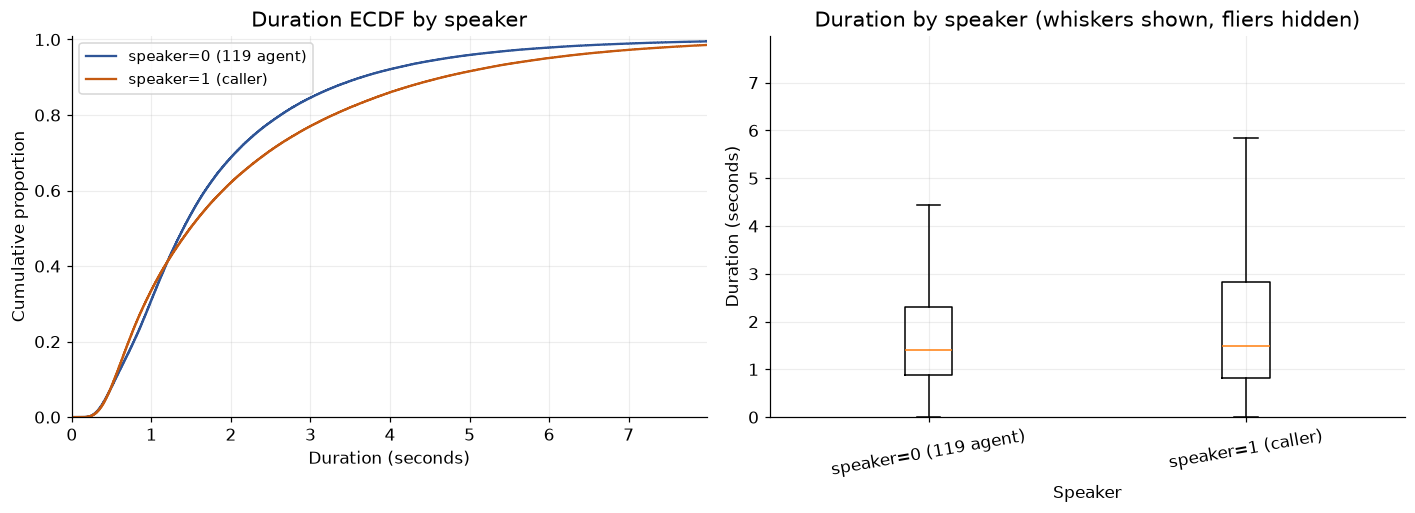

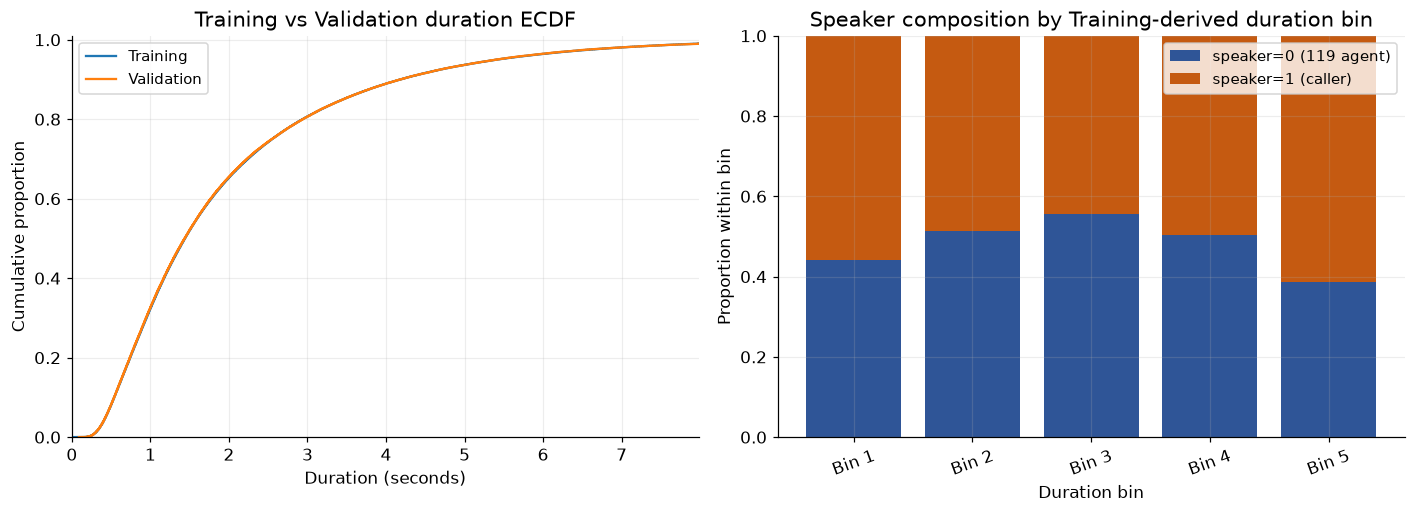

CHECKPOINT B REVIEW: 표와 분포 overlap을 해석한 뒤 Step 6으로 이동하세요.


In [10]:
speaker_order = [0, 1]
target_split_order = ["Overall", *SPLIT_ORDER]
count_pivot = (
    target_distribution.pivot(index="split", columns="speaker", values="count")
    .reindex(target_split_order)
    .fillna(0)
)
proportion_pivot = (
    target_distribution.pivot(index="split", columns="speaker", values="proportion")
    .reindex(target_split_order)
    .fillna(0)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x_positions = np.arange(len(target_split_order))
width = 0.36
for offset, speaker in zip([-width / 2, width / 2], speaker_order):
    axes[0].bar(
        x_positions + offset,
        count_pivot[speaker],
        width=width,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
    axes[1].bar(
        x_positions + offset,
        proportion_pivot[speaker],
        width=width,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
axes[0].set(
    title="Speaker count by split",
    xlabel="Scope",
    ylabel="Utterances (count)",
    xticks=x_positions,
    xticklabels=target_split_order,
)
axes[1].set(
    title="Speaker proportion by split",
    xlabel="Scope",
    ylabel="Proportion",
    xticks=x_positions,
    xticklabels=target_split_order,
)
axes[1].set_ylim(0, 1)
for axis in axes:
    axis.legend()
fig.tight_layout()
maybe_save_figure(fig, "step05_target_distribution.png")
plt.show()

duration_plot_max = float(analysis_utterance_df["duration_sec"].quantile(0.99))
duration_plot_bins = np.linspace(0, duration_plot_max, 51)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
axes[0].hist(
    analysis_utterance_df.loc[
        analysis_utterance_df["duration_sec"] <= duration_plot_max,
        "duration_sec",
    ],
    bins=duration_plot_bins,
    color="#5b9bd5",
    alpha=0.8,
)
axes[0].set(
    title="All utterance durations (x-axis ≤ P99)",
    xlabel="Duration (seconds)",
    ylabel="Utterances (count)",
)
for speaker in speaker_order:
    values = analysis_utterance_df.loc[
        (analysis_utterance_df["speaker"] == speaker)
        & (analysis_utterance_df["duration_sec"] <= duration_plot_max),
        "duration_sec",
    ]
    axes[1].hist(
        values,
        bins=duration_plot_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
axes[1].set(
    title="Duration density by speaker (x-axis ≤ P99)",
    xlabel="Duration (seconds)",
    ylabel="Density",
)
axes[1].legend()
fig.tight_layout()
maybe_save_figure(fig, "step05_duration_histograms.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for speaker in speaker_order:
    values = analysis_utterance_df.loc[
        analysis_utterance_df["speaker"] == speaker, "duration_sec"
    ]
    x_values, y_values = ecdf_xy(values)
    axes[0].step(
        x_values,
        y_values,
        where="post",
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
axes[0].set(
    title="Duration ECDF by speaker",
    xlabel="Duration (seconds)",
    ylabel="Cumulative proportion",
    xlim=(0, duration_plot_max),
    ylim=(0, 1.01),
)
axes[0].legend()
box_values = [
    analysis_utterance_df.loc[
        analysis_utterance_df["speaker"] == speaker, "duration_sec"
    ]
    for speaker in speaker_order
]
axes[1].boxplot(
    box_values,
    tick_labels=[SPEAKER_LABELS[speaker] for speaker in speaker_order],
    showfliers=False,
)
axes[1].set(
    title="Duration by speaker (whiskers shown, fliers hidden)",
    xlabel="Speaker",
    ylabel="Duration (seconds)",
    ylim=(0, duration_plot_max),
)
axes[1].tick_params(axis="x", rotation=10)
fig.tight_layout()
maybe_save_figure(fig, "step05_duration_ecdf_boxplot.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for split in SPLIT_ORDER:
    values = analysis_utterance_df.loc[
        analysis_utterance_df["split"] == split, "duration_sec"
    ]
    x_values, y_values = ecdf_xy(values)
    axes[0].step(
        x_values,
        y_values,
        where="post",
        color=SPLIT_COLORS[split],
        label=split,
    )
axes[0].set(
    title="Training vs Validation duration ECDF",
    xlabel="Duration (seconds)",
    ylabel="Cumulative proportion",
    xlim=(0, duration_plot_max),
    ylim=(0, 1.01),
)
axes[0].legend()

stacked = (
    duration_bin_speaker.pivot(
        index="duration_bin", columns="speaker", values="proportion_within_bin"
    )
    .reindex(duration_bin_labels)
    .fillna(0)
)
bottom = np.zeros(len(stacked))
for speaker in speaker_order:
    axes[1].bar(
        stacked.index.astype(str),
        stacked[speaker],
        bottom=bottom,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
    bottom += stacked[speaker].to_numpy()
axes[1].set(
    title="Speaker composition by Training-derived duration bin",
    xlabel="Duration bin",
    ylabel="Proportion within bin",
)
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend()
fig.tight_layout()
maybe_save_figure(fig, "step05_split_and_duration_bins.png")
plt.show()

print("CHECKPOINT B REVIEW: 표와 분포 overlap을 해석한 뒤 Step 6으로 이동하세요.")


### Step 5 결과 해석

신고자와 119대원의 발화 비율은 약 52:48로 거의 균형적이었다. 따라서 한쪽 데이터가 너무 많은 문제는 없다. 아무 모델 없이 전부 신고자로 예측하면 약 52% 정확도가 나오므로, 이후 모델은 최소한 이보다 확실히 높은 성능을 보여야 한다.

발화 길이는 신고자가 119대원보다 조금 더 긴 경향이 있었다. 특히 긴 발화 구간으로 갈수록 신고자의 비율이 높아지는 모습이 나타났다. 다만 두 집단의 길이 분포가 상당히 겹치므로 발화 길이 하나만으로 신고자와 대원을 구분하기는 어렵다.

Training과 Validation의 발화 길이 분포는 그래프에서 거의 겹쳤다. 따라서 발화 길이와 클래스 비율 측면에서는 Training과 Validation의 차이가 크지 않고, 비슷한 구조를 가진 것으로 보인다.

결론: 발화 길이(duration)는 분류에 도움이 될 가능성이 있는 정보지만, 단독으로 충분한 정보는 아니다. 다음 단계에서 실제 음성을 직접 들어보며 신고자와 대원 사이에 다른 음성적 차이가 있는지 확인한다.

## EDA Step 6 — Blinded Listening & Audio Visualization

**Checkpoint C**

1. **무엇을 측정하는가:** 사람이 실제 발화를 들을 때 역할과 관련된 반복 가능한 청각적 차이를 느끼는지 탐색합니다.
2. **입력:** 기존 BLIND-01~06을 고정하고 speaker 0/1 × Training duration tertile 균형을 보완한 총 12개 sample입니다.
3. **출력 의미:** anonymous ID, duration category, waveform, Mel-spectrogram, Audio widget과 사용자가 직접 채우는 listening note를 제공합니다.
4. **잘못될 수 있는 경우:** 소수 청취자의 인상, 음량·채널·noise 차이, 기억 효과는 일반화되지 않을 수 있습니다. 처음 출력에는 label, call 순서, startAt 절대값을 보이지 않습니다.
5. **다음 판단 연결:** 청취 관찰은 결론이나 causal explanation이 아니라 Step 7에서 수치로 검증할 feature 후보로만 기록합니다.

총 12개를 6개씩 두 batch(시작값 0, 6)로 확인합니다. 12개 × 9개 note를 모두 작성한 뒤에만 별도 reveal 함수를 호출합니다.


Step 6에서는 정답을 모른 채 음성을 직접 들어보고, 신고자와 119대원을 구분할 만한 반복적인 음성 차이가 있는지 찾아본다.

In [ ]:
LISTENING_TOTAL_SAMPLES = 12
LISTENING_PRESERVE_COUNT = 6
LISTENING_BATCH_SIZE = 6
LISTENING_ALLOWED_BATCH_STARTS = (0, 6)
LEGACY_LISTENING_PER_STRATUM = 4
LISTENING_NOTE_FIELDS = [
    "guessed_role",
    "loudness",
    "noise",
    "overlap",
    "speech_style",
    "emotion",
    "channel_feel",
    "silence",
    "memo",
]
PRESERVED_SAMPLE_IDS = [
    f"BLIND-{index:02d}" for index in range(1, LISTENING_PRESERVE_COUNT + 1)
]

_previous_blinded_selection = (
    blinded_selection.copy(deep=True)
    if isinstance(globals().get("blinded_selection"), pd.DataFrame)
    else None
)
_previous_listening_notes = (
    listening_notes.copy(deep=True)
    if isinstance(globals().get("listening_notes"), pd.DataFrame)
    else None
)
if (_previous_blinded_selection is None) != (_previous_listening_notes is None):
    raise RuntimeError(
        "기존 sample과 note 중 하나만 남아 있습니다. 백업을 복원한 뒤 다시 실행하세요."
    )

training_for_listening = analysis_utterance_df.loc[
    analysis_utterance_df["split"] == "Training"
].copy()
listening_q33, listening_q67 = training_for_listening["duration_sec"].quantile(
    [1 / 3, 2 / 3]
)
assert listening_q33 < listening_q67, (
    "short/medium/long 경계를 만들 수 없습니다. duration 분포를 먼저 확인하세요."
)
listening_edges = [-np.inf, listening_q33, listening_q67, np.inf]
listening_labels = ["short", "medium", "long"]
training_for_listening["duration_category"] = pd.cut(
    training_for_listening["duration_sec"],
    bins=listening_edges,
    labels=listening_labels,
    include_lowest=True,
)
LISTENING_STRATA = [
    (speaker, duration_category)
    for speaker in [0, 1]
    for duration_category in listening_labels
]


def build_legacy_first_six(population: pd.DataFrame) -> pd.DataFrame:
    selected_groups = []
    for speaker in [0, 1]:
        for category_index, duration_category in enumerate(listening_labels):
            group = population.loc[
                (population["speaker"] == speaker)
                & (population["duration_category"] == duration_category)
            ]
            take = min(LEGACY_LISTENING_PER_STRATUM, len(group))
            selected_groups.append(
                group.sample(
                    n=take,
                    random_state=EDA_RANDOM_SEED + speaker * 100 + category_index,
                )
            )
    legacy_selection = (
        pd.concat(selected_groups, ignore_index=True)
        .sample(frac=1, random_state=EDA_RANDOM_SEED)
        .reset_index(drop=True)
    )
    legacy_selection["sample_id"] = [
        f"BLIND-{index:02d}" for index in range(1, len(legacy_selection) + 1)
    ]
    return legacy_selection.iloc[:LISTENING_PRESERVE_COUNT].copy()


def select_balanced_additions(
    population: pd.DataFrame,
    preserved: pd.DataFrame,
    *,
    count: int,
) -> pd.DataFrame:
    stratum_counts = {
        stratum: int(
            (
                (preserved["speaker"] == stratum[0])
                & (preserved["duration_category"] == stratum[1])
            ).sum()
        )
        for stratum in LISTENING_STRATA
    }
    candidate_pool = population.loc[
        ~population["record_key"].isin(preserved["record_key"])
    ].copy()
    chosen_rows = []

    for offset in range(count):
        available_strata = [
            stratum
            for stratum in LISTENING_STRATA
            if (
                (candidate_pool["speaker"] == stratum[0])
                & (candidate_pool["duration_category"] == stratum[1])
            ).any()
        ]
        if not available_strata:
            raise RuntimeError("추가 blinded sample 후보가 부족합니다.")

        chosen_stratum = min(
            available_strata,
            key=lambda stratum: (
                stratum_counts[stratum],
                LISTENING_STRATA.index(stratum),
            ),
        )
        candidates = candidate_pool.loc[
            (candidate_pool["speaker"] == chosen_stratum[0])
            & (candidate_pool["duration_category"] == chosen_stratum[1])
        ]
        chosen = candidates.sample(
            n=1,
            random_state=EDA_RANDOM_SEED + 10_000 + offset,
        )
        chosen_rows.append(chosen)
        candidate_pool = candidate_pool.loc[
            ~candidate_pool["record_key"].isin(chosen["record_key"])
        ]
        stratum_counts[chosen_stratum] += 1

    return pd.concat(chosen_rows, ignore_index=True)


if _previous_blinded_selection is not None:
    previous_ids = set(_previous_blinded_selection["sample_id"].astype(str))
    missing_preserved_ids = set(PRESERVED_SAMPLE_IDS) - previous_ids
    if missing_preserved_ids:
        raise RuntimeError(
            f"기존 BLIND-01~06 sample 누락: {sorted(missing_preserved_ids)}"
        )
    preserved_selection = (
        _previous_blinded_selection.set_index("sample_id")
        .loc[PRESERVED_SAMPLE_IDS]
        .reset_index()
        .copy(deep=True)
    )
else:
    preserved_selection = build_legacy_first_six(training_for_listening)

additional_selection = select_balanced_additions(
    training_for_listening,
    preserved_selection,
    count=LISTENING_TOTAL_SAMPLES - LISTENING_PRESERVE_COUNT,
)
additional_selection["sample_id"] = [
    f"BLIND-{index:02d}"
    for index in range(
        LISTENING_PRESERVE_COUNT + 1,
        LISTENING_TOTAL_SAMPLES + 1,
    )
]
blinded_selection = pd.concat(
    [preserved_selection, additional_selection],
    ignore_index=True,
)
assert blinded_selection["sample_id"].tolist() == [
    f"BLIND-{index:02d}" for index in range(1, LISTENING_TOTAL_SAMPLES + 1)
]
assert blinded_selection["record_key"].is_unique

listening_balance_internal = (
    blinded_selection.groupby(
        ["speaker", "duration_category"],
        observed=True,
    )
    .size()
    .reindex(
        pd.MultiIndex.from_tuples(
            LISTENING_STRATA,
            names=["speaker", "duration_category"],
        ),
        fill_value=0,
    )
)

blinded_sample_table = blinded_selection[
    ["sample_id", "duration_category", "duration_sec"]
].copy()
listening_notes = pd.DataFrame(
    {
        "sample_id": blinded_selection["sample_id"],
        **{field: "" for field in LISTENING_NOTE_FIELDS},
    }
)

preserved_note_snapshot = None
if _previous_listening_notes is not None:
    previous_notes = _previous_listening_notes.copy(deep=True)
    if (
        "perceived_loudness" in previous_notes.columns
        and "loudness" not in previous_notes.columns
    ):
        previous_notes = previous_notes.rename(
            columns={"perceived_loudness": "loudness"}
        )
    missing_note_columns = [
        column
        for column in ["sample_id", *LISTENING_NOTE_FIELDS]
        if column not in previous_notes.columns
    ]
    if missing_note_columns:
        raise RuntimeError(
            f"기존 listening_notes column 누락: {missing_note_columns}"
        )
    if previous_notes["sample_id"].duplicated().any():
        raise RuntimeError("기존 listening_notes sample_id가 중복됩니다.")

    preserved_note_snapshot = (
        previous_notes.set_index("sample_id")
        .loc[PRESERVED_SAMPLE_IDS, LISTENING_NOTE_FIELDS]
        .copy(deep=True)
    )
    listening_notes = listening_notes.set_index("sample_id")
    listening_notes.loc[
        PRESERVED_SAMPLE_IDS,
        LISTENING_NOTE_FIELDS,
    ] = preserved_note_snapshot.to_numpy()
    listening_notes = listening_notes.reset_index()

    preserved_notes_after = listening_notes.set_index("sample_id").loc[
        PRESERVED_SAMPLE_IDS,
        LISTENING_NOTE_FIELDS,
    ]
    pd.testing.assert_frame_equal(
        preserved_notes_after,
        preserved_note_snapshot,
        check_dtype=False,
    )
    print("BLIND-01~06 samples and notes preserved: 6/6")

print("Blinded listening set ready: 12 samples; speaker labels remain hidden.")

def load_manifest_segment(row) -> tuple[np.ndarray, int]:
    waveform, sample_rate = read_call_waveform(DATA_ROOT / row.audio_path)
    start_frame = int(row.crop_start_frame)
    end_frame = int(row.crop_end_frame)
    if start_frame < 0 or end_frame <= start_frame or end_frame > len(waveform):
        raise ValueError(
            f"invalid crop frames [{start_frame}, {end_frame}) "
            f"for waveform length {len(waveform)}"
        )
    return waveform[start_frame:end_frame].astype(np.float32, copy=False), sample_rate


def render_blinded_samples(
    selection: pd.DataFrame,
    *,
    start: int = 0,
    batch_size: int = LISTENING_BATCH_SIZE,
) -> None:
    batch = selection.iloc[start : start + batch_size]
    for row in batch.itertuples(index=False):
        segment, sample_rate = load_manifest_segment(row)
        analysis_signal = (
            np.pad(segment, (0, N_FFT - len(segment)))
            if len(segment) < N_FFT
            else segment
        )
        mel_power = librosa.feature.melspectrogram(
            y=analysis_signal,
            sr=sample_rate,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=64,
            power=2.0,
        )
        mel_db = librosa.power_to_db(mel_power, ref=np.max)

        fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
        time_axis = np.arange(len(segment)) / sample_rate
        axes[0].plot(time_axis, segment, color="#2f5597", linewidth=0.8)
        axes[0].set(
            title=f"{row.sample_id} — waveform ({row.duration_category})",
            xlabel="Relative time (seconds)",
            ylabel="Amplitude",
            ylim=(-1.05, 1.05),
        )
        image = librosa.display.specshow(
            mel_db,
            sr=sample_rate,
            hop_length=HOP_LENGTH,
            x_axis="time",
            y_axis="mel",
            ax=axes[1],
            cmap="magma",
        )
        axes[1].set(
            title=f"{row.sample_id} — Mel-spectrogram",
            xlabel="Relative time (seconds)",
            ylabel="Mel frequency (Hz)",
        )
        fig.colorbar(image, ax=axes[1], label="Power (dB)")
        plt.show()
        display(Audio(segment, rate=sample_rate))


def incomplete_listening_sample_ids(
    selection: pd.DataFrame,
    notes: pd.DataFrame,
) -> list[str]:
    missing_columns = [
        column
        for column in ["sample_id", *LISTENING_NOTE_FIELDS]
        if column not in notes.columns
    ]
    if missing_columns:
        raise ValueError(f"listening_notes missing columns: {missing_columns}")
    if notes["sample_id"].duplicated().any():
        raise ValueError("listening_notes sample_id must be unique")

    expected_ids = selection["sample_id"].astype(str).tolist()
    aligned = notes.set_index("sample_id").reindex(expected_ids)
    normalized = aligned[LISTENING_NOTE_FIELDS].fillna("").astype(str)
    normalized = normalized.apply(lambda column: column.str.strip())
    incomplete_mask = normalized.eq("").any(axis=1)
    return normalized.index[incomplete_mask].tolist()


def reveal_blinded_answers(
    selection: pd.DataFrame,
    notes: pd.DataFrame | None = None,
) -> pd.DataFrame:
    expected_ids = [
        f"BLIND-{index:02d}" for index in range(1, LISTENING_TOTAL_SAMPLES + 1)
    ]
    if selection["sample_id"].astype(str).tolist() != expected_ids:
        raise RuntimeError("Reveal requires exactly BLIND-01~12 in order.")
    notes = listening_notes if notes is None else notes
    incomplete_ids = incomplete_listening_sample_ids(selection, notes)
    if incomplete_ids:
        preview = ", ".join(incomplete_ids[:8])
        suffix = " ..." if len(incomplete_ids) > 8 else ""
        raise RuntimeError(
            f"incomplete listening notes: {len(incomplete_ids)}/{len(selection)} "
            f"samples ({preview}{suffix})"
        )
    revealed = selection[["sample_id", "speaker"]].copy()
    revealed["true_role"] = revealed["speaker"].map(SPEAKER_LABELS)
    return revealed[["sample_id", "speaker", "true_role"]]

display(Markdown("### Blinded sample list"))
display_table(blinded_sample_table, max_rows=30)
display(Markdown("### Listening note template"))
display_table(listening_notes, max_rows=30)


BLIND-01~06 samples and notes preserved: 6/6
Blinded listening set ready: 12 samples; speaker labels remain hidden.


### Blinded sample list

,sample_id,duration_category,duration_sec
0,BLIND-01,long,2.664
1,BLIND-02,medium,1.363
2,BLIND-03,short,0.595
3,BLIND-04,medium,1.750
4,BLIND-05,long,4.516
5,BLIND-06,long,2.432
6,BLIND-07,medium,1.079
7,BLIND-08,short,0.472
8,BLIND-09,long,2.070
9,BLIND-10,short,0.322


### Listening note template

,sample_id,guessed_role,loudness,noise,overlap,speech_style,emotion,channel_feel,silence,memo
0,BLIND-01,,,,,,,,,
1,BLIND-02,,,,,,,,,
2,BLIND-03,,,,,,,,,
3,BLIND-04,,,,,,,,,
4,BLIND-05,,,,,,,,,
5,BLIND-06,,,,,,,,,
6,BLIND-07,,,,,,,,,
7,BLIND-08,,,,,,,,,
8,BLIND-09,,,,,,,,,
9,BLIND-10,,,,,,,,,


### 이 그래프에서 확인할 것

- **Waveform:** 상대적 음량, 무음 구간, clipping처럼 보이는 평평한 peak
- **Mel-spectrogram:** 시간에 따른 주파수 에너지, background noise, voiced 구간
- **Audio:** 반복되는 역할 특성이 실제로 들리는지와 예외 sample

그래프와 Audio에는 정답 label이나 통화 내 위치를 표시하지 않습니다. 아래 batch start는 0과 6만 사용하며, 각 렌더링 직후 입력 셀에 note를 기록하세요.


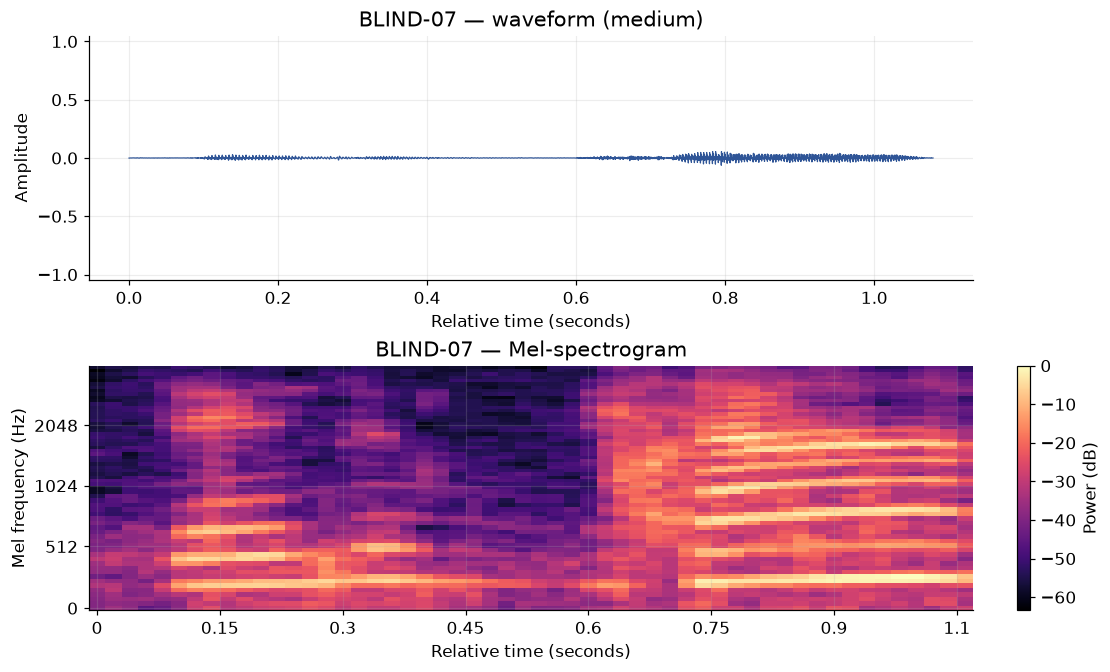

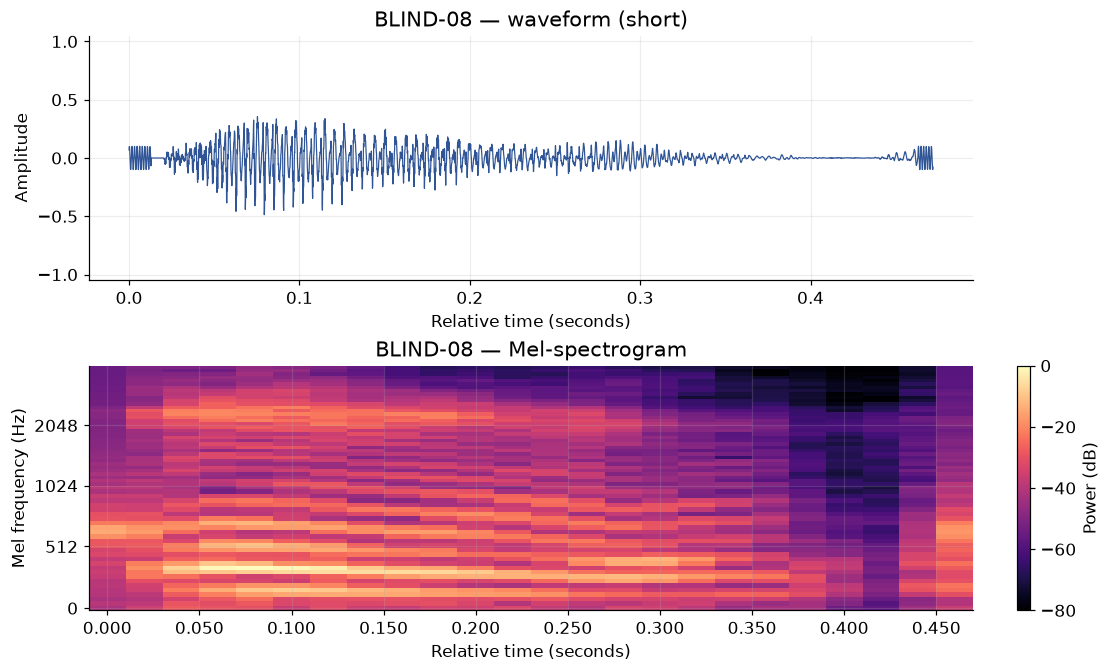

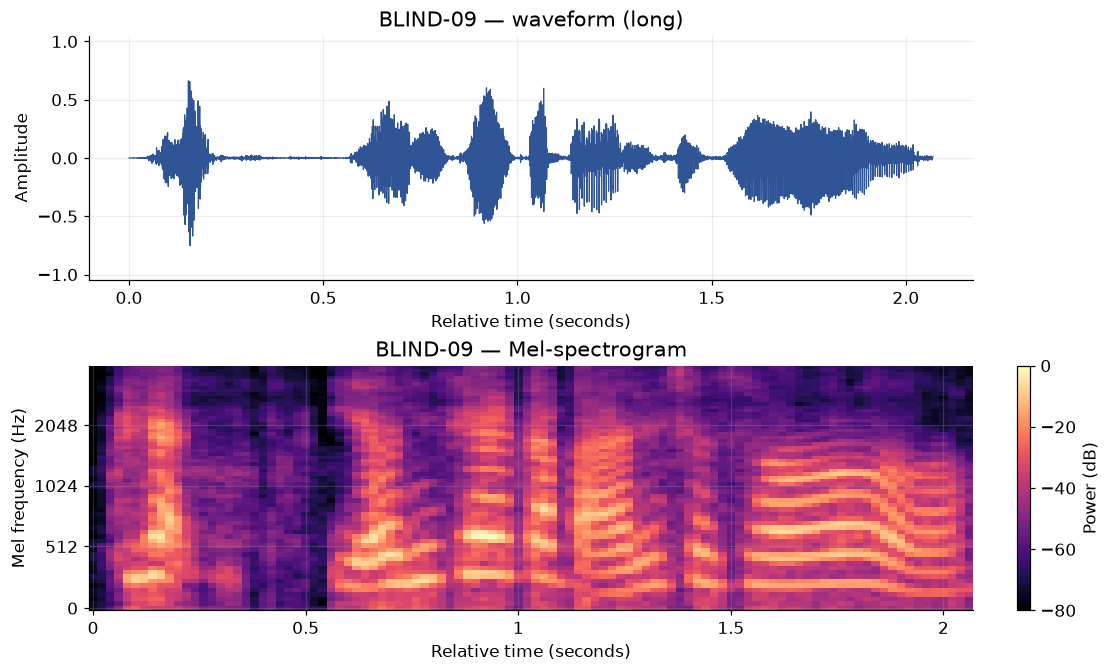

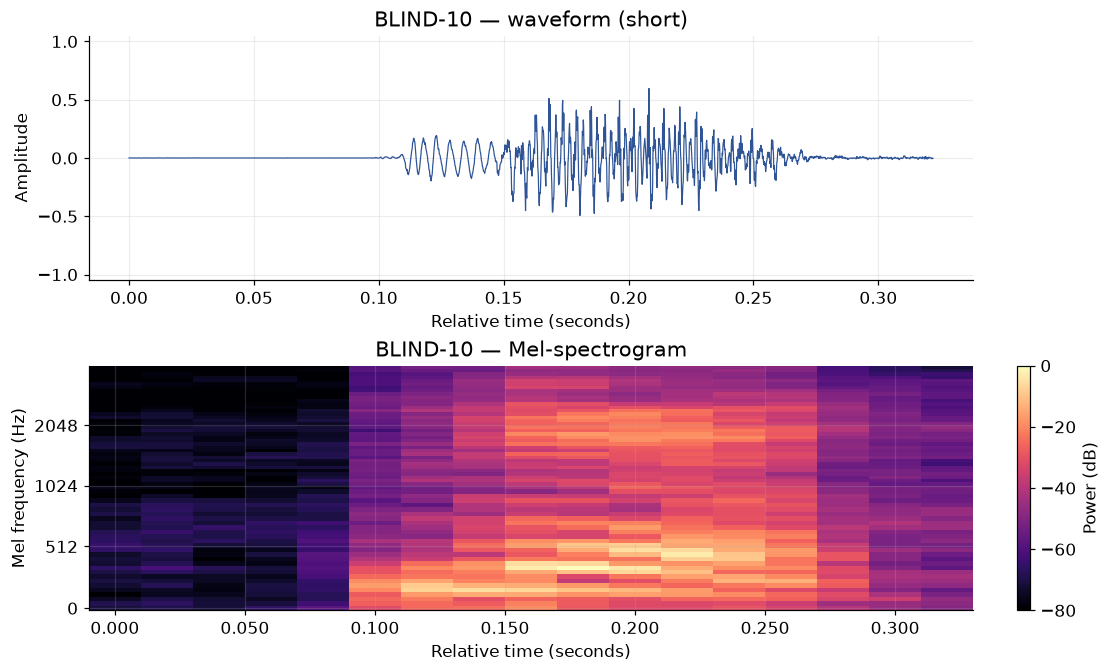

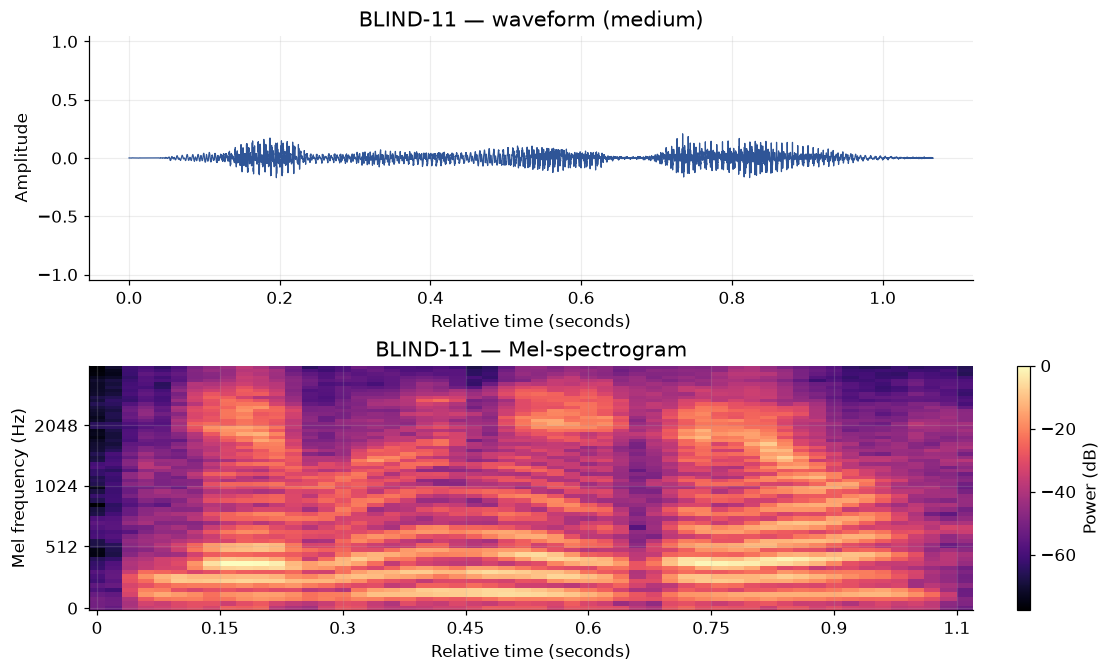

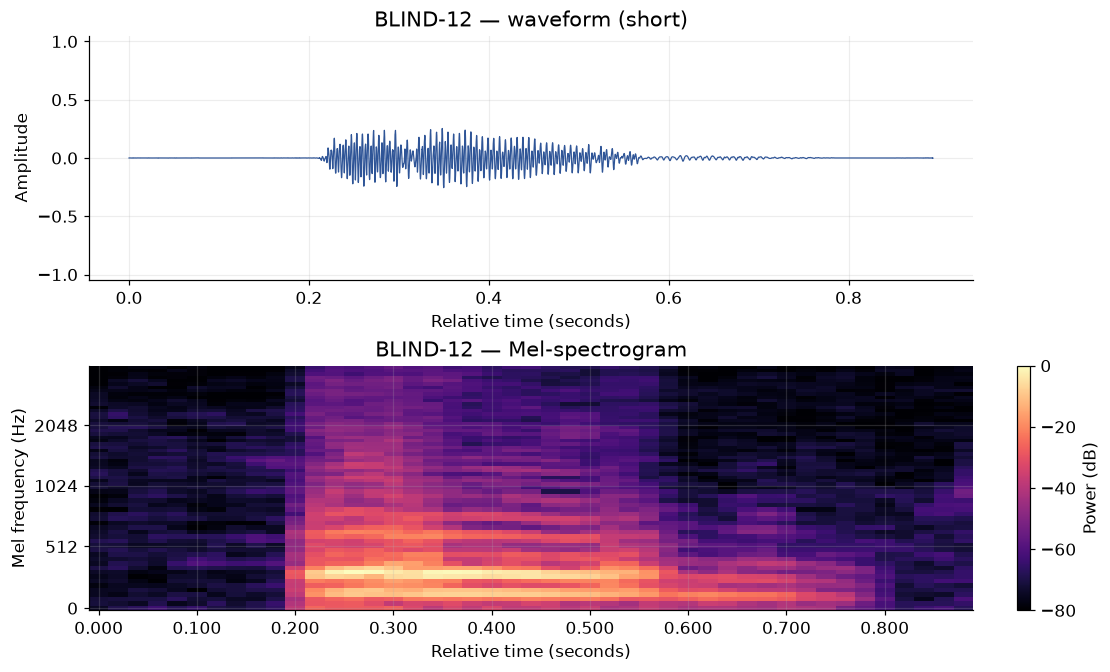

In [22]:
LISTENING_BATCH_START = 6
assert LISTENING_BATCH_START in LISTENING_ALLOWED_BATCH_STARTS, (
    f"LISTENING_BATCH_START는 {LISTENING_ALLOWED_BATCH_STARTS}만 허용됩니다."
)
render_blinded_samples(
    blinded_selection,
    start=LISTENING_BATCH_START,
    batch_size=LISTENING_BATCH_SIZE,
)

# 모든 listening note를 작성한 뒤 별도 셀에서만 실행하세요.
# display_table(reveal_blinded_answers(blinded_selection), max_rows=30)


In [ ]:
LISTENING_FIELD_HINTS = {
    "guessed_role": "caller / 119 agent / unsure",
    "loudness": "low / medium / high",
    "noise": "none / low / high + memo",
    "overlap": "none / possible / clear",
    "speech_style": "short description",
    "emotion": "short description",
    "channel_feel": "clean / phone-like / distant / other",
    "silence": "low / medium / high",
    "memo": "free memo",
}


def record_listening_batch(
    selection: pd.DataFrame,
    notes: pd.DataFrame,
    *,
    start: int,
    batch_size: int = LISTENING_BATCH_SIZE,
    input_fn=input,
) -> pd.DataFrame:
    if start not in LISTENING_ALLOWED_BATCH_STARTS:
        raise ValueError(
            f"start는 {LISTENING_ALLOWED_BATCH_STARTS}만 허용됩니다: {start}"
        )
    batch_ids = selection.iloc[start : start + batch_size]["sample_id"].tolist()
    if not batch_ids:
        raise ValueError(f"No blinded samples at start={start}")
    if notes["sample_id"].duplicated().any():
        raise ValueError("listening_notes sample_id must be unique")

    for sample_id in batch_ids:
        matches = notes.index[notes["sample_id"] == sample_id].tolist()
        if len(matches) != 1:
            raise ValueError(f"Expected one listening_notes row for {sample_id}")
        row_index = matches[0]
        print(f"\n[{sample_id}] 빈 입력은 기존 값을 유지합니다.")
        for field in LISTENING_NOTE_FIELDS:
            current = str(notes.at[row_index, field]).strip()
            current_hint = f" [current: {current}]" if current else ""
            prompt = f"- {field} ({LISTENING_FIELD_HINTS[field]}){current_hint}: "
            entered = input_fn(prompt).strip()
            if entered:
                notes.at[row_index, field] = entered

    remaining = incomplete_listening_sample_ids(selection, notes)
    completed = len(selection) - len(remaining)
    print(f"\nSaved in listening_notes: {completed}/{len(selection)} complete")
    return notes


listening_notes = record_listening_batch(
    blinded_selection,
    listening_notes,
    start=LISTENING_BATCH_START,
    batch_size=LISTENING_BATCH_SIZE,
)
display_table(
    listening_notes.loc[
        listening_notes["sample_id"].isin(




            
            blinded_selection.iloc[
                LISTENING_BATCH_START : LISTENING_BATCH_START + LISTENING_BATCH_SIZE
            ]["sample_id"]
        )
    ],
    max_rows=LISTENING_BATCH_SIZE,
)



[BLIND-07] 빈 입력은 기존 값을 유지합니다.


KeyboardInterrupt: Interrupted by user

In [29]:
restore_notes = {
    "BLIND-01": ["caller", "low", "high", "none", "calm", "calm", "noisy", "low", "주변이 시끄러움"],
    "BLIND-02": ["unsure", "medium", "high", "none", "unclear", "none", "none", "none", "사람 목소리 들리지않음"],
    "BLIND-03": ["unsure", "medium", "none", "none", "calm", "neutral", "clean", "low", "뒷부분 끊기는느낌"],
    "BLIND-04": ["caller", "medium", "none", "none", "neutral", "neutral", "clean", "low", "음질 선명"],
    "BLIND-05": ["unsure", "low", "mid", "yes", "fast", "urgent", "noisy", "low", "두사람 목소리 모두 들림"],
    "BLIND-06": ["119 agent", "high", "none", "none", "fast", "calm", "clean", "low", "두사람의 대화가 선명하게 들림"],
}

cols = [
    "guessed_role", "loudness", "noise", "overlap",
    "speech_style", "emotion", "channel_feel", "silence", "memo"
]

for sample_id, values in restore_notes.items():
    listening_notes.loc[
        listening_notes["sample_id"] == sample_id, cols
    ] = values

display(listening_notes)

,sample_id,guessed_role,loudness,noise,overlap,speech_style,emotion,channel_feel,silence,memo
0,BLIND-01,caller,low,high,none,calm,calm,noisy,low,주변이 시끄러움
1,BLIND-02,unsure,medium,high,none,unclear,none,none,none,사람 목소리 들리지않음
2,BLIND-03,unsure,medium,none,none,calm,neutral,clean,low,뒷부분 끊기는느낌
3,BLIND-04,caller,medium,none,none,neutral,neutral,clean,low,음질 선명
4,BLIND-05,unsure,low,mid,yes,fast,urgent,noisy,low,두사람 목소리 모두 들림
5,BLIND-06,119 agent,high,none,none,fast,calm,clean,low,두사람의 대화가 선명하게 들림
6,BLIND-07,unsure,low,medium,none,calm,calm,muffled,low,끊겨서 들림
7,BLIND-08,unsure,high,low,none,calm,calm,muffled,low,잘 모르겠음
8,BLIND-09,unsure,high,low,none,calm,tense,clean,low,당황한 듯한 목소리
9,BLIND-10,unsure,high,none,none,calm,calm,clean,low,X


### Step 7 결과 해석

정답을 가린 상태에서 12개 음성을 직접 청취했다. 여러 샘플에서 음량, 잡음, 음질, 말투, 긴박감 등의 차이는 느껴졌지만, unsure 판단도 많아 사람이 듣는 것만으로 신고자와 119대원을 명확히 구분하기는 어려웠다. 따라서 청취 중 발견한 음향적 차이는 결론으로 사용하지 않고, Step 7에서 실제 음향 feature를 계산해 수치로 검증한다

## EDA Step 7 — Acoustic Feature EDA

**Checkpoint D**

1. **무엇을 측정하는가:** 실제 cropped waveform에서 energy, silence, time-frequency, MFCC, clipping 특성을 추출해 speaker별 분포를 비교합니다.
2. **입력:** split × speaker × duration stratum을 고정 seed로 표본화한 약 1,200개 utterance입니다. 각 stratum은 최대 100개이며 sample_weight로 원래 stratum 규모를 기록합니다.
3. **출력 의미:** acoustic_feature_df는 실패 행도 제거하지 않고 extraction_ok, error, missing을 보존합니다. weighted summary는 stratified sampling으로 달라진 구성비를 원 모집단에 가깝게 복원합니다.
4. **잘못될 수 있는 경우:** 표본 오차, duration confounding, noise/channel 차이, feature extraction failure가 speaker 차이처럼 보일 수 있습니다. MFCC 전체를 무차별 plotting하지 않습니다. F0는 기본 비활성화하며 켤 경우 voiced frame 부족과 실패를 0으로 대체하지 않습니다.
5. **다음 판단 연결:** 단일 feature overlap, failure, 품질 지표를 확인한 뒤 call leakage, outlier, Train–Validation shift와 multivariate 관계를 평가합니다.

기존 dcc_data의 call당 1회 WAV read와 MFCC 설정(N_FFT=512, hop=160, n_mfcc=20)은 재사용합니다. 기존 baseline extractor는 NaN/Inf를 0으로 바꾸므로 EDA에서는 실패를 드러내는 별도 extractor를 사용합니다.


Training/Validation과 신고자/119대원, 짧은/중간/긴 발화가 골고루 들어가도록 약 1,200개를 표본으로 뽑아서 실제 WAV에서 음향 특징을 계산

- energy → 소리가 얼마나 큰가
- silence → 무음 구간이 얼마나 많은가
- time-frequency → 시간에 따라 소리의 주파수 성분이 어떻게 변하는가
- MFCC → 사람 목소리의 음색·발성 특성을 요약한 숫자
- clipping → 녹음이 너무 커서 소리가 찌그러진 부분이 있는가

In [30]:
ACOUSTIC_PER_STRATUM = 100
SILENCE_THRESHOLD_DBFS = -40.0
CLIPPING_AMPLITUDE = 0.999
INCLUDE_F0 = False
REBUILD_ACOUSTIC_CACHE = False

ACOUSTIC_CACHE_PATH = CACHE_DIR / "acoustic_features_sample_v1.parquet"
ACOUSTIC_FAILURE_CACHE_PATH = CACHE_DIR / "acoustic_failures_sample_v1.parquet"
ACOUSTIC_META_PATH = CACHE_DIR / "acoustic_features_meta_v1.json"

CORE_ACOUSTIC_FEATURES = [
    "duration_sec",
    "rms",
    "rms_frame_std",
    "peak_amplitude",
    "amplitude_dynamic_range",
    "silence_ratio",
    "zcr",
    "spectral_centroid",
    "spectral_bandwidth",
    "spectral_rolloff",
    "spectral_flatness",
    "clipping_ratio",
]
MFCC_MEAN_FEATURES = [f"mfcc_{index + 1:02d}_mean" for index in range(N_MFCC)]
MFCC_STD_FEATURES = [f"mfcc_{index + 1:02d}_std" for index in range(N_MFCC)]
F0_FEATURES = ["f0_median_hz", "f0_iqr_hz", "f0_voiced_fraction"]
ACOUSTIC_FEATURE_COLUMNS = [
    *CORE_ACOUSTIC_FEATURES,
    *MFCC_MEAN_FEATURES,
    *MFCC_STD_FEATURES,
    *F0_FEATURES,
]

acoustic_population = analysis_utterance_df.copy()
acoustic_population["duration_stratum"] = pd.cut(
    acoustic_population["duration_sec"],
    bins=listening_edges,
    labels=listening_labels,
    include_lowest=True,
)

sampled_strata = []
stratum_summary_rows = []
for split in SPLIT_ORDER:
    for speaker in [0, 1]:
        for stratum_index, duration_stratum in enumerate(listening_labels):
            group = acoustic_population.loc[
                (acoustic_population["split"] == split)
                & (acoustic_population["speaker"] == speaker)
                & (acoustic_population["duration_stratum"] == duration_stratum)
            ]
            take = min(ACOUSTIC_PER_STRATUM, len(group))
            if take == 0:
                warnings.warn(
                    f"빈 acoustic stratum: {split}, speaker={speaker}, "
                    f"duration={duration_stratum}"
                )
                continue
            sampled = group.sample(
                n=take,
                random_state=(
                    EDA_RANDOM_SEED
                    + SPLIT_ORDER.index(split) * 1_000
                    + speaker * 100
                    + stratum_index
                ),
            ).copy()
            sampled["population_stratum_count"] = len(group)
            sampled["sample_stratum_count"] = take
            sampled["sample_weight"] = len(group) / take
            sampled_strata.append(sampled)
            stratum_summary_rows.append(
                {
                    "split": split,
                    "speaker": speaker,
                    "duration_stratum": duration_stratum,
                    "population_count": len(group),
                    "sample_count": take,
                    "sample_weight": len(group) / take,
                }
            )

acoustic_sample_df = (
    pd.concat(sampled_strata, ignore_index=True)
    .sample(frac=1, random_state=EDA_RANDOM_SEED)
    .reset_index(drop=True)
)
acoustic_stratum_summary = pd.DataFrame(stratum_summary_rows)

display(Markdown("### Acoustic sampling design"))
display_table(acoustic_stratum_summary, max_rows=20)


def extract_signal_features(
    segment: np.ndarray,
    sample_rate: int,
    *,
    include_f0: bool,
) -> dict:
    signal = np.asarray(segment, dtype=np.float32).reshape(-1)
    if len(signal) == 0:
        raise ValueError("empty crop")
    if not np.isfinite(signal).all():
        raise ValueError("waveform contains NaN or Inf")

    analysis_signal = (
        np.pad(signal, (0, N_FFT - len(signal)))
        if len(signal) < N_FFT
        else signal
    )
    absolute_signal = np.abs(signal)
    frame_rms = librosa.feature.rms(
        y=analysis_signal,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    zcr = librosa.feature.zero_crossing_rate(
        y=analysis_signal,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    centroid = librosa.feature.spectral_centroid(
        y=analysis_signal,
        sr=sample_rate,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    bandwidth = librosa.feature.spectral_bandwidth(
        y=analysis_signal,
        sr=sample_rate,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    rolloff = librosa.feature.spectral_rolloff(
        y=analysis_signal,
        sr=sample_rate,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    flatness = librosa.feature.spectral_flatness(
        y=analysis_signal,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )[0]
    mfcc = librosa.feature.mfcc(
        y=analysis_signal,
        sr=sample_rate,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )

    silence_amplitude = 10 ** (SILENCE_THRESHOLD_DBFS / 20)
    features = {
        "rms": float(np.sqrt(np.mean(np.square(signal, dtype=np.float64)))),
        "rms_frame_std": float(np.std(frame_rms)),
        "peak_amplitude": float(absolute_signal.max()),
        "amplitude_dynamic_range": float(
            np.quantile(absolute_signal, 0.95)
            - np.quantile(absolute_signal, 0.05)
        ),
        "silence_ratio": float(np.mean(frame_rms <= silence_amplitude)),
        "zcr": float(np.mean(zcr)),
        "spectral_centroid": float(np.mean(centroid)),
        "spectral_bandwidth": float(np.mean(bandwidth)),
        "spectral_rolloff": float(np.mean(rolloff)),
        "spectral_flatness": float(np.mean(flatness)),
        "clipping_ratio": float(np.mean(absolute_signal >= CLIPPING_AMPLITUDE)),
    }
    features.update(
        {
            name: float(value)
            for name, value in zip(MFCC_MEAN_FEATURES, mfcc.mean(axis=1))
        }
    )
    features.update(
        {
            name: float(value)
            for name, value in zip(MFCC_STD_FEATURES, mfcc.std(axis=1))
        }
    )

    core_values = np.asarray(list(features.values()), dtype=float)
    if not np.isfinite(core_values).all():
        raise ValueError("core acoustic feature contains NaN or Inf")

    features.update({name: np.nan for name in F0_FEATURES})
    features["f0_status"] = "not_requested"
    if include_f0:
        try:
            f0, voiced_flag, _ = librosa.pyin(
                analysis_signal,
                sr=sample_rate,
                fmin=65.0,
                fmax=min(500.0, sample_rate / 2 - 1),
                frame_length=N_FFT,
                hop_length=HOP_LENGTH,
            )
            voiced_f0 = f0[np.isfinite(f0)]
            features["f0_voiced_fraction"] = float(np.mean(voiced_flag))
            if len(voiced_f0) >= 3:
                features["f0_median_hz"] = float(np.median(voiced_f0))
                features["f0_iqr_hz"] = float(
                    np.quantile(voiced_f0, 0.75)
                    - np.quantile(voiced_f0, 0.25)
                )
                features["f0_status"] = "ok"
            else:
                features["f0_status"] = "insufficient_voiced_frames"
        except Exception as exc:
            features["f0_status"] = f"failed: {type(exc).__name__}: {exc}"

    return features


### Acoustic sampling design

,split,speaker,duration_stratum,population_count,sample_count,sample_weight
0,Training,0,short,137127,100,1371.27
1,Training,0,medium,162882,100,1628.82
2,Training,0,long,127152,100,1271.52
3,Training,1,short,159356,100,1593.56
4,Training,1,medium,133611,100,1336.11
5,Training,1,long,169230,100,1692.30
6,Validation,0,short,17516,100,175.16
7,Validation,0,medium,20345,100,203.45
8,Validation,0,long,15984,100,159.84
9,Validation,1,short,20152,100,201.52


In [31]:
def extract_acoustic_sample(sample_frame: pd.DataFrame) -> pd.DataFrame:
    feature_rows = []
    grouped = sample_frame.groupby(["split", "audio_path"], sort=False, observed=True)

    for call_number, ((split, audio_path), group) in enumerate(grouped, start=1):
        waveform = None
        sample_rate = None
        audio_error = ""
        try:
            waveform, sample_rate = read_call_waveform(DATA_ROOT / audio_path)
        except Exception as exc:
            audio_error = f"{type(exc).__name__}: {exc}"

        for row in group.itertuples(index=False):
            result = {
                "split": row.split,
                "call_id": row.call_id,
                "record_key": row.record_key,
                "utterance_id": row.utterance_id,
                "speaker": int(row.speaker),
                "duration_stratum": str(row.duration_stratum),
                "duration_sec": float(row.duration_sec),
                "audio_path": row.audio_path,
                "json_path": row.json_path,
                "crop_start_frame": int(row.crop_start_frame),
                "crop_end_frame": int(row.crop_end_frame),
                "population_stratum_count": int(row.population_stratum_count),
                "sample_stratum_count": int(row.sample_stratum_count),
                "sample_weight": float(row.sample_weight),
                "sample_rate_actual": np.nan,
                "extraction_ok": False,
                "extraction_error": "",
                "f0_status": "not_attempted",
            }
            result.update(
                {
                    feature: (
                        float(row.duration_sec)
                        if feature == "duration_sec"
                        else np.nan
                    )
                    for feature in ACOUSTIC_FEATURE_COLUMNS
                }
            )

            if waveform is None:
                result["extraction_error"] = f"audio_open: {audio_error}"
                feature_rows.append(result)
                continue

            try:
                if (
                    result["crop_start_frame"] < 0
                    or result["crop_end_frame"] <= result["crop_start_frame"]
                    or result["crop_end_frame"] > len(waveform)
                ):
                    raise ValueError(
                        f"invalid frames [{result['crop_start_frame']}, "
                        f"{result['crop_end_frame']}) for {len(waveform)}"
                    )
                segment = waveform[
                    result["crop_start_frame"] : result["crop_end_frame"]
                ]
                features = extract_signal_features(
                    segment,
                    sample_rate,
                    include_f0=INCLUDE_F0,
                )
                result.update(features)
                result["sample_rate_actual"] = sample_rate
                result["extraction_ok"] = True
            except Exception as exc:
                result["extraction_error"] = (
                    f"feature: {type(exc).__name__}: {exc}"
                )
            feature_rows.append(result)

        if call_number % 100 == 0 or call_number == len(grouped):
            print(f"acoustic progress: {call_number:,}/{len(grouped):,} calls")

    return pd.DataFrame(feature_rows)


sample_key_signature = hashlib.sha256(
    "\n".join(sorted(acoustic_sample_df["record_key"])).encode("utf-8")
).hexdigest()
acoustic_cache_meta = {
    "schema_version": CACHE_SCHEMA_VERSION,
    "source_signature": source_signature,
    "sample_key_signature": sample_key_signature,
    "random_seed": EDA_RANDOM_SEED,
    "per_stratum": ACOUSTIC_PER_STRATUM,
    "strata": ["split", "speaker", "duration_tertile"],
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "n_mfcc": N_MFCC,
    "silence_threshold_dbfs": SILENCE_THRESHOLD_DBFS,
    "clipping_amplitude": CLIPPING_AMPLITUDE,
    "include_f0": INCLUDE_F0,
    "feature_columns": ACOUSTIC_FEATURE_COLUMNS,
}

acoustic_cache_exists = all(
    path.is_file()
    for path in [
        ACOUSTIC_CACHE_PATH,
        ACOUSTIC_FAILURE_CACHE_PATH,
        ACOUSTIC_META_PATH,
    ]
)
cached_acoustic_meta = None
if acoustic_cache_exists:
    try:
        cached_acoustic_meta = json.loads(
            ACOUSTIC_META_PATH.read_text(encoding="utf-8")
        )
    except Exception as exc:
        print(f"Acoustic cache metadata를 읽지 못해 재생성합니다: {exc}")

use_acoustic_cache = (
    not REBUILD_ACOUSTIC_CACHE
    and acoustic_cache_exists
    and cached_acoustic_meta == acoustic_cache_meta
)

if use_acoustic_cache:
    acoustic_feature_df = pd.read_parquet(ACOUSTIC_CACHE_PATH)
    acoustic_failure_df = pd.read_parquet(ACOUSTIC_FAILURE_CACHE_PATH)
    print("Acoustic cache reused:", ACOUSTIC_CACHE_PATH)
else:
    acoustic_feature_df = extract_acoustic_sample(acoustic_sample_df)
    acoustic_failure_df = acoustic_feature_df.loc[
        ~acoustic_feature_df["extraction_ok"],
        [
            "split",
            "call_id",
            "record_key",
            "utterance_id",
            "audio_path",
            "extraction_error",
        ],
    ].copy()
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    acoustic_feature_df.to_parquet(ACOUSTIC_CACHE_PATH, index=False)
    acoustic_failure_df.to_parquet(ACOUSTIC_FAILURE_CACHE_PATH, index=False)
    ACOUSTIC_META_PATH.write_text(
        json.dumps(acoustic_cache_meta, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Acoustic cache written:", ACOUSTIC_CACHE_PATH)

assert len(acoustic_feature_df) == len(acoustic_sample_df), (
    "표본 행과 acoustic feature 행 수가 다릅니다."
)
assert set(acoustic_feature_df["record_key"]) == set(acoustic_sample_df["record_key"]), (
    "표본 record_key와 acoustic cache record_key가 다릅니다."
)


def weighted_quantile(values, weights, quantiles) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    quantiles = np.asarray(quantiles, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[keep], weights[keep]
    if len(values) == 0:
        return np.full(len(quantiles), np.nan)
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    cumulative = np.cumsum(weights) - 0.5 * weights
    cumulative = cumulative / weights.sum()
    return np.interp(quantiles, cumulative, values)


def weighted_mean_std(values, weights) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[keep], weights[keep]
    if len(values) == 0:
        return np.nan, np.nan
    mean = np.average(values, weights=weights)
    variance = np.average((values - mean) ** 2, weights=weights)
    return float(mean), float(np.sqrt(variance))


feature_summary_rows = []
for speaker in [0, 1]:
    speaker_frame = acoustic_feature_df.loc[
        acoustic_feature_df["speaker"] == speaker
    ]
    extraction_failure_count = int((~speaker_frame["extraction_ok"]).sum())
    for feature in ACOUSTIC_FEATURE_COLUMNS:
        feature_values = pd.to_numeric(speaker_frame[feature], errors="coerce")
        valid = speaker_frame["extraction_ok"] & np.isfinite(feature_values)
        values = feature_values.loc[valid].to_numpy(dtype=float)
        weights = speaker_frame.loc[valid, "sample_weight"].to_numpy(dtype=float)
        mean, std = weighted_mean_std(values, weights)
        q01, q05, q25, q50, q75, q95, q99 = weighted_quantile(
            values,
            weights,
            [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99],
        )
        feature_summary_rows.append(
            {
                "speaker": speaker,
                "speaker_label": SPEAKER_LABELS[speaker],
                "feature": feature,
                "sample_rows": len(speaker_frame),
                "valid_count": int(valid.sum()),
                "missing_count": int((~np.isfinite(feature_values)).sum()),
                "extraction_failure_count": extraction_failure_count,
                "weighted_mean": mean,
                "weighted_std": std,
                "weighted_p01": q01,
                "weighted_p05": q05,
                "weighted_q1": q25,
                "weighted_median": q50,
                "weighted_q3": q75,
                "weighted_iqr": q75 - q25,
                "weighted_p95": q95,
                "weighted_p99": q99,
            }
        )

feature_summary_df = pd.DataFrame(feature_summary_rows)
extraction_summary = (
    acoustic_feature_df.groupby(["split", "speaker"], observed=True)
    .agg(
        sample_rows=("record_key", "size"),
        extraction_failures=("extraction_ok", lambda values: int((~values).sum())),
        extraction_successes=("extraction_ok", lambda values: int(values.sum())),
    )
    .reset_index()
)
extraction_summary["failure_rate"] = (
    extraction_summary["extraction_failures"] / extraction_summary["sample_rows"]
)

display(Markdown("### Extraction summary"))
display_table(extraction_summary, max_rows=20)
display(Markdown("### Extraction failure samples"))
display_table(acoustic_failure_df, max_rows=20)
display(Markdown("### Weighted feature summary"))
display_table(feature_summary_df, max_rows=200)


acoustic progress: 100/1,150 calls
acoustic progress: 200/1,150 calls
acoustic progress: 300/1,150 calls
acoustic progress: 400/1,150 calls
acoustic progress: 500/1,150 calls
acoustic progress: 600/1,150 calls
acoustic progress: 700/1,150 calls
acoustic progress: 800/1,150 calls
acoustic progress: 900/1,150 calls
acoustic progress: 1,000/1,150 calls
acoustic progress: 1,100/1,150 calls
acoustic progress: 1,150/1,150 calls
Acoustic cache written: C:\Users\YW\Study\02_Projects\DCC_2026\prelim\tmp\mission2_eda\acoustic_features_sample_v1.parquet


### Extraction summary

,split,speaker,sample_rows,extraction_failures,extraction_successes,failure_rate
0,Training,0,300,0,300,0.0
1,Training,1,300,0,300,0.0
2,Validation,0,300,0,300,0.0
3,Validation,1,300,0,300,0.0


### Extraction failure samples

,split,call_id,record_key,utterance_id,audio_path,extraction_error


### Weighted feature summary

,speaker,speaker_label,feature,sample_rows,valid_count,missing_count,extraction_failure_count,weighted_mean,weighted_std,weighted_p01,weighted_p05,weighted_q1,weighted_median,weighted_q3,weighted_iqr,weighted_p95,weighted_p99
0,0,speaker=0 (119 agent),duration_sec,600,600,0,0,1.8187,1.3486,0.2829,0.4314,0.9292,1.4400,2.2530,1.3238,4.4933,6.8224
1,0,speaker=0 (119 agent),rms,600,600,0,0,0.0829,0.0520,0.0071,0.0143,0.0410,0.0728,0.1176,0.0767,0.1797,0.2192
2,0,speaker=0 (119 agent),rms_frame_std,600,600,0,0,0.0441,0.0291,0.0018,0.0032,0.0203,0.0408,0.0666,0.0463,0.0933,0.1156
3,0,speaker=0 (119 agent),peak_amplitude,600,600,0,0,0.5076,0.2854,0.0472,0.0666,0.2589,0.5065,0.7523,0.4934,0.9475,1.0000
4,0,speaker=0 (119 agent),amplitude_dynamic_range,600,600,0,0,0.1822,0.1216,0.0156,0.0310,0.0808,0.1546,0.2666,0.1858,0.4069,0.4933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,1,speaker=1 (caller),mfcc_19_std,600,600,0,0,7.9044,3.9933,1.5552,2.0696,5.3659,6.8148,10.7484,5.3825,15.1756,17.3627
106,1,speaker=1 (caller),mfcc_20_std,600,600,0,0,7.8247,4.2898,0.7323,1.0539,5.3217,7.1353,11.0527,5.7310,14.9828,17.8614
107,1,speaker=1 (caller),f0_median_hz,600,0,600,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
108,1,speaker=1 (caller),f0_iqr_hz,600,0,600,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


총 1,200개 표본에서 음향 feature 추출을 수행했고, Training/Validation 및 신고자/119대원 모두 추출 실패가 0건이었다. 따라서 이후 speaker별 feature 차이를 비교할 때 feature 추출 실패율 차이에 의한 왜곡 가능성은 확인되지 않았다. 1,200개 발화는 1,150개의 고유 통화에 포함되어 있어 WAV는 통화당 한 번씩 읽었으며, 계산 결과는 parquet cache로 저장되었다. 약 55개의 음향 feature를 신고자와 119대원 각각 600개 표본에서 요약했다. 일반 음향 feature는 모두 정상 계산되었고 추출 실패는 없었다. F0 관련 feature는 이번 EDA 설정에서 비활성화되어 NaN으로 남았으며 오류는 아니다. 이제 같은 feature에서 신고자와 119대원의 분포가 실제로 얼마나 다른지 비교해야 한다.

### 이 그래프에서 확인할 것

- **Histogram:** weighted 분포 형태와 tail
- **ECDF:** speaker별 전체 overlap과 shift
- **Boxplot:** stratified sample의 median, IQR, extreme value
- **MFCC heatmap:** coefficient별 standardized difference의 방향과 상대적 크기

축은 각 feature의 P01~P99로 제한하되 원본 통계는 clipping하지 않습니다. 큰 standardized difference도 duration·channel·noise confounding을 배제하지 못하므로 성능 개선 근거로 확정하지 않습니다.


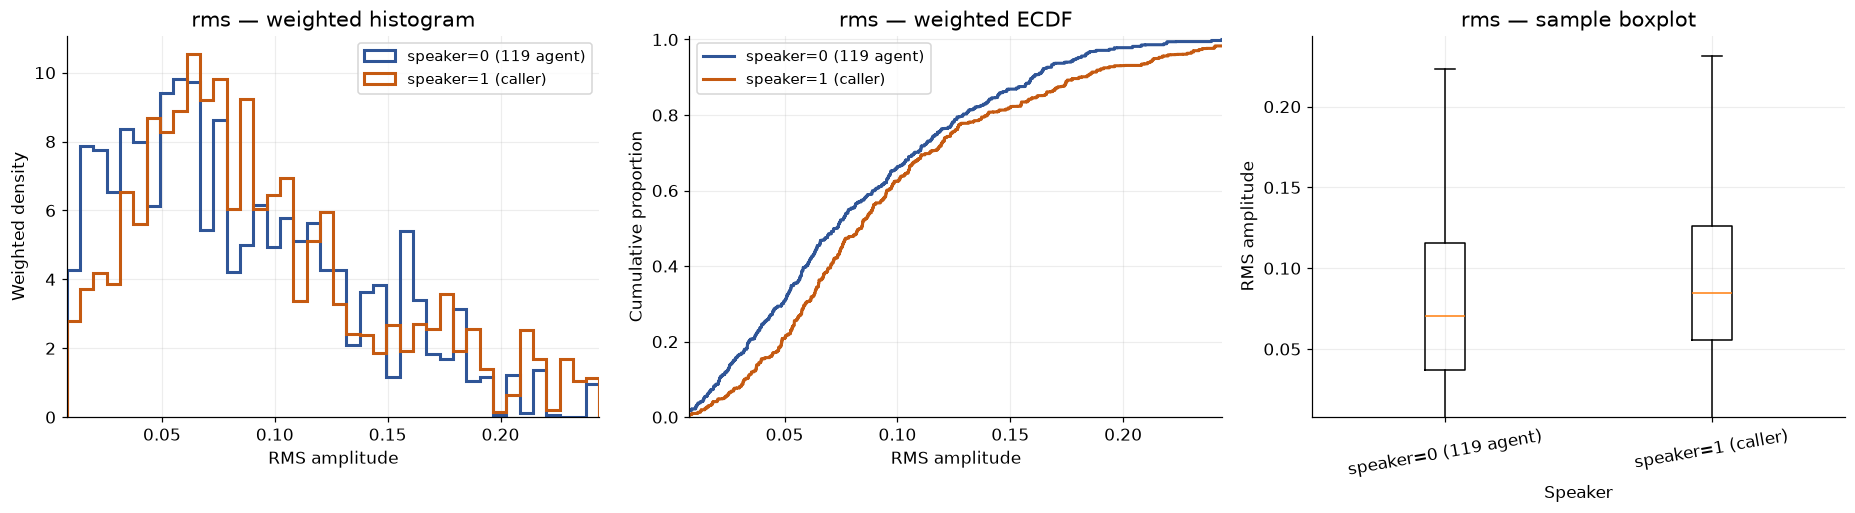

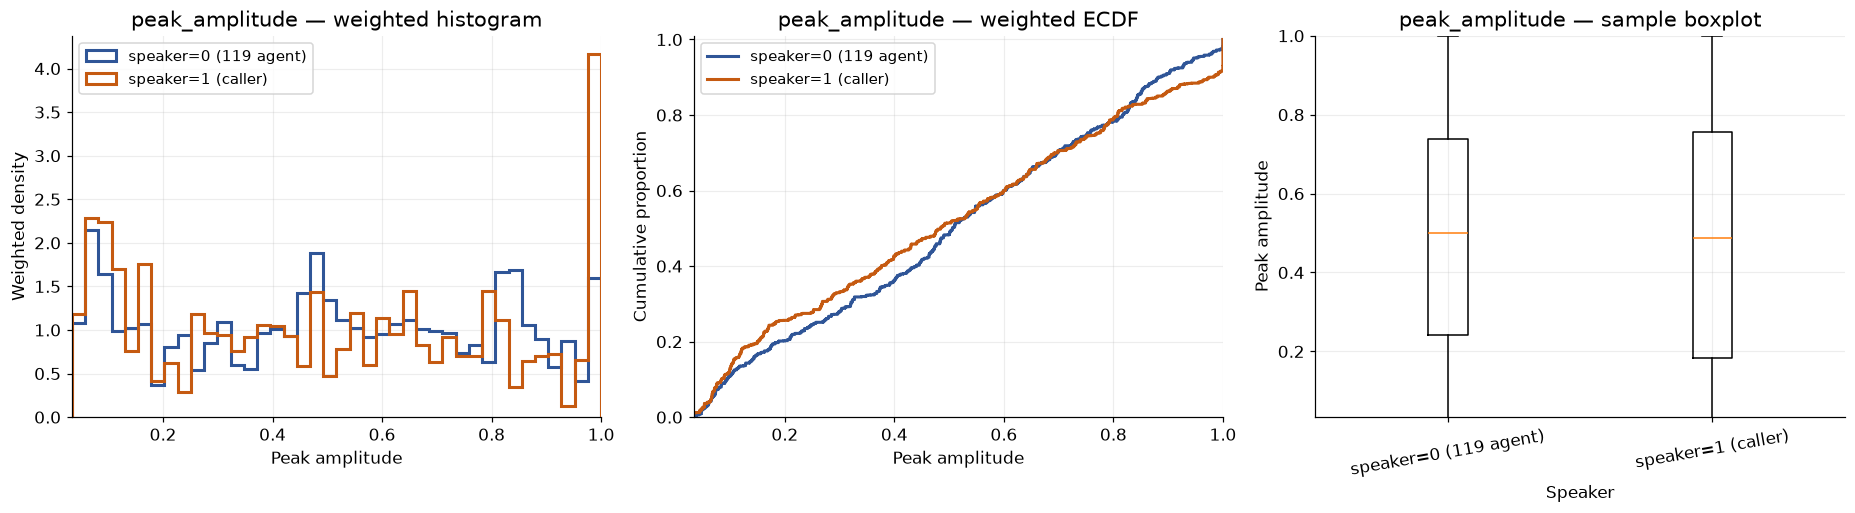

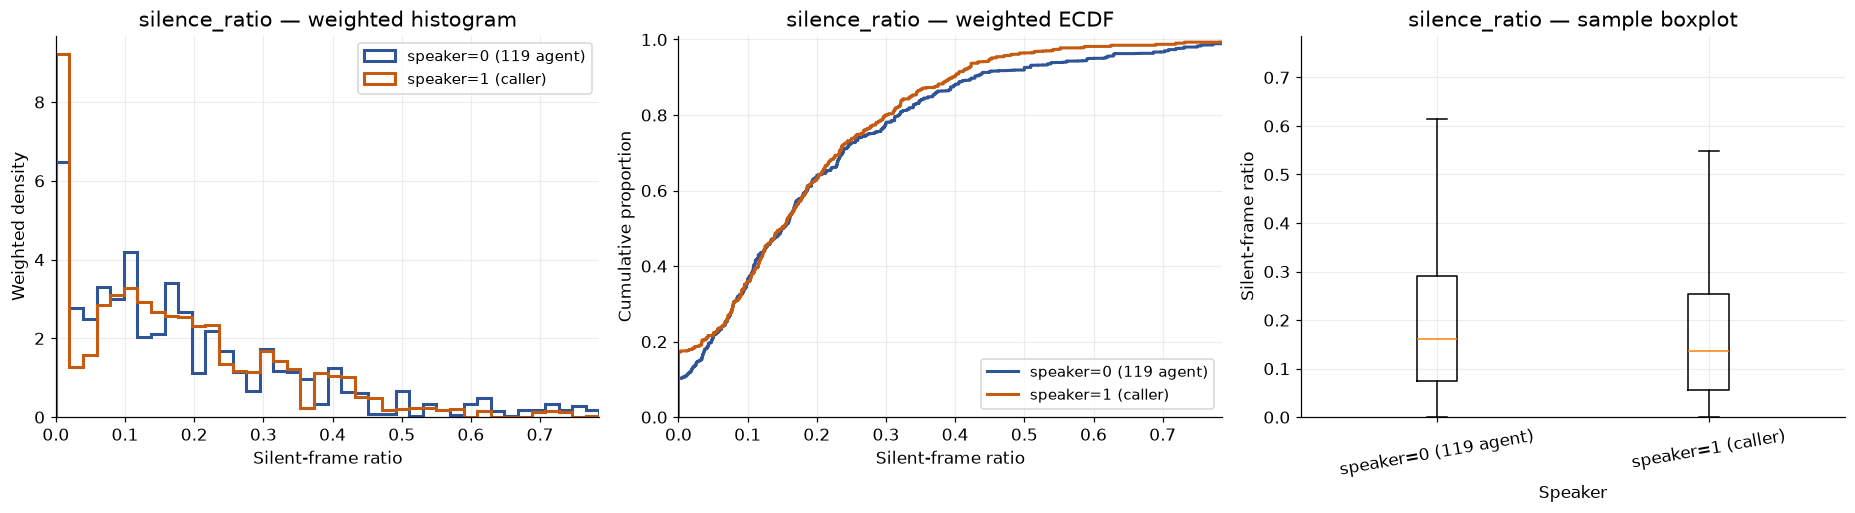

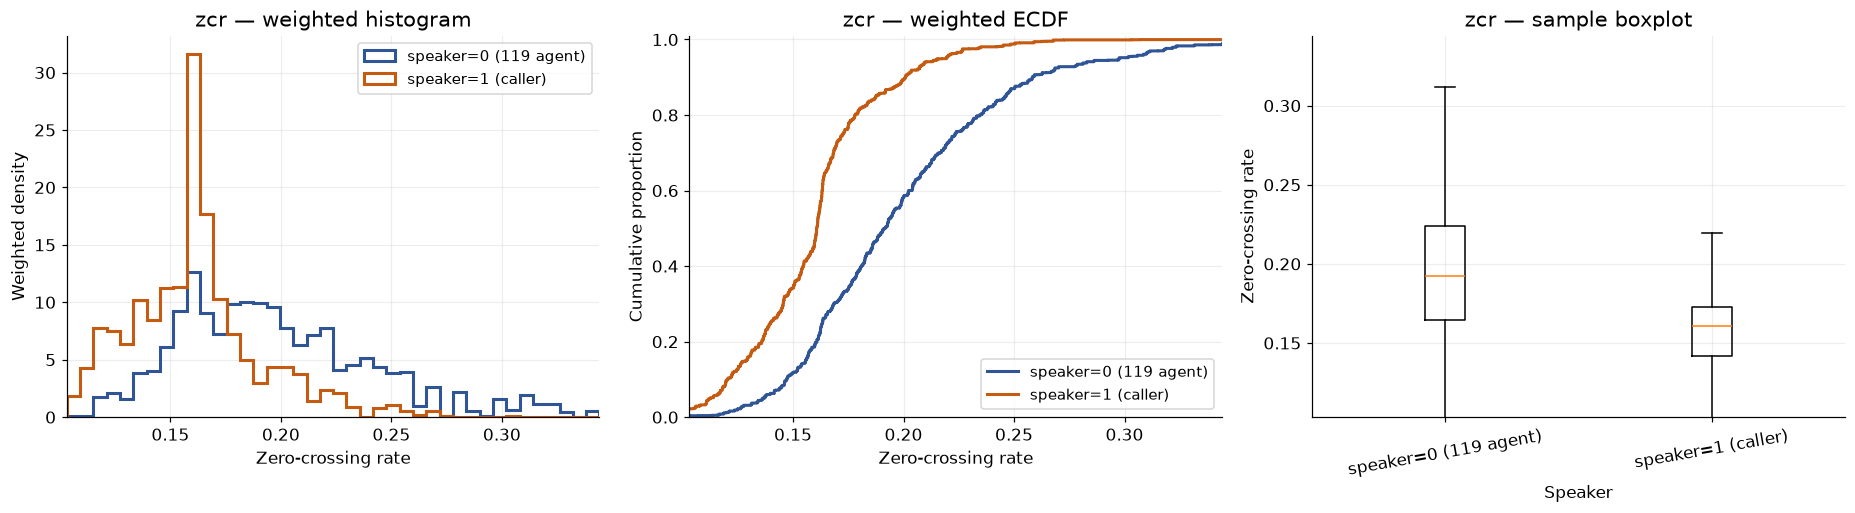

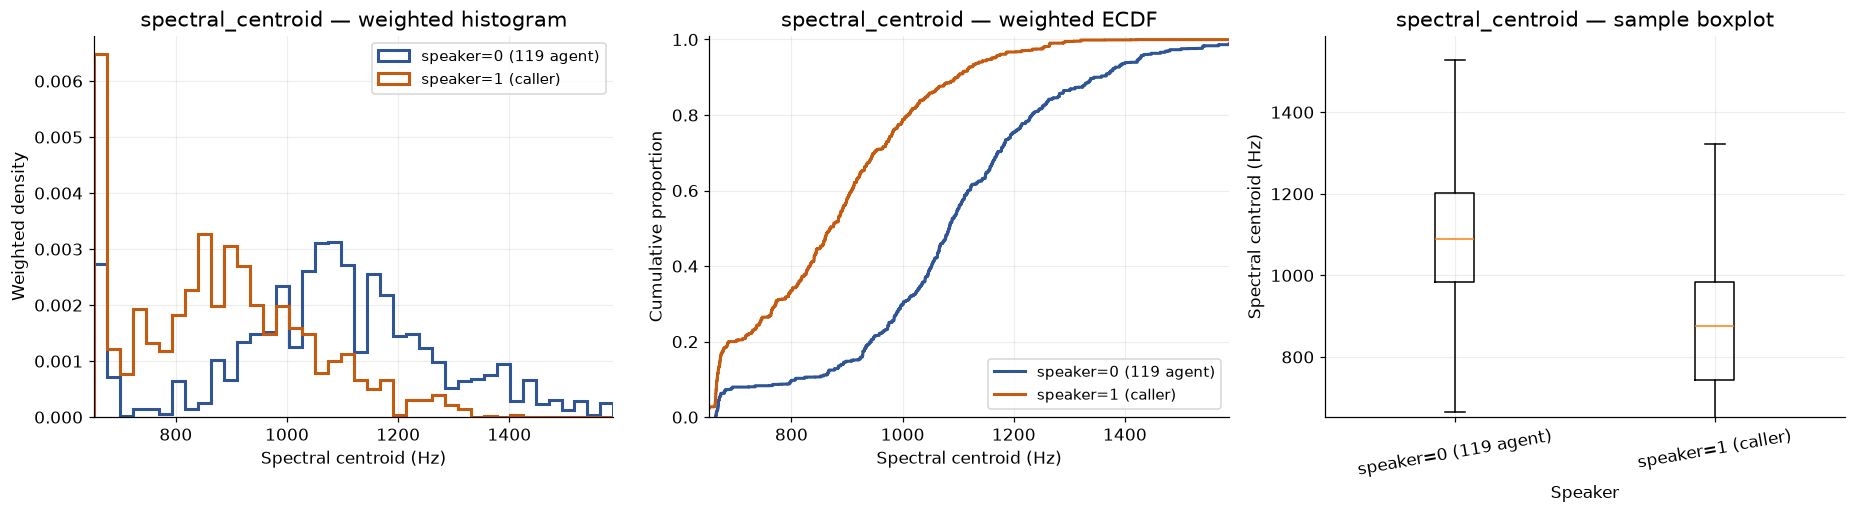

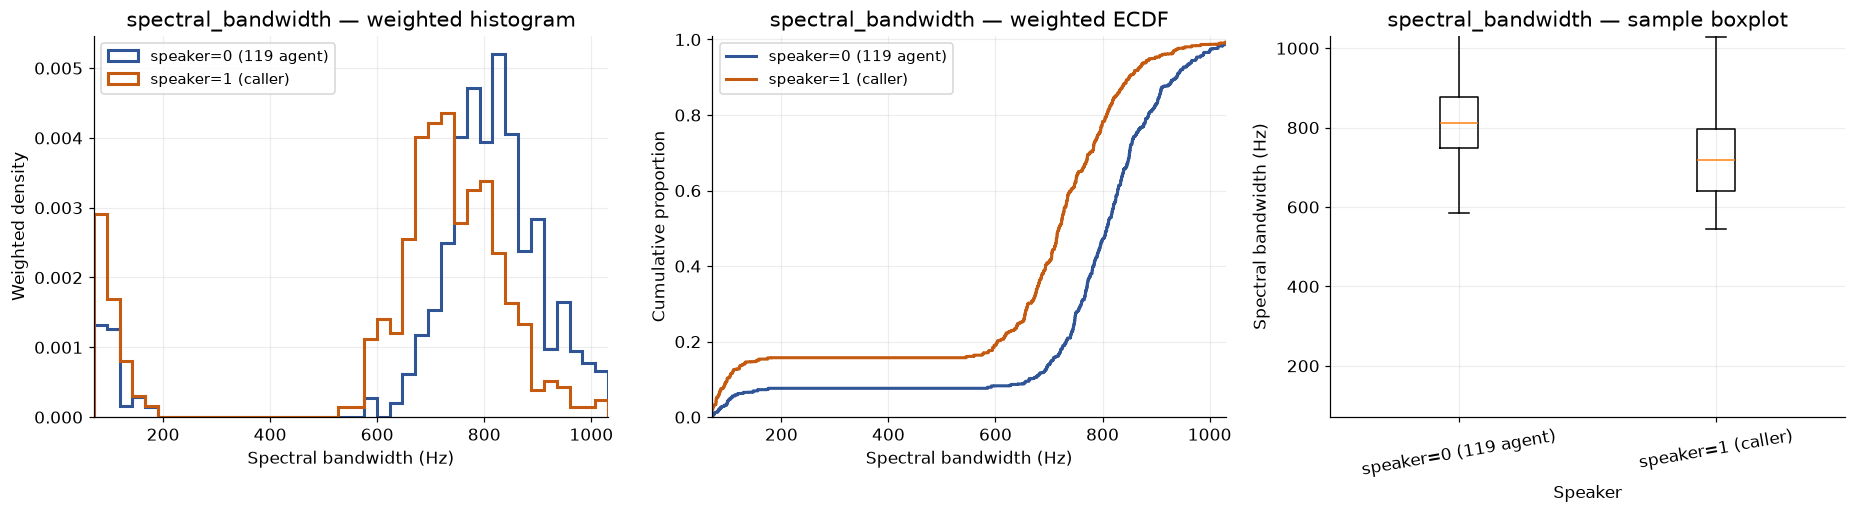

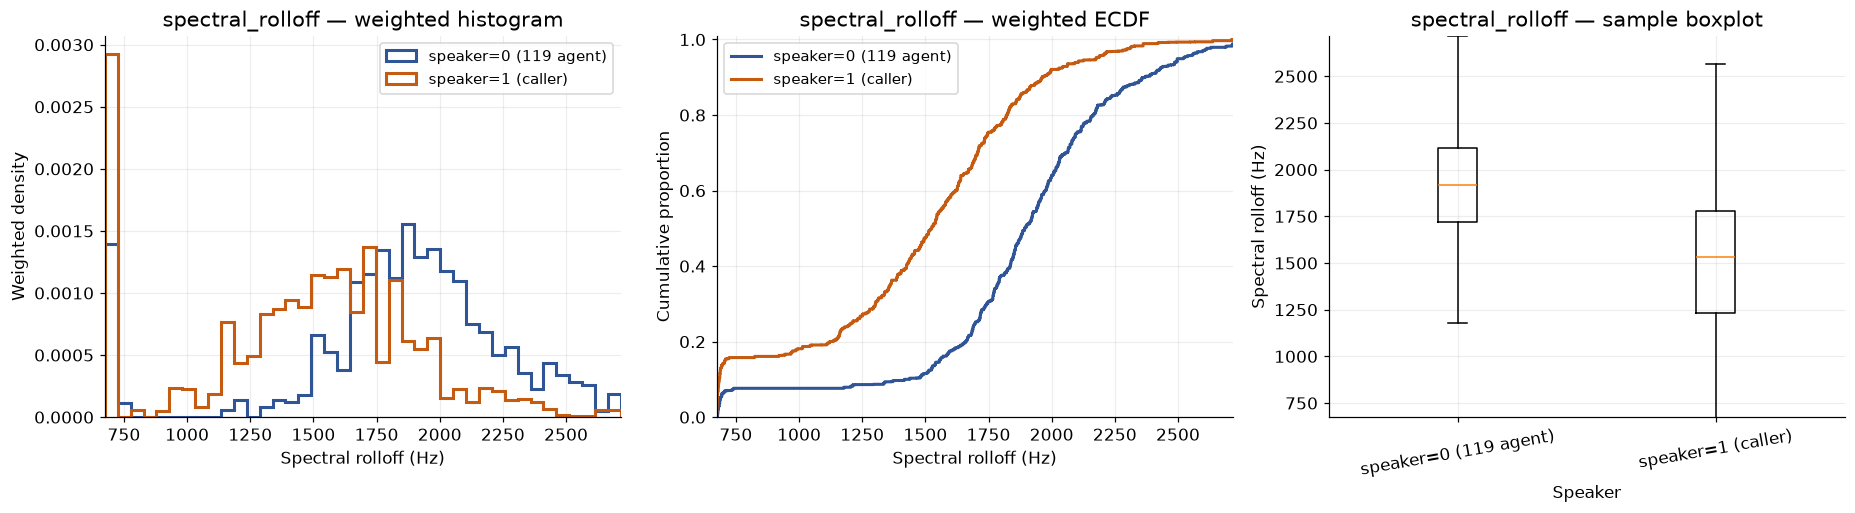

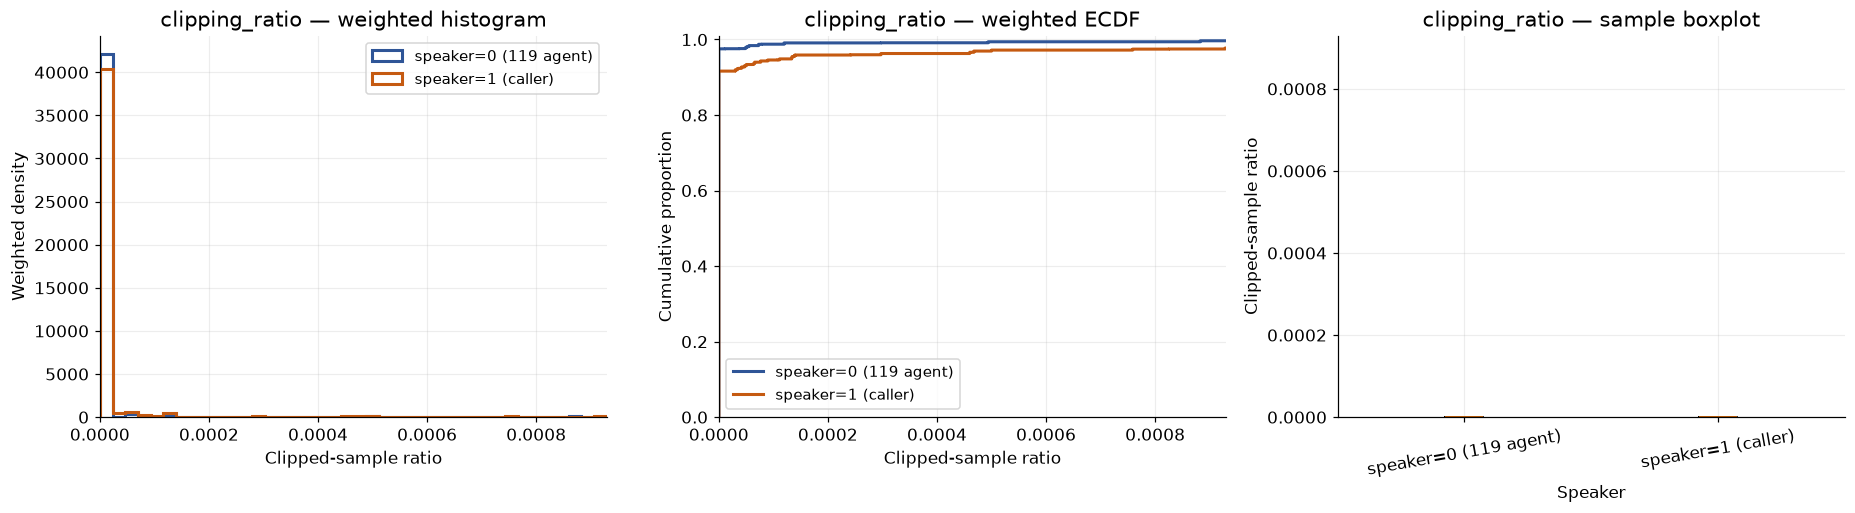

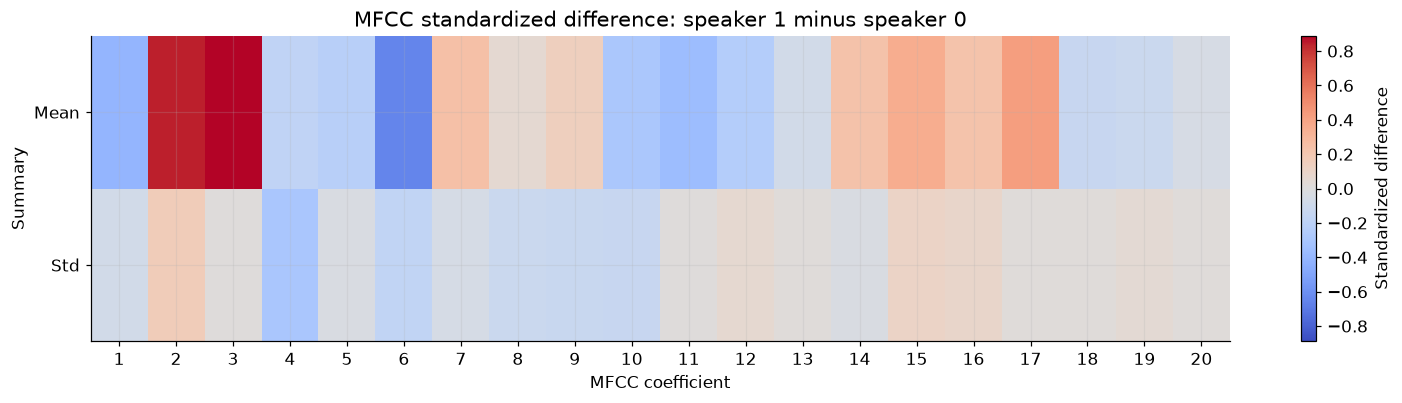

### MFCC coefficients with the largest sample difference

,feature,standardized_difference_speaker1_minus_speaker0,absolute_difference
2,mfcc_03_mean,0.8891,0.8891
1,mfcc_02_mean,0.8441,0.8441
5,mfcc_06_mean,-0.6482,0.6482
16,mfcc_17_mean,0.4170,0.4170


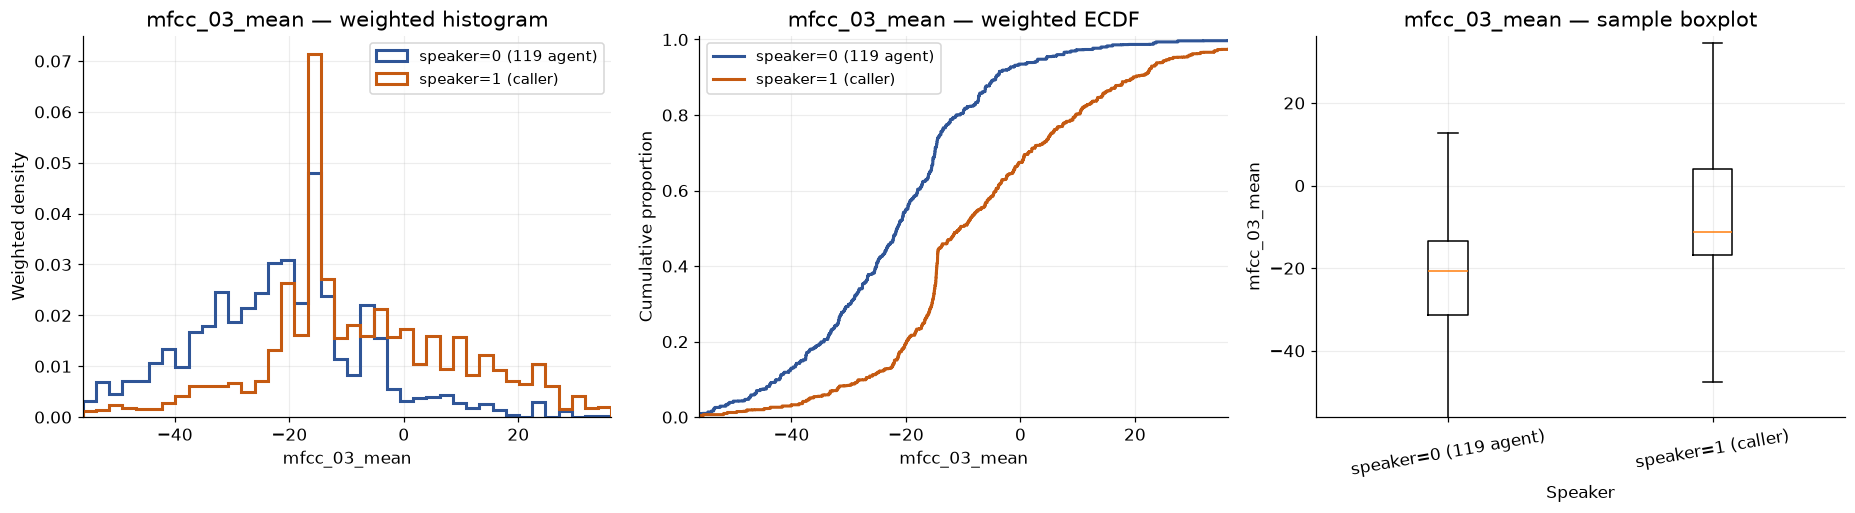

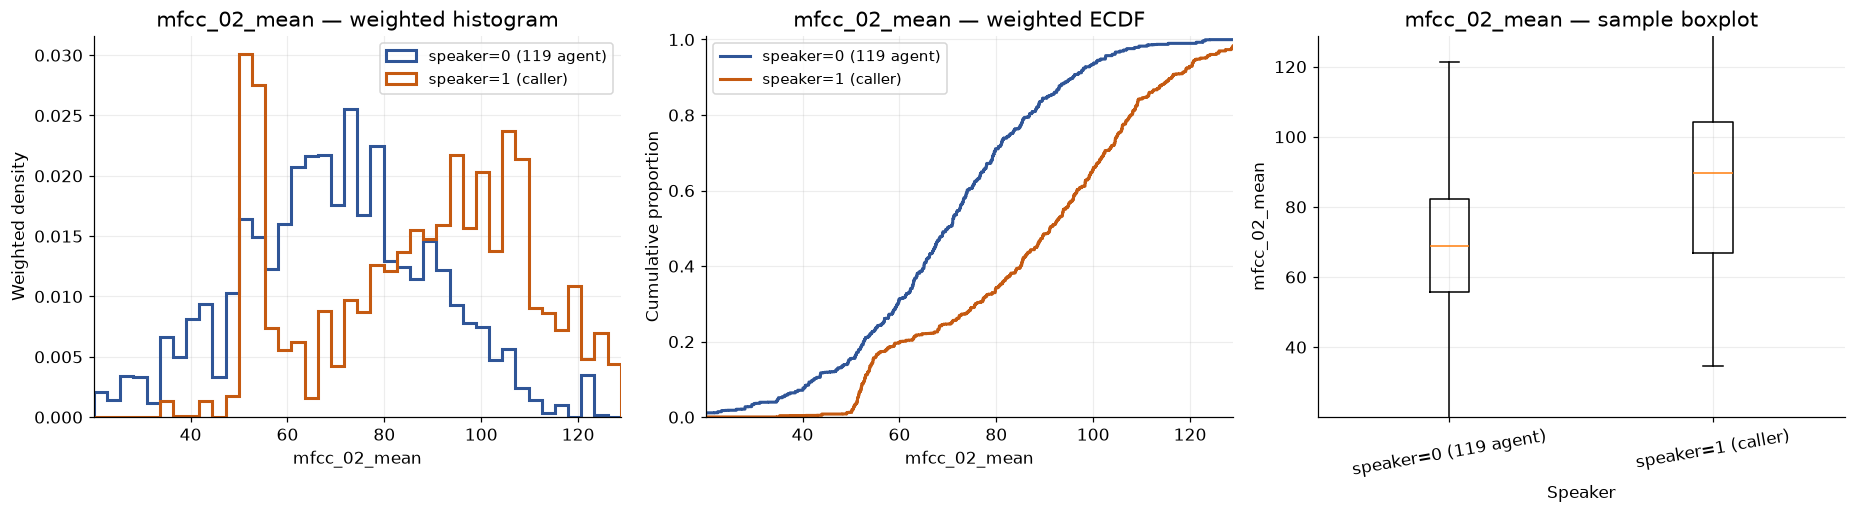

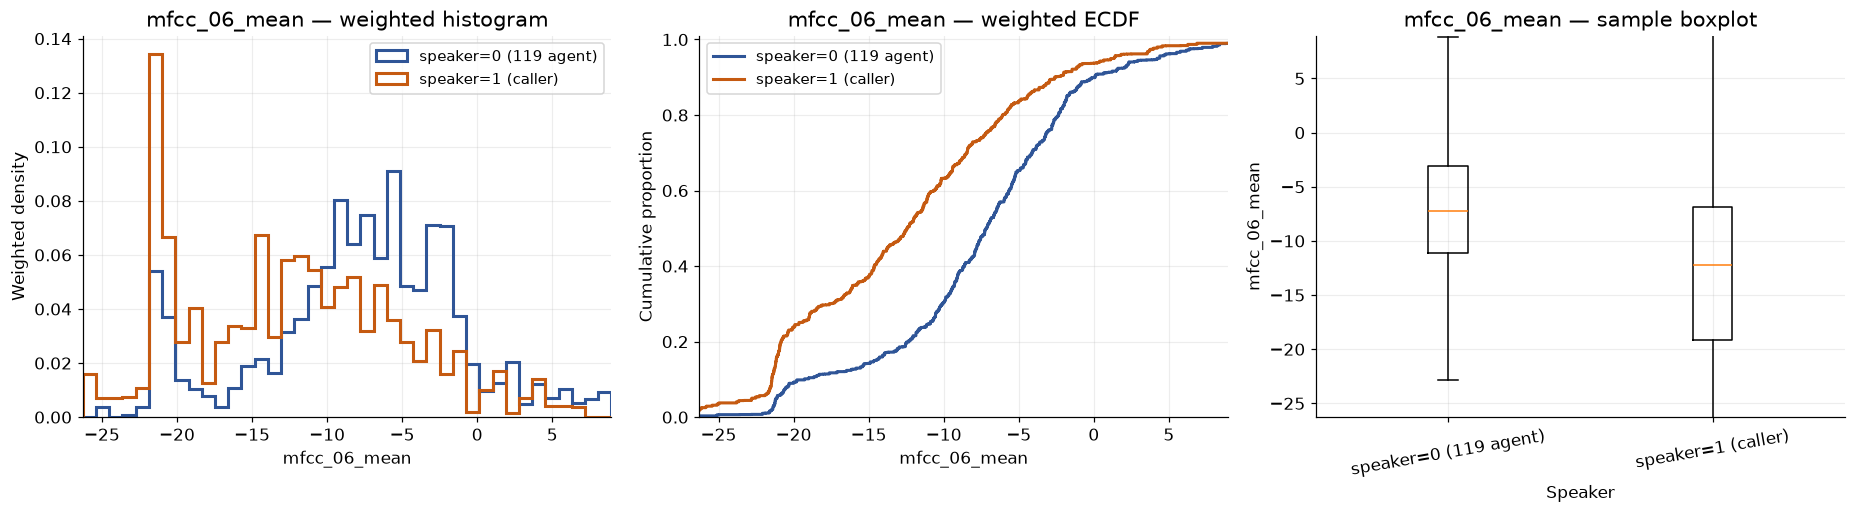

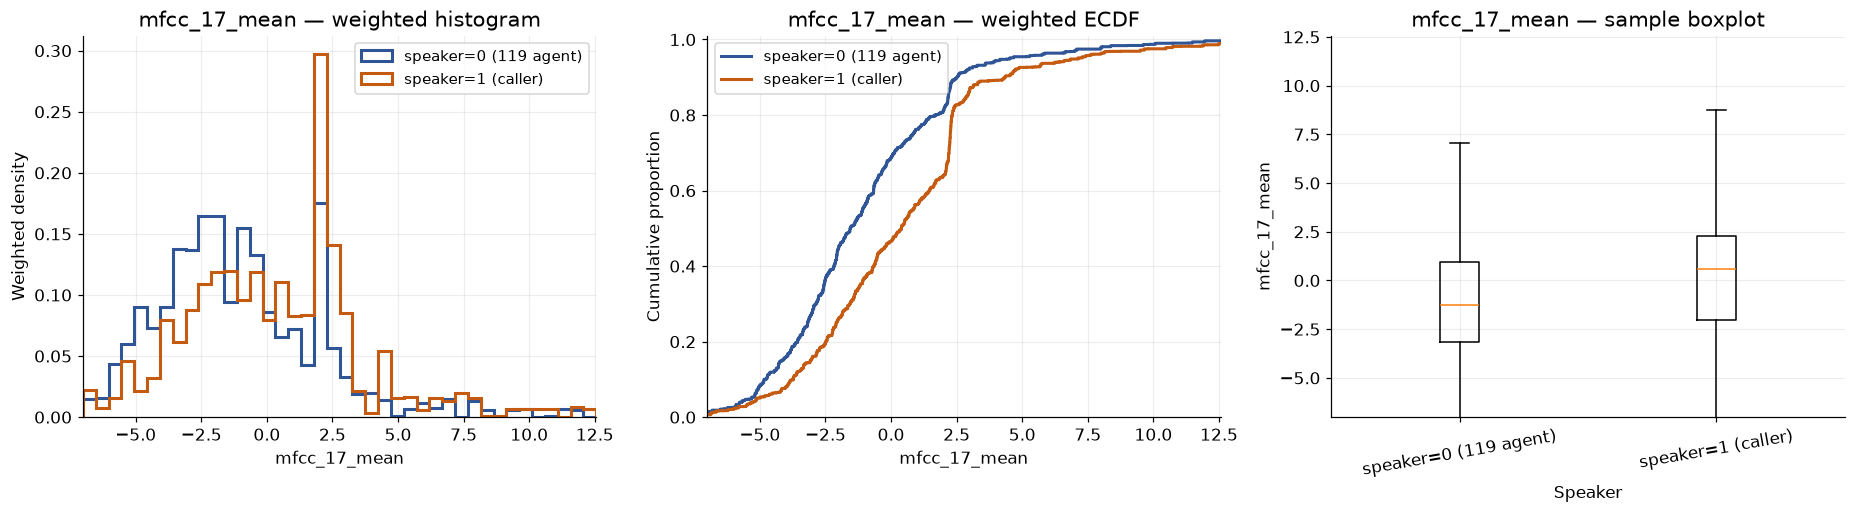

F0는 기본 실행에서 비활성화되어 있습니다.

CHECKPOINT D PASS: Step 8~9로 이동할 수 있습니다.


In [33]:
def plot_feature_triptych(
    feature: str,
    x_label: str,
    *,
    filename: str | None = None,
) -> None:
    plot_frame = acoustic_feature_df.loc[
        acoustic_feature_df["extraction_ok"]
        & np.isfinite(pd.to_numeric(acoustic_feature_df[feature], errors="coerce"))
    ].copy()
    lower, upper = plot_frame[feature].quantile([0.01, 0.99])
    if not np.isfinite(lower) or not np.isfinite(upper) or lower >= upper:
        warnings.warn(f"{feature}: 유효한 plot 범위를 만들 수 없습니다.")
        return
    bins = np.linspace(lower, upper, 41)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for speaker in [0, 1]:
        speaker_frame = plot_frame.loc[plot_frame["speaker"] == speaker]
        visible = speaker_frame.loc[
            speaker_frame[feature].between(lower, upper, inclusive="both")
        ]
        axes[0].hist(
            visible[feature],
            bins=bins,
            weights=visible["sample_weight"],
            density=True,
            histtype="step",
            linewidth=2,
            color=SPEAKER_COLORS[speaker],
            label=SPEAKER_LABELS[speaker],
        )
        x_values, y_values = weighted_ecdf_xy(
            speaker_frame[feature],
            speaker_frame["sample_weight"],
        )
        axes[1].step(
            x_values,
            y_values,
            where="post",
            linewidth=2,
            color=SPEAKER_COLORS[speaker],
            label=SPEAKER_LABELS[speaker],
        )

    box_values = [
        plot_frame.loc[plot_frame["speaker"] == speaker, feature]
        for speaker in [0, 1]
    ]
    axes[2].boxplot(
        box_values,
        tick_labels=[SPEAKER_LABELS[0], SPEAKER_LABELS[1]],
        showfliers=False,
    )
    axes[0].set(
        title=f"{feature} — weighted histogram",
        xlabel=x_label,
        ylabel="Weighted density",
        xlim=(lower, upper),
    )
    axes[1].set(
        title=f"{feature} — weighted ECDF",
        xlabel=x_label,
        ylabel="Cumulative proportion",
        xlim=(lower, upper),
        ylim=(0, 1.01),
    )
    axes[2].set(
        title=f"{feature} — sample boxplot",
        xlabel="Speaker",
        ylabel=x_label,
        ylim=(lower, upper),
    )
    axes[2].tick_params(axis="x", rotation=10)
    axes[0].legend()
    axes[1].legend()
    fig.tight_layout()
    maybe_save_figure(fig, filename or f"step07_{feature}.png")
    plt.show()


PRIMARY_FEATURE_PLOTS = [
    ("rms", "RMS amplitude"),
    ("peak_amplitude", "Peak amplitude"),
    ("silence_ratio", "Silent-frame ratio"),
    ("zcr", "Zero-crossing rate"),
    ("spectral_centroid", "Spectral centroid (Hz)"),
    ("spectral_bandwidth", "Spectral bandwidth (Hz)"),
    ("spectral_rolloff", "Spectral rolloff (Hz)"),
    ("clipping_ratio", "Clipped-sample ratio"),
]
for feature, label in PRIMARY_FEATURE_PLOTS:
    plot_feature_triptych(feature, label)


def weighted_smd_between_speakers(feature: str) -> float:
    stats = {}
    for speaker in [0, 1]:
        frame = acoustic_feature_df.loc[
            (acoustic_feature_df["speaker"] == speaker)
            & acoustic_feature_df["extraction_ok"]
        ]
        values = pd.to_numeric(frame[feature], errors="coerce")
        valid = np.isfinite(values)
        stats[speaker] = weighted_mean_std(
            values.loc[valid],
            frame.loc[valid, "sample_weight"],
        )
    mean0, std0 = stats[0]
    mean1, std1 = stats[1]
    pooled = np.sqrt((std0**2 + std1**2) / 2)
    return (mean1 - mean0) / pooled if np.isfinite(pooled) and pooled > 0 else np.nan


mfcc_effect_rows = [
    {
        "feature": feature,
        "standardized_difference_speaker1_minus_speaker0": weighted_smd_between_speakers(
            feature
        ),
    }
    for feature in [*MFCC_MEAN_FEATURES, *MFCC_STD_FEATURES]
]
mfcc_effect_df = pd.DataFrame(mfcc_effect_rows)
mfcc_effect_matrix = np.vstack(
    [
        mfcc_effect_df.iloc[:N_MFCC, 1].to_numpy(dtype=float),
        mfcc_effect_df.iloc[N_MFCC:, 1].to_numpy(dtype=float),
    ]
)
if not np.isfinite(mfcc_effect_matrix).any():
    raise RuntimeError(
        "MFCC effect를 계산할 유효 acoustic feature가 없습니다. "
        "Step 7 failure summary를 먼저 확인하세요."
    )
color_limit = np.nanmax(np.abs(mfcc_effect_matrix))
color_limit = max(color_limit, 0.01)

fig, ax = plt.subplots(figsize=(14, 3.8))
image = ax.imshow(
    mfcc_effect_matrix,
    aspect="auto",
    cmap="coolwarm",
    vmin=-color_limit,
    vmax=color_limit,
)
ax.set(
    title="MFCC standardized difference: speaker 1 minus speaker 0",
    xlabel="MFCC coefficient",
    ylabel="Summary",
    xticks=np.arange(N_MFCC),
    xticklabels=np.arange(1, N_MFCC + 1),
    yticks=[0, 1],
    yticklabels=["Mean", "Std"],
)
fig.colorbar(image, ax=ax, label="Standardized difference")
fig.tight_layout()
maybe_save_figure(fig, "step07_mfcc_effect_heatmap.png")
plt.show()

top_mfcc_features = (
    mfcc_effect_df.assign(
        absolute_difference=lambda frame: frame[
            "standardized_difference_speaker1_minus_speaker0"
        ].abs()
    )
    .sort_values("absolute_difference", ascending=False)
    .head(4)
)
display(Markdown("### MFCC coefficients with the largest sample difference"))
display_table(top_mfcc_features)
for feature in top_mfcc_features["feature"]:
    plot_feature_triptych(feature, feature)

if INCLUDE_F0:
    display(Markdown("### F0 extraction status"))
    display_table(
        acoustic_feature_df["f0_status"]
        .value_counts(dropna=False)
        .rename_axis("f0_status")
        .reset_index(name="count")
    )
else:
    display(Markdown("F0는 기본 실행에서 비활성화되어 있습니다."))

ACKNOWLEDGE_REVIEWED_EXTRACTION_FAILURES = False
total_extraction_failures = int((~acoustic_feature_df["extraction_ok"]).sum())
if total_extraction_failures and not ACKNOWLEDGE_REVIEWED_EXTRACTION_FAILURES:
    raise RuntimeError(
        f"Acoustic extraction failure {total_extraction_failures:,}건. "
        "failure sample을 검토하고 원인을 기록한 뒤에만 "
        "ACKNOWLEDGE_REVIEWED_EXTRACTION_FAILURES=True로 바꾸세요."
    )

print("CHECKPOINT D PASS: Step 8~9로 이동할 수 있습니다.")


RMS(평균 음량) : 신고자가 119대원보다 약간 높은 쪽으로 보이지만 두 분포가 많이 겹친다.
→ 음량만으로는 구분하기 어려움.

Peak amplitude(최대 순간 음량) : 두 집단이 거의 비슷하다.
→ 구분 정보가 약해 보임.

Silence ratio(무음 비율) : 119대원이 신고자보다 약간 높은 경향은 있지만 겹침이 매우 크다.
→ 단독 feature로는 약함.

ZCR(Zero-Crossing Rate : 음성 파형이 위아래로 얼마나 자주 빠르게 바뀌는지) : 119대원이 신고자보다 전반적으로 높은 값에 분포한다.

spectral_centroid = 소리가 얼마나 고주파 쪽에 중심이 있는가

spectral_bandwidth = 주파수가 얼마나 넓게 퍼져 있는가

spectral_rolloff = 소리 에너지 대부분이 어느 높은 주파수까지 퍼져 있는가

세 개 모두 대체로 119대원이 신고자보다 높은 값을 보인다.

Clipping ratio(음성이 너무 크게 녹음돼서 파형이 최대 한계에 붙어 찌그러진 구간의 비율) : 거의 대부분 0이고 speaker 차이도 별로 없다.
→ 현재로서는 별 도움 없어 보임.

MFCC(목소리의 음색·주파수 형태를 여러 숫자로 압축한 feature) : 가장 speaker 차이가 컸던 MFCC는 mfcc_02_mean, mfcc_03_mean, mfcc_06_mean

차이가 보이는 특징들로 분류에 도움이 될 가능성

## EDA Step 8 — Call Structure / Duplicate / Leakage Audit

**Checkpoint E — part 1**

1. **무엇을 측정하는가:** call별 utterance·speaker 구성, 동일 interval, overlap, containment, 높은 overlap과 선택적 waveform hash 중복 후보를 점검합니다.
2. **입력:** 전체 utterance_df의 허용 metadata와 crop boundary를 사용합니다. waveform hash는 기본 비활성화된 고정-seed 표본 옵션입니다.
3. **출력 의미:** overlap은 동일 call에서 파생된 sample 사이의 의존성을, exact duplicate는 사실상 같은 crop이 반복될 가능성을 보여줍니다.
4. **잘못될 수 있는 경우:** 자연스러운 turn overlap이 곧 오류는 아니며 metadata interval 일치가 파일 간 waveform 동일성을 보장하지도 않습니다. 전체 waveform hash는 비용이 커 기본 실행에 포함하지 않습니다.
5. **다음 판단 연결:** internal validation에서 같은 call의 utterance가 양쪽 split에 섞이지 않게 group split을 설계하고, duplicate·overlap sample을 quality/error-analysis slice 후보로 넘깁니다.

**중요:** call-level group split은 공식 대회 규칙이라고 단정하지 않습니다. 같은 통화의 목소리·채널·환경을 모델이 기억해 내부 점수가 과대평가되는 것을 막기 위한 팀 내부 검증 설계입니다. 공식 Validation 활용 허용 여부와는 별개의 문제입니다.


같은 통화나 거의 같은 음성이 train과 validation에 섞여서 모델이 답을 쉽게 맞히는 문제가 없는지 확인하는 단계

In [34]:
INTERVAL_TOLERANCE_MS = 1e-6
HIGH_OVERLAP_RATIO = 0.80
REBUILD_INTERVAL_CACHE = False

CALL_OVERLAP_CACHE_PATH = CACHE_DIR / "call_overlap_summary_v1.parquet"
OVERLAP_EXAMPLE_CACHE_PATH = CACHE_DIR / "overlap_examples_v1.parquet"
DUPLICATE_INTERVAL_CACHE_PATH = CACHE_DIR / "duplicate_intervals_v1.parquet"
INTERVAL_META_PATH = CACHE_DIR / "interval_audit_meta_v1.json"
OVERLAP_EXAMPLE_COLUMNS = [
    "split",
    "call_id",
    "left_record_key",
    "right_record_key",
    "left_speaker",
    "right_speaker",
    "left_interval_ms",
    "right_interval_ms",
    "overlap_ms",
    "overlap_ratio_of_shorter",
    "is_containment",
    "is_high_overlap",
]


def audit_intervals(
    frame: pd.DataFrame,
    *,
    example_limit: int = 200,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    valid = frame.loc[
        np.isfinite(frame["startAt_ms"])
        & np.isfinite(frame["endAt_ms"])
        & (frame["endAt_ms"] > frame["startAt_ms"])
    ].copy()

    duplicate_intervals = (
        valid.groupby(
            ["split", "call_id", "startAt_ms", "endAt_ms"],
            observed=True,
        )
        .agg(
            rows=("record_key", "size"),
            distinct_utterance_ids=("utterance_id", "nunique"),
            speaker_values=(
                "speaker",
                lambda values: ",".join(
                    map(str, sorted(set(values.dropna().astype(int))))
                ),
            ),
        )
        .reset_index()
    )
    duplicate_intervals = duplicate_intervals.loc[
        duplicate_intervals["rows"] > 1
    ].reset_index(drop=True)

    call_rows = []
    examples = []
    for call_number, ((split, call_id), group) in enumerate(
        valid.groupby(["split", "call_id"], sort=False, observed=True),
        start=1,
    ):
        ordered = group.sort_values(
            ["startAt_ms", "endAt_ms", "record_key"]
        ).reset_index(drop=True)
        overlap_count = 0
        containment_count = 0
        high_overlap_count = 0
        maximum_overlap_ratio = 0.0

        records = list(ordered.itertuples(index=False))
        for left_index, left in enumerate(records):
            left_start = float(left.startAt_ms)
            left_end = float(left.endAt_ms)
            left_duration = left_end - left_start
            for right in records[left_index + 1 :]:
                right_start = float(right.startAt_ms)
                if right_start >= left_end - INTERVAL_TOLERANCE_MS:
                    break
                right_end = float(right.endAt_ms)
                overlap_ms = min(left_end, right_end) - max(left_start, right_start)
                if overlap_ms <= INTERVAL_TOLERANCE_MS:
                    continue

                right_duration = right_end - right_start
                shorter_duration = min(left_duration, right_duration)
                overlap_ratio = overlap_ms / shorter_duration
                is_containment = (
                    overlap_ms >= shorter_duration - INTERVAL_TOLERANCE_MS
                )
                is_high_overlap = overlap_ratio >= HIGH_OVERLAP_RATIO

                overlap_count += 1
                containment_count += int(is_containment)
                high_overlap_count += int(is_high_overlap)
                maximum_overlap_ratio = max(maximum_overlap_ratio, overlap_ratio)

                if len(examples) < example_limit:
                    examples.append(
                        {
                            "split": split,
                            "call_id": call_id,
                            "left_record_key": left.record_key,
                            "right_record_key": right.record_key,
                            "left_speaker": left.speaker,
                            "right_speaker": right.speaker,
                            "left_interval_ms": f"[{left_start}, {left_end})",
                            "right_interval_ms": f"[{right_start}, {right_end})",
                            "overlap_ms": overlap_ms,
                            "overlap_ratio_of_shorter": overlap_ratio,
                            "is_containment": is_containment,
                            "is_high_overlap": is_high_overlap,
                        }
                    )

        call_rows.append(
            {
                "split": split,
                "call_id": call_id,
                "overlap_pair_count": overlap_count,
                "containment_pair_count": containment_count,
                "high_overlap_pair_count": high_overlap_count,
                "maximum_overlap_ratio": maximum_overlap_ratio,
            }
        )
        if call_number % 5_000 == 0:
            print(f"interval audit progress: {call_number:,} calls")

    return (
        pd.DataFrame(call_rows),
        pd.DataFrame(examples, columns=OVERLAP_EXAMPLE_COLUMNS),
        duplicate_intervals,
    )


def waveform_hash_audit(
    frame: pd.DataFrame,
    *,
    max_utterances: int = 5_000,
    seed: int = EDA_RANDOM_SEED,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    candidates = frame.loc[frame["crop_ok"]].copy()
    if len(candidates) > max_utterances:
        candidates = candidates.sample(n=max_utterances, random_state=seed)

    hashed_rows = []
    for (split, audio_path), group in candidates.groupby(
        ["split", "audio_path"], sort=False, observed=True
    ):
        try:
            waveform, sample_rate = read_call_waveform(DATA_ROOT / audio_path)
        except Exception as exc:
            for row in group.itertuples(index=False):
                hashed_rows.append(
                    {
                        "split": split,
                        "call_id": row.call_id,
                        "record_key": row.record_key,
                        "waveform_sha256": None,
                        "hash_error": f"{type(exc).__name__}: {exc}",
                    }
                )
            continue

        for row in group.itertuples(index=False):
            try:
                start_frame = int(row.crop_start_frame)
                end_frame = int(row.crop_end_frame)
                segment = waveform[start_frame:end_frame]
                if len(segment) == 0:
                    raise ValueError("empty crop")
                digest = hashlib.sha256()
                digest.update(int(sample_rate).to_bytes(4, "little", signed=False))
                digest.update(segment.astype("<f4", copy=False).tobytes())
                hash_value = digest.hexdigest()
                error = ""
            except Exception as exc:
                hash_value = None
                error = f"{type(exc).__name__}: {exc}"
            hashed_rows.append(
                {
                    "split": split,
                    "call_id": row.call_id,
                    "record_key": row.record_key,
                    "waveform_sha256": hash_value,
                    "hash_error": error,
                }
            )

    hash_rows = pd.DataFrame(hashed_rows)
    valid_hash_rows = hash_rows.loc[hash_rows["waveform_sha256"].notna()]
    duplicate_hash_groups = (
        valid_hash_rows.groupby("waveform_sha256", observed=True)
        .agg(
            rows=("record_key", "size"),
            calls=("call_id", "nunique"),
            splits=("split", lambda values: ",".join(sorted(set(values)))),
            example_record_keys=(
                "record_key",
                lambda values: " | ".join(list(values)[:5]),
            ),
        )
        .reset_index()
    )
    duplicate_hash_groups = duplicate_hash_groups.loc[
        duplicate_hash_groups["rows"] > 1
    ].sort_values("rows", ascending=False)
    return hash_rows, duplicate_hash_groups


In [35]:
interval_cache_meta = {
    "schema_version": CACHE_SCHEMA_VERSION,
    "source_signature": source_signature,
    "interval_tolerance_ms": INTERVAL_TOLERANCE_MS,
    "high_overlap_ratio": HIGH_OVERLAP_RATIO,
}
interval_cache_exists = all(
    path.is_file()
    for path in [
        CALL_OVERLAP_CACHE_PATH,
        OVERLAP_EXAMPLE_CACHE_PATH,
        DUPLICATE_INTERVAL_CACHE_PATH,
        INTERVAL_META_PATH,
    ]
)
cached_interval_meta = None
if interval_cache_exists:
    try:
        cached_interval_meta = json.loads(
            INTERVAL_META_PATH.read_text(encoding="utf-8")
        )
    except Exception as exc:
        print(f"Interval cache metadata를 읽지 못해 재생성합니다: {exc}")

use_interval_cache = (
    not REBUILD_INTERVAL_CACHE
    and interval_cache_exists
    and cached_interval_meta == interval_cache_meta
)
if use_interval_cache:
    call_overlap_df = pd.read_parquet(CALL_OVERLAP_CACHE_PATH)
    overlap_example_df = pd.read_parquet(OVERLAP_EXAMPLE_CACHE_PATH)
    duplicate_interval_df = pd.read_parquet(DUPLICATE_INTERVAL_CACHE_PATH)
    print("Interval cache reused:", CALL_OVERLAP_CACHE_PATH)
else:
    call_overlap_df, overlap_example_df, duplicate_interval_df = audit_intervals(
        analysis_utterance_df
    )
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    call_overlap_df.to_parquet(CALL_OVERLAP_CACHE_PATH, index=False)
    overlap_example_df.to_parquet(OVERLAP_EXAMPLE_CACHE_PATH, index=False)
    duplicate_interval_df.to_parquet(DUPLICATE_INTERVAL_CACHE_PATH, index=False)
    INTERVAL_META_PATH.write_text(
        json.dumps(interval_cache_meta, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Interval cache written:", CALL_OVERLAP_CACHE_PATH)

call_structure_df = call_df.merge(
    call_overlap_df,
    on=["split", "call_id"],
    how="left",
    validate="one_to_one",
)
overlap_columns = [
    "overlap_pair_count",
    "containment_pair_count",
    "high_overlap_pair_count",
    "maximum_overlap_ratio",
]
call_structure_df[overlap_columns] = call_structure_df[overlap_columns].fillna(0)
call_structure_df["speaker1_proportion"] = np.where(
    call_structure_df["utterance_count"] > 0,
    call_structure_df["speaker1_count"] / call_structure_df["utterance_count"],
    np.nan,
)
call_structure_df["speaker_composition"] = np.select(
    [
        (call_structure_df["speaker0_count"] > 0)
        & (call_structure_df["speaker1_count"] > 0),
        (call_structure_df["speaker0_count"] > 0)
        & (call_structure_df["speaker1_count"] == 0),
        (call_structure_df["speaker0_count"] == 0)
        & (call_structure_df["speaker1_count"] > 0),
    ],
    ["both speakers", "speaker 0 only", "speaker 1 only"],
    default="no valid speaker",
)

call_structure_summary = (
    call_structure_df.groupby("split", observed=True)
    .agg(
        calls=("call_id", "nunique"),
        utterances_mean=("utterance_count", "mean"),
        utterances_median=("utterance_count", "median"),
        utterances_max=("utterance_count", "max"),
        speaker0_utterances=("speaker0_count", "sum"),
        speaker1_utterances=("speaker1_count", "sum"),
        one_speaker_calls=(
            "speaker_composition",
            lambda values: int(values.isin(["speaker 0 only", "speaker 1 only"]).sum()),
        ),
        calls_with_overlap=("overlap_pair_count", lambda values: int((values > 0).sum())),
        overlap_pairs=("overlap_pair_count", "sum"),
        containment_pairs=("containment_pair_count", "sum"),
        high_overlap_pairs=("high_overlap_pair_count", "sum"),
    )
    .reindex(SPLIT_ORDER)
    .reset_index()
)
speaker_composition_summary = (
    call_structure_df.groupby(["split", "speaker_composition"], observed=True)
    .size()
    .rename("calls")
    .reset_index()
)
interval_summary = pd.DataFrame(
    [
        {
            "metric": "duplicate interval groups",
            "count": len(duplicate_interval_df),
        },
        {
            "metric": "duplicate interval rows",
            "count": int(duplicate_interval_df["rows"].sum())
            if len(duplicate_interval_df)
            else 0,
        },
        {
            "metric": "overlap pairs",
            "count": int(call_structure_df["overlap_pair_count"].sum()),
        },
        {
            "metric": "containment pairs",
            "count": int(call_structure_df["containment_pair_count"].sum()),
        },
        {
            "metric": f"high-overlap pairs (≥{HIGH_OVERLAP_RATIO:.0%})",
            "count": int(call_structure_df["high_overlap_pair_count"].sum()),
        },
    ]
)

RUN_WAVEFORM_HASH_AUDIT = False
WAVEFORM_HASH_MAX_UTTERANCES = 5_000
if RUN_WAVEFORM_HASH_AUDIT:
    waveform_hash_df, duplicate_waveform_hash_df = waveform_hash_audit(
        analysis_utterance_df,
        max_utterances=WAVEFORM_HASH_MAX_UTTERANCES,
    )
else:
    waveform_hash_df = pd.DataFrame()
    duplicate_waveform_hash_df = pd.DataFrame()
    display(
        Markdown(
            "Waveform hash audit는 비용을 통제하기 위해 기본 비활성화입니다. "
            "RUN_WAVEFORM_HASH_AUDIT=True로 바꾸면 고정-seed 최대 "
            f"{WAVEFORM_HASH_MAX_UTTERANCES:,}개 표본에서만 계산합니다."
        )
    )

display(Markdown("### Call structure summary"))
display_table(call_structure_summary, max_rows=10)
display(Markdown("### Speaker composition by call"))
display_table(speaker_composition_summary, max_rows=20)
display(Markdown("### Duplicate / overlap summary"))
display_table(interval_summary)
display(Markdown("### Representative duplicate intervals"))
display_table(duplicate_interval_df, max_rows=20)
display(Markdown("### Representative overlap pairs"))
display_table(overlap_example_df, max_rows=20)
if RUN_WAVEFORM_HASH_AUDIT:
    display(Markdown("### Duplicate waveform hash candidates — sampled scope"))
    display_table(duplicate_waveform_hash_df, max_rows=20)


interval audit progress: 5,000 calls
interval audit progress: 10,000 calls
interval audit progress: 15,000 calls
interval audit progress: 20,000 calls
interval audit progress: 25,000 calls
interval audit progress: 30,000 calls
Interval cache written: C:\Users\YW\Study\02_Projects\DCC_2026\prelim\tmp\mission2_eda\call_overlap_summary_v1.parquet


Waveform hash audit는 비용을 통제하기 위해 기본 비활성화입니다. RUN_WAVEFORM_HASH_AUDIT=True로 바꾸면 고정-seed 최대 5,000개 표본에서만 계산합니다.

### Call structure summary

,split,calls,utterances_mean,utterances_median,utterances_max,speaker0_utterances,speaker1_utterances,one_speaker_calls,calls_with_overlap,overlap_pairs,containment_pairs,high_overlap_pairs
0,Training,29200,30.4575,29.0,98,427161,462197,0,28659,228971,31760,44999
1,Validation,3640,30.7547,29.0,95,53845,58102,0,3559,28654,4157,5779


### Speaker composition by call

...

,metric,count
0,duplicate interval groups,3
1,duplicate interval rows,6
2,overlap pairs,257625
3,containment pairs,35917
4,high-overlap pairs (≥80%),50778


### Representative duplicate intervals

,split,call_id,startAt_ms,endAt_ms,rows,distinct_utterance_ids,speaker_values
0,Training,651e4b1829d82455557a200b_20220502,52917.0,53599.0,2,2,"0,1"
1,Training,651e4bc5df6bf0d825aa56fa_20220505,44148.0,44839.0,2,2,"0,1"
2,Training,651e4c5b48bae907503799a9_20220602,28548.0,29321.0,2,2,"0,1"


### Representative overlap pairs

,split,call_id,left_record_key,right_record_key,left_speaker,right_speaker,left_interval_ms,right_interval_ms,overlap_ms,overlap_ratio_of_shorter,is_containment,is_high_overlap
0,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|1,Training|651e464d69a4f266f062680b_20220101|2,1,0,"[2032.0, 6562.0)","[4858.0, 7427.0)",1704.0,0.6633,False,False
1,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|4,Training|651e464d69a4f266f062680b_20220101|5,0,1,"[9127.0, 12514.0)","[12244.0, 13022.0)",270.0,0.3470,False,False
2,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|8,Training|651e464d69a4f266f062680b_20220101|9,1,0,"[20538.0, 23449.0)","[20925.0, 21372.0)",447.0,1.0000,True,True
3,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|11,Training|651e464d69a4f266f062680b_20220101|12,1,0,"[25366.0, 26147.0)","[26093.0, 26945.0)",54.0,0.0691,False,False
4,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|13,Training|651e464d69a4f266f062680b_20220101|14,1,1,"[27045.0, 33805.0)","[33766.0, 34498.0)",39.0,0.0533,False,False
5,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|14,Training|651e464d69a4f266f062680b_20220101|15,1,0,"[33766.0, 34498.0)","[34394.0, 37622.0)",104.0,0.1421,False,False
6,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|15,Training|651e464d69a4f266f062680b_20220101|16,0,1,"[34394.0, 37622.0)","[36924.0, 39719.0)",698.0,0.2497,False,False
7,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|16,Training|651e464d69a4f266f062680b_20220101|17,1,0,"[36924.0, 39719.0)","[39035.0, 41147.0)",684.0,0.3239,False,False
8,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|18,Training|651e464d69a4f266f062680b_20220101|19,1,0,"[41201.0, 41679.0)","[41613.0, 42983.0)",66.0,0.1381,False,False
9,Training,651e464d69a4f266f062680b_20220101,Training|651e464d69a4f266f062680b_20220101|19,Training|651e464d69a4f266f062680b_20220101|20,0,1,"[41613.0, 42983.0)","[42713.0, 43557.0)",270.0,0.3199,False,False


### 이 그래프에서 확인할 것

Step 4의 utterances-per-call histogram/ECDF를 call count 분포의 기준 그림으로 재사용합니다. 여기서는 같은 정보를 반복하지 않고 다음을 추가로 봅니다.

- **Speaker composition:** 한 speaker만 존재하는 call과 caller 비중
- **Scatter:** call 크기와 speaker 구성의 joint structure
- **Overlap distribution:** 소수 call에 overlap이 집중되는지
- **Duplicate summary bar:** exact duplicate, containment, high overlap의 상대 규모


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

composition_pivot = (
    speaker_composition_summary.pivot(
        index="split", columns="speaker_composition", values="calls"
    )
    .reindex(SPLIT_ORDER)
    .fillna(0)
)
composition_pivot.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 0],
    color=["#70ad47", "#a5a5a5", "#ffc000", "#c00000"][
        : len(composition_pivot.columns)
    ],
)
axes[0, 0].set(
    title="Call-level speaker composition",
    xlabel="Split",
    ylabel="Calls (count)",
)
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 0].legend(title="Composition")

for split in SPLIT_ORDER:
    subset = call_structure_df.loc[call_structure_df["split"] == split]
    axes[0, 1].scatter(
        subset["utterance_count"],
        subset["speaker1_proportion"],
        s=10,
        alpha=0.20,
        color=SPLIT_COLORS[split],
        label=split,
    )
axes[0, 1].set(
    title="Call size vs caller proportion",
    xlabel="Utterances per call (count)",
    ylabel="speaker=1 proportion",
    ylim=(-0.02, 1.02),
)
axes[0, 1].legend()

positive_overlap = call_structure_df.loc[
    call_structure_df["overlap_pair_count"] > 0, "overlap_pair_count"
]
if len(positive_overlap):
    overlap_plot_max = max(1, int(positive_overlap.quantile(0.99)))
    axes[1, 0].hist(
        positive_overlap.clip(upper=overlap_plot_max),
        bins=min(40, overlap_plot_max),
        color="#5b9bd5",
        alpha=0.85,
    )
    axes[1, 0].set(
        title="Overlap pairs per affected call (values capped at P99 for plot)",
        xlabel="Overlap pair count",
        ylabel="Calls (count)",
    )
else:
    axes[1, 0].text(0.5, 0.5, "No overlap pairs", ha="center", va="center")
    axes[1, 0].set_title("Overlap pairs per affected call")

axes[1, 1].barh(
    interval_summary["metric"],
    interval_summary["count"],
    color="#4472c4",
)
axes[1, 1].set(
    title="Duplicate / overlap audit counts",
    xlabel="Count",
    ylabel="Audit item",
)
fig.tight_layout()
maybe_save_figure(fig, "step08_call_duplicate_leakage.png")
plt.show()

print(
    "CHECKPOINT E-1 REVIEW: 같은 call의 utterance를 internal train/validation "
    "양쪽에 나누지 않는 group split이 필요합니다."
)


## EDA Step 9 — Audio Quality & Outlier EDA

**Checkpoint E — part 2**

1. **무엇을 측정하는가:** invalid crop/read/feature와 distribution-based suspicious duration, RMS, silence, clipping, sample-rate/channel 이상을 구분합니다.
2. **입력:** 전체 manifest의 boundary/header 정보와 acoustic stratified sample의 실제 signal feature입니다.
3. **출력 의미:** invalid는 분석 전 해결해야 하는 실패이고, suspicious는 자동 삭제 대상이 아니라 직접 청취할 우선 검토 sample입니다.
4. **잘못될 수 있는 경우:** quantile threshold는 상대적 꼬리를 표시할 뿐 오류를 증명하지 않습니다. -50 dBFS near-silence와 clipping 기준도 운영 후보이며 최종 filtering 규칙이 아닙니다.
5. **다음 판단 연결:** quality flag를 향후 error-analysis slice로 넘기고, invalid가 없거나 원인이 검토된 경우에만 distribution shift로 이동합니다.


In [ ]:
NEAR_SILENCE_DBFS = -50.0
near_silence_rms_threshold = 10 ** (NEAR_SILENCE_DBFS / 20)

training_duration_values = analysis_utterance_df.loc[
    analysis_utterance_df["split"] == "Training", "duration_sec"
]
duration_p01, duration_p99 = training_duration_values.quantile([0.01, 0.99])

training_acoustic = acoustic_feature_df.loc[
    (acoustic_feature_df["split"] == "Training")
    & acoustic_feature_df["extraction_ok"]
].copy()
rms_p01, rms_p99 = weighted_quantile(
    training_acoustic["rms"],
    training_acoustic["sample_weight"],
    [0.01, 0.99],
)
silence_p99 = weighted_quantile(
    training_acoustic["silence_ratio"],
    training_acoustic["sample_weight"],
    [0.99],
)[0]

expected_sample_rate = int(
    call_df.loc[call_df["wav_read_ok"], "sample_rate"].mode().iloc[0]
)
expected_channels = int(
    call_df.loc[call_df["wav_read_ok"], "channels"].mode().iloc[0]
)

quality_thresholds = pd.DataFrame(
    [
        {
            "flag": "very_short_duration",
            "threshold": duration_p01,
            "unit": "seconds",
            "basis": "Training P01",
        },
        {
            "flag": "very_long_duration",
            "threshold": duration_p99,
            "unit": "seconds",
            "basis": "Training P99",
        },
        {
            "flag": "low_rms",
            "threshold": rms_p01,
            "unit": "amplitude",
            "basis": "weighted Training P01",
        },
        {
            "flag": "high_rms",
            "threshold": rms_p99,
            "unit": "amplitude",
            "basis": "weighted Training P99",
        },
        {
            "flag": "high_silence_ratio",
            "threshold": silence_p99,
            "unit": "ratio",
            "basis": "weighted Training P99",
        },
        {
            "flag": "near_silence_absolute",
            "threshold": near_silence_rms_threshold,
            "unit": "RMS amplitude",
            "basis": f"{NEAR_SILENCE_DBFS:.0f} dBFS review candidate",
        },
        {
            "flag": "sample_rate_anomaly",
            "threshold": expected_sample_rate,
            "unit": "Hz",
            "basis": "dataset modal sample rate",
        },
        {
            "flag": "channel_anomaly",
            "threshold": expected_channels,
            "unit": "channels",
            "basis": "dataset modal channel count",
        },
    ]
)

quality_frame = acoustic_feature_df.merge(
    utterance_df[
        ["record_key", "channels", "sample_rate", "boundary_status", "crop_ok"]
    ],
    on="record_key",
    how="left",
    validate="one_to_one",
)

quality_rows = []
for row in quality_frame.itertuples(index=False):
    flags = []
    invalid_flags = []

    if not row.crop_ok:
        invalid_flags.append("invalid_crop")
    if not row.extraction_ok:
        invalid_flags.append("extraction_failure")

    core_values = np.asarray(
        [getattr(row, feature) for feature in CORE_ACOUSTIC_FEATURES],
        dtype=float,
    )
    if row.extraction_ok and not np.isfinite(core_values).all():
        invalid_flags.append("non_finite_core_feature")
    if row.boundary_status in {"start_after_wav", "critical_overrun"}:
        invalid_flags.append("audio_length_mismatch")

    flags.extend(invalid_flags)
    if np.isfinite(row.duration_sec) and row.duration_sec <= duration_p01:
        flags.append("very_short_duration")
    if np.isfinite(row.duration_sec) and row.duration_sec >= duration_p99:
        flags.append("very_long_duration")
    if np.isfinite(row.rms) and row.rms <= rms_p01:
        flags.append("low_rms")
    if np.isfinite(row.rms) and row.rms >= rms_p99:
        flags.append("high_rms")
    if np.isfinite(row.rms) and row.rms <= near_silence_rms_threshold:
        flags.append("near_silence_absolute")
    if np.isfinite(row.silence_ratio) and row.silence_ratio >= silence_p99:
        flags.append("high_silence_ratio")
    if np.isfinite(row.clipping_ratio) and row.clipping_ratio > 0:
        flags.append("clipping_detected")
    if np.isfinite(row.sample_rate) and int(row.sample_rate) != expected_sample_rate:
        flags.append("sample_rate_anomaly")
    if np.isfinite(row.channels) and int(row.channels) != expected_channels:
        flags.append("channel_anomaly")

    quality_rows.append(
        {
            "record_key": row.record_key,
            "quality_status": (
                "invalid"
                if invalid_flags
                else "suspicious"
                if flags
                else "normal"
            ),
            "quality_flags": flags,
        }
    )

quality_label_df = pd.DataFrame(quality_rows)
quality_frame = quality_frame.merge(
    quality_label_df,
    on="record_key",
    how="left",
    validate="one_to_one",
)
quality_exploded = quality_frame.loc[
    quality_frame["quality_flags"].map(len) > 0
].explode("quality_flags")

quality_summary_rows = []
for flag, group in quality_exploded.groupby("quality_flags", observed=True):
    quality_summary_rows.append(
        {
            "quality_flag": flag,
            "count": len(group),
            "proportion_of_acoustic_sample": len(group) / len(quality_frame),
            "speaker0_count": int((group["speaker"] == 0).sum()),
            "speaker1_count": int((group["speaker"] == 1).sum()),
        }
    )
quality_summary_df = pd.DataFrame(
    quality_summary_rows,
    columns=[
        "quality_flag",
        "count",
        "proportion_of_acoustic_sample",
        "speaker0_count",
        "speaker1_count",
    ],
)
if len(quality_summary_df):
    quality_summary_df = quality_summary_df.sort_values(
        "count", ascending=False
    )
quality_status_summary = (
    quality_frame.groupby(["quality_status", "speaker"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)

priority_flags = [
    "extraction_failure",
    "non_finite_core_feature",
    "audio_length_mismatch",
    "near_silence_absolute",
    "high_silence_ratio",
    "clipping_detected",
    "very_short_duration",
    "very_long_duration",
    "low_rms",
    "high_rms",
]
quality_example_parts = []
for flag in priority_flags:
    candidates = quality_exploded.loc[
        quality_exploded["quality_flags"] == flag
    ]
    if len(candidates):
        quality_example_parts.append(
            candidates.sample(n=1, random_state=EDA_RANDOM_SEED)
        )
quality_example_df = (
    pd.concat(quality_example_parts, ignore_index=True)
    .drop_duplicates("record_key")
    .head(12)
    if quality_example_parts
    else pd.DataFrame()
)

display(Markdown("### Quality thresholds — review candidates, not deletion rules"))
display_table(quality_thresholds, max_rows=20)
display(Markdown("### Quality flag summary"))
display_table(quality_summary_df, max_rows=30)
display(Markdown("### Quality status × speaker"))
display_table(quality_status_summary, max_rows=20)
display(Markdown("### Representative quality samples"))
display_table(
    quality_example_df[
        [
            "record_key",
            "split",
            "speaker",
            "duration_sec",
            "rms",
            "silence_ratio",
            "clipping_ratio",
            "quality_flags",
        ]
    ]
    if len(quality_example_df)
    else quality_example_df,
    max_rows=20,
)


### 이 그래프에서 확인할 것

- **Issue count bar:** 어떤 quality 문제가 우선 검토 대상인지
- **Duration × silence / RMS × silence scatter:** 단일 threshold보다 joint structure가 더 설명력 있는지
- **Quality status:** suspicious가 특정 speaker에 과도하게 집중되는지

scatter는 acoustic 표본 결과이며 전체 데이터의 확정 비율로 해석하지 않습니다.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

if len(quality_summary_df):
    axes[0, 0].barh(
        quality_summary_df["quality_flag"][::-1],
        quality_summary_df["count"][::-1],
        color="#ed7d31",
    )
axes[0, 0].set(
    title="Audio quality issue counts",
    xlabel="Sample rows (count)",
    ylabel="Quality flag",
)

valid_quality = quality_frame.loc[quality_frame["extraction_ok"]]
for speaker in [0, 1]:
    subset = valid_quality.loc[valid_quality["speaker"] == speaker]
    axes[0, 1].scatter(
        subset["duration_sec"],
        subset["silence_ratio"],
        s=14,
        alpha=0.32,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
    axes[1, 0].scatter(
        subset["rms"],
        subset["silence_ratio"],
        s=14,
        alpha=0.32,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
axes[0, 1].set(
    title="Duration vs silence ratio",
    xlabel="Duration (seconds)",
    ylabel="Silent-frame ratio",
    xlim=(0, duration_p99),
)
axes[1, 0].set(
    title="RMS vs silence ratio",
    xlabel="RMS amplitude",
    ylabel="Silent-frame ratio",
)
axes[0, 1].legend()
axes[1, 0].legend()

status_pivot = (
    quality_status_summary.pivot(
        index="quality_status", columns="speaker", values="count"
    )
    .fillna(0)
)
bottom = np.zeros(len(status_pivot))
for speaker in [0, 1]:
    values = (
        status_pivot[speaker]
        if speaker in status_pivot.columns
        else np.zeros(len(status_pivot))
    )
    axes[1, 1].bar(
        status_pivot.index,
        values,
        bottom=bottom,
        color=SPEAKER_COLORS[speaker],
        label=SPEAKER_LABELS[speaker],
    )
    bottom += np.asarray(values)
axes[1, 1].set(
    title="Quality status by speaker",
    xlabel="Quality status",
    ylabel="Sample rows (count)",
)
axes[1, 1].legend()

fig.tight_layout()
maybe_save_figure(fig, "step09_audio_quality.png")
plt.show()


def render_quality_samples(
    examples: pd.DataFrame,
    *,
    max_samples: int = 6,
) -> None:
    for row in examples.head(max_samples).itertuples(index=False):
        segment, sample_rate = load_manifest_segment(row)
        analysis_signal = (
            np.pad(segment, (0, N_FFT - len(segment)))
            if len(segment) < N_FFT
            else segment
        )
        mel_power = librosa.feature.melspectrogram(
            y=analysis_signal,
            sr=sample_rate,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=64,
            power=2.0,
        )
        mel_db = librosa.power_to_db(mel_power, ref=np.max)

        fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
        time_axis = np.arange(len(segment)) / sample_rate
        axes[0].plot(time_axis, segment, color="#2f5597", linewidth=0.8)
        axes[0].set(
            title=(
                f"{row.record_key} — {SPEAKER_LABELS[int(row.speaker)]} — "
                f"{row.quality_flags}"
            ),
            xlabel="Relative time (seconds)",
            ylabel="Amplitude",
            ylim=(-1.05, 1.05),
        )
        image = librosa.display.specshow(
            mel_db,
            sr=sample_rate,
            hop_length=HOP_LENGTH,
            x_axis="time",
            y_axis="mel",
            ax=axes[1],
            cmap="magma",
        )
        axes[1].set(
            title="Mel-spectrogram",
            xlabel="Relative time (seconds)",
            ylabel="Mel frequency (Hz)",
        )
        fig.colorbar(image, ax=axes[1], label="Power (dB)")
        plt.show()
        display(Audio(segment, rate=sample_rate))

# 직접 확인할 때만 아래 주석을 해제합니다.
# render_quality_samples(quality_example_df, max_samples=6)

ACKNOWLEDGE_REVIEWED_INVALID_QUALITY = False
invalid_quality_count = int((quality_frame["quality_status"] == "invalid").sum())
if invalid_quality_count and not ACKNOWLEDGE_REVIEWED_INVALID_QUALITY:
    raise RuntimeError(
        f"Invalid quality row {invalid_quality_count:,}건. "
        "원인을 검토한 뒤에만 ACKNOWLEDGE_REVIEWED_INVALID_QUALITY=True로 바꾸세요."
    )

print("CHECKPOINT E PASS: duplicate/leakage/quality 검토 후 Step 10~11로 이동하세요.")


## EDA Step 10 — Training vs Validation Distribution Shift

**Checkpoint F — part 1**

1. **무엇을 측정하는가:** target proportion, duration, utterances per call과 acoustic feature의 Training–Validation 차이를 effect size와 distribution distance로 비교합니다.
2. **입력:** target/duration/call은 전체 manifest, acoustic은 stratified sample과 sample_weight를 사용합니다.
3. **출력 의미:** median difference, standardized mean difference, KS statistic, Wasserstein distance를 함께 보며 실제 평가에 영향을 줄 정도의 shift 후보를 정렬합니다.
4. **잘못될 수 있는 경우:** 큰 표본의 p-value는 미세한 차이도 과장할 수 있어 사용하지 않습니다. raw Wasserstein은 단위 의존적이므로 pooled standard deviation으로 나눈 값도 같이 봅니다. 표본 기반 acoustic 결과에는 sampling uncertainty가 남습니다.
5. **다음 판단 연결:** 큰 shift feature는 baseline 오류가 split 차이 때문인지 확인할 우선 slice·ablation 후보가 됩니다. 차이가 있다는 사실만으로 성능 영향이나 원인을 확정하지 않습니다.


In [ ]:
def weighted_distribution_distances(
    train_values,
    train_weights,
    validation_values,
    validation_weights,
) -> tuple[float, float]:
    train_values = np.asarray(train_values, dtype=float)
    train_weights = np.asarray(train_weights, dtype=float)
    validation_values = np.asarray(validation_values, dtype=float)
    validation_weights = np.asarray(validation_weights, dtype=float)

    train_keep = (
        np.isfinite(train_values)
        & np.isfinite(train_weights)
        & (train_weights > 0)
    )
    validation_keep = (
        np.isfinite(validation_values)
        & np.isfinite(validation_weights)
        & (validation_weights > 0)
    )
    train_values, train_weights = (
        train_values[train_keep],
        train_weights[train_keep],
    )
    validation_values, validation_weights = (
        validation_values[validation_keep],
        validation_weights[validation_keep],
    )
    if len(train_values) == 0 or len(validation_values) == 0:
        return np.nan, np.nan

    train_order = np.argsort(train_values)
    validation_order = np.argsort(validation_values)
    train_values, train_weights = (
        train_values[train_order],
        train_weights[train_order],
    )
    validation_values, validation_weights = (
        validation_values[validation_order],
        validation_weights[validation_order],
    )
    train_cumulative = np.cumsum(train_weights) / train_weights.sum()
    validation_cumulative = (
        np.cumsum(validation_weights) / validation_weights.sum()
    )

    grid = np.unique(np.concatenate([train_values, validation_values]))
    train_indices = np.searchsorted(train_values, grid, side="right") - 1
    validation_indices = (
        np.searchsorted(validation_values, grid, side="right") - 1
    )
    train_cdf = np.where(
        train_indices >= 0,
        train_cumulative[np.maximum(train_indices, 0)],
        0.0,
    )
    validation_cdf = np.where(
        validation_indices >= 0,
        validation_cumulative[np.maximum(validation_indices, 0)],
        0.0,
    )
    ks_statistic = float(np.max(np.abs(train_cdf - validation_cdf)))

    if len(grid) == 1:
        wasserstein = 0.0
    else:
        wasserstein = float(
            np.sum(
                np.abs(train_cdf[:-1] - validation_cdf[:-1])
                * np.diff(grid)
            )
        )
    return ks_statistic, wasserstein


def build_shift_row(
    feature: str,
    training_values,
    validation_values,
    training_weights=None,
    validation_weights=None,
    *,
    scope: str,
) -> dict:
    training_values = np.asarray(training_values, dtype=float)
    validation_values = np.asarray(validation_values, dtype=float)
    training_weights = (
        np.ones(len(training_values), dtype=float)
        if training_weights is None
        else np.asarray(training_weights, dtype=float)
    )
    validation_weights = (
        np.ones(len(validation_values), dtype=float)
        if validation_weights is None
        else np.asarray(validation_weights, dtype=float)
    )

    train_mean, train_std = weighted_mean_std(
        training_values, training_weights
    )
    validation_mean, validation_std = weighted_mean_std(
        validation_values, validation_weights
    )
    train_median = weighted_quantile(
        training_values, training_weights, [0.50]
    )[0]
    validation_median = weighted_quantile(
        validation_values, validation_weights, [0.50]
    )[0]
    pooled_std = np.sqrt((train_std**2 + validation_std**2) / 2)
    standardized_mean_difference = (
        (validation_mean - train_mean) / pooled_std
        if np.isfinite(pooled_std) and pooled_std > 0
        else np.nan
    )
    ks_statistic, wasserstein = weighted_distribution_distances(
        training_values,
        training_weights,
        validation_values,
        validation_weights,
    )
    wasserstein_scaled = (
        wasserstein / pooled_std
        if np.isfinite(pooled_std) and pooled_std > 0
        else np.nan
    )
    finite_scores = [
        abs(standardized_mean_difference),
        ks_statistic,
        wasserstein_scaled,
    ]
    finite_scores = [score for score in finite_scores if np.isfinite(score)]

    return {
        "scope": scope,
        "feature": feature,
        "train_count": int(np.isfinite(training_values).sum()),
        "validation_count": int(np.isfinite(validation_values).sum()),
        "train_mean": train_mean,
        "validation_mean": validation_mean,
        "train_median": train_median,
        "validation_median": validation_median,
        "median_diff_validation_minus_train": validation_median - train_median,
        "standardized_mean_difference": standardized_mean_difference,
        "ks_statistic": ks_statistic,
        "wasserstein": wasserstein,
        "wasserstein_scaled": wasserstein_scaled,
        "shift_priority_score": max(finite_scores) if finite_scores else np.nan,
    }


shift_rows = []
duration_train = analysis_utterance_df.loc[
    analysis_utterance_df["split"] == "Training", "duration_sec"
]
duration_validation = analysis_utterance_df.loc[
    analysis_utterance_df["split"] == "Validation", "duration_sec"
]
shift_rows.append(
    build_shift_row(
        "duration_sec",
        duration_train,
        duration_validation,
        scope="full utterance manifest",
    )
)

calls_train = call_df.loc[call_df["split"] == "Training", "utterance_count"]
calls_validation = call_df.loc[
    call_df["split"] == "Validation", "utterance_count"
]
shift_rows.append(
    build_shift_row(
        "utterances_per_call",
        calls_train,
        calls_validation,
        scope="full call manifest",
    )
)

acoustic_shift_features = [
    feature
    for feature in ACOUSTIC_FEATURE_COLUMNS
    if feature != "duration_sec"
    and (INCLUDE_F0 or feature not in F0_FEATURES)
]
successful_acoustic = acoustic_feature_df.loc[
    acoustic_feature_df["extraction_ok"]
].copy()
for feature in acoustic_shift_features:
    train_frame = successful_acoustic.loc[
        successful_acoustic["split"] == "Training"
    ]
    validation_frame = successful_acoustic.loc[
        successful_acoustic["split"] == "Validation"
    ]
    shift_rows.append(
        build_shift_row(
            feature,
            train_frame[feature],
            validation_frame[feature],
            train_frame["sample_weight"],
            validation_frame["sample_weight"],
            scope="weighted acoustic sample",
        )
    )

shift_summary_df = (
    pd.DataFrame(shift_rows)
    .sort_values("shift_priority_score", ascending=False)
    .reset_index(drop=True)
)
top_shift_features = shift_summary_df.head(12).copy()

target_shift_table = target_distribution.loc[
    target_distribution["split"].isin(SPLIT_ORDER)
].pivot(
    index=["speaker", "speaker_label"],
    columns="split",
    values="proportion",
).reset_index()
target_shift_table["validation_minus_training"] = (
    target_shift_table["Validation"] - target_shift_table["Training"]
)

display(Markdown("### Speaker proportion shift — full manifest"))
display_table(target_shift_table)
display(Markdown("### Distribution shift summary"))
display_table(shift_summary_df, max_rows=100)
display(Markdown("### Highest-priority shift candidates"))
display_table(top_shift_features, max_rows=20)


### 이 그래프에서 확인할 것

- **Overlay histogram / ECDF:** Training과 Validation 분포의 overlap, 위치 이동, tail 차이
- **Shift magnitude bar:** standardized mean difference, KS, scaled Wasserstein이 같은 feature를 함께 지목하는지

상위 feature 순위는 탐색 우선순위일 뿐 중요도나 causal effect 순위가 아닙니다.


In [ ]:
def split_feature_arrays(feature: str):
    if feature == "duration_sec":
        frame = analysis_utterance_df
        weight_column = None
        value_column = "duration_sec"
    elif feature == "utterances_per_call":
        frame = call_df
        weight_column = None
        value_column = "utterance_count"
    else:
        frame = successful_acoustic
        weight_column = "sample_weight"
        value_column = feature

    parts = {}
    for split in SPLIT_ORDER:
        subset = frame.loc[frame["split"] == split]
        values = pd.to_numeric(subset[value_column], errors="coerce")
        weights = (
            np.ones(len(subset), dtype=float)
            if weight_column is None
            else subset[weight_column].to_numpy(dtype=float)
        )
        valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
        parts[split] = (
            values.loc[valid].to_numpy(dtype=float),
            weights[valid],
        )
    return parts


def plot_split_feature(feature: str) -> None:
    parts = split_feature_arrays(feature)
    combined = np.concatenate(
        [parts[split][0] for split in SPLIT_ORDER]
    )
    lower, upper = np.quantile(combined, [0.01, 0.99])
    if lower >= upper:
        return
    bins = np.linspace(lower, upper, 41)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for split in SPLIT_ORDER:
        values, weights = parts[split]
        visible = (values >= lower) & (values <= upper)
        axes[0].hist(
            values[visible],
            bins=bins,
            weights=weights[visible],
            density=True,
            histtype="step",
            linewidth=2,
            color=SPLIT_COLORS[split],
            label=split,
        )
        x_values, y_values = weighted_ecdf_xy(values, weights)
        axes[1].step(
            x_values,
            y_values,
            where="post",
            linewidth=2,
            color=SPLIT_COLORS[split],
            label=split,
        )
    axes[0].set(
        title=f"{feature} — Training vs Validation",
        xlabel=f"{feature} (x-axis P01–P99)",
        ylabel="Weighted density",
        xlim=(lower, upper),
    )
    axes[1].set(
        title=f"{feature} — ECDF",
        xlabel=f"{feature} (x-axis P01–P99)",
        ylabel="Cumulative proportion",
        xlim=(lower, upper),
        ylim=(0, 1.01),
    )
    for axis in axes:
        axis.legend()
    fig.tight_layout()
    maybe_save_figure(fig, f"step10_shift_{feature}.png")
    plt.show()


for feature in top_shift_features["feature"].head(6):
    plot_split_feature(feature)

bar_frame = top_shift_features.head(12).sort_values(
    "shift_priority_score", ascending=True
)
fig, ax = plt.subplots(figsize=(11, 7))
y_positions = np.arange(len(bar_frame))
bar_height = 0.24
ax.barh(
    y_positions - bar_height,
    bar_frame["standardized_mean_difference"].abs(),
    height=bar_height,
    label="|Standardized mean difference|",
    color="#4472c4",
)
ax.barh(
    y_positions,
    bar_frame["ks_statistic"],
    height=bar_height,
    label="KS statistic",
    color="#ed7d31",
)
ax.barh(
    y_positions + bar_height,
    bar_frame["wasserstein_scaled"],
    height=bar_height,
    label="Scaled Wasserstein",
    color="#70ad47",
)
ax.set(
    title="Training–Validation shift magnitude",
    xlabel="Magnitude (unitless after scaling where needed)",
    ylabel="Feature",
    yticks=y_positions,
    yticklabels=bar_frame["feature"],
)
ax.legend()
fig.tight_layout()
maybe_save_figure(fig, "step10_shift_magnitude.png")
plt.show()

print("CHECKPOINT F-1 REVIEW: effect size와 분포 그림을 함께 해석하세요.")


## EDA Step 11 — Multivariate Feature Relationships

**Checkpoint F — part 2**

1. **무엇을 측정하는가:** feature 간 Pearson/Spearman 관계, 높은 redundancy, 주요 pair의 joint structure와 PCA 2D projection을 봅니다.
2. **입력:** extraction에 성공한 acoustic sample의 core feature와 MFCC summary입니다.
3. **출력 의미:** correlation은 함께 움직이는 feature, scatter는 speaker별 joint overlap, PCA는 scaling 후 여러 feature를 압축한 탐색 좌표를 보여줍니다.
4. **잘못될 수 있는 경우:** correlation은 causation이 아니며 outlier·비선형 관계·stratified sample 구성에 영향을 받습니다. PCA 군집은 분류 성능이나 좋은 feature를 증명하지 않습니다.
5. **다음 판단 연결:** 중복 feature를 줄일 후보와 baseline error analysis에서 함께 볼 feature 조합을 정합니다.

PCA의 imputation median, scaler, PCA는 Training sample에서만 fit하고 Validation에는 동일 변환만 적용합니다. UMAP/t-SNE는 기본 범위에서 제외합니다.


In [ ]:
MULTIVARIATE_FEATURES = [
    feature
    for feature in [
        *CORE_ACOUSTIC_FEATURES,
        *MFCC_MEAN_FEATURES,
        *MFCC_STD_FEATURES,
    ]
    if feature in successful_acoustic.columns
]
CORE_CORRELATION_FEATURES = [
    feature
    for feature in CORE_ACOUSTIC_FEATURES
    if feature in successful_acoustic.columns
]

multivariate_frame = successful_acoustic[
    ["split", "speaker", "record_key", *MULTIVARIATE_FEATURES]
].copy()
multivariate_frame[MULTIVARIATE_FEATURES] = multivariate_frame[
    MULTIVARIATE_FEATURES
].replace([np.inf, -np.inf], np.nan)

pearson_correlation = multivariate_frame[CORE_CORRELATION_FEATURES].corr(
    method="pearson"
)
spearman_correlation = multivariate_frame[CORE_CORRELATION_FEATURES].corr(
    method="spearman"
)
full_spearman_correlation = multivariate_frame[MULTIVARIATE_FEATURES].corr(
    method="spearman"
)

redundant_pair_rows = []
for left_index, left_feature in enumerate(MULTIVARIATE_FEATURES):
    for right_feature in MULTIVARIATE_FEATURES[left_index + 1 :]:
        correlation_value = full_spearman_correlation.loc[
            left_feature, right_feature
        ]
        if np.isfinite(correlation_value) and abs(correlation_value) >= 0.90:
            redundant_pair_rows.append(
                {
                    "feature_1": left_feature,
                    "feature_2": right_feature,
                    "spearman_correlation": correlation_value,
                    "absolute_correlation": abs(correlation_value),
                }
            )
redundant_feature_pairs = pd.DataFrame(redundant_pair_rows)
if len(redundant_feature_pairs):
    redundant_feature_pairs = redundant_feature_pairs.sort_values(
        "absolute_correlation", ascending=False
    )

display(Markdown("### Highly correlated feature pairs (|Spearman| ≥ 0.90)"))
display_table(redundant_feature_pairs, max_rows=50)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for axis, matrix, title in [
    (axes[0], pearson_correlation, "Pearson correlation — core features"),
    (axes[1], spearman_correlation, "Spearman correlation — core features"),
]:
    image = axis.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    axis.set(
        title=title,
        xticks=np.arange(len(matrix.columns)),
        yticks=np.arange(len(matrix.index)),
        xticklabels=matrix.columns,
        yticklabels=matrix.index,
    )
    axis.tick_params(axis="x", rotation=75)
fig.colorbar(image, ax=axes, label="Correlation", shrink=0.85)
fig.subplots_adjust(bottom=0.30, wspace=0.28)
maybe_save_figure(fig, "step11_correlation_heatmaps.png")
plt.show()


### 이 그래프에서 확인할 것

- **Heatmap:** 같은 정보를 반복할 가능성이 큰 feature pair
- **Scatter:** duration–energy–silence–spectral feature의 joint overlap과 outlier
- **PCA:** 여러 표준화 feature가 만든 2D 공간에서 speaker와 split이 어떻게 섞이는지

같은 색은 speaker, PCA의 marker는 Training/Validation을 나타냅니다.


In [ ]:
scatter_pairs = [
    ("duration_sec", "rms"),
    ("duration_sec", "silence_ratio"),
    ("rms", "silence_ratio"),
    ("rms", "spectral_centroid"),
    ("silence_ratio", "zcr"),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for axis, (x_feature, y_feature) in zip(axes, scatter_pairs):
    for speaker in [0, 1]:
        subset = multivariate_frame.loc[
            multivariate_frame["speaker"] == speaker
        ]
        axis.scatter(
            subset[x_feature],
            subset[y_feature],
            s=12,
            alpha=0.28,
            color=SPEAKER_COLORS[speaker],
            label=SPEAKER_LABELS[speaker],
        )
    axis.set(
        title=f"{x_feature} × {y_feature}",
        xlabel=x_feature,
        ylabel=y_feature,
    )
axes[0].legend()
axes[-1].axis("off")
fig.tight_layout()
maybe_save_figure(fig, "step11_feature_pair_scatter.png")
plt.show()

pca_features = [
    feature
    for feature in MULTIVARIATE_FEATURES
    if multivariate_frame.loc[
        multivariate_frame["split"] == "Training", feature
    ].notna().any()
]
training_multivariate = multivariate_frame.loc[
    multivariate_frame["split"] == "Training"
]
training_medians = training_multivariate[pca_features].median()
if training_medians.isna().any():
    missing_features = training_medians[training_medians.isna()].index.tolist()
    raise ValueError(
        f"Training에서 PCA imputation 기준을 만들 수 없는 feature: {missing_features}"
    )

pca_input = multivariate_frame[pca_features].fillna(training_medians)
training_mask = multivariate_frame["split"] == "Training"

pca_scaler = StandardScaler()
pca_scaler.fit(pca_input.loc[training_mask])
scaled_training = pca_scaler.transform(pca_input.loc[training_mask])
scaled_all = pca_scaler.transform(pca_input)

pca_model = PCA(n_components=2, random_state=EDA_RANDOM_SEED)
pca_model.fit(scaled_training)
pca_coordinates = pca_model.transform(scaled_all)

pca_df = multivariate_frame[["split", "speaker", "record_key"]].copy()
pca_df["PC1"] = pca_coordinates[:, 0]
pca_df["PC2"] = pca_coordinates[:, 1]
pca_explained_variance = pd.DataFrame(
    {
        "component": ["PC1", "PC2"],
        "explained_variance_ratio": pca_model.explained_variance_ratio_,
    }
)
display(Markdown("### PCA explained variance"))
display_table(pca_explained_variance)

fig, ax = plt.subplots(figsize=(10, 7))
split_markers = {"Training": "o", "Validation": "^"}
for split in SPLIT_ORDER:
    for speaker in [0, 1]:
        subset = pca_df.loc[
            (pca_df["split"] == split) & (pca_df["speaker"] == speaker)
        ]
        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            s=22,
            alpha=0.35,
            marker=split_markers[split],
            color=SPEAKER_COLORS[speaker],
            label=f"{split} — {SPEAKER_LABELS[speaker]}",
        )
ax.set(
    title="PCA projection — exploratory, not classification evidence",
    xlabel=f"PC1 ({pca_model.explained_variance_ratio_[0]:.1%} variance)",
    ylabel=f"PC2 ({pca_model.explained_variance_ratio_[1]:.1%} variance)",
)
ax.legend(ncol=2)
fig.tight_layout()
maybe_save_figure(fig, "step11_pca_projection.png")
plt.show()

print(
    "CHECKPOINT F PASS: shift와 multivariate 구조를 해석한 뒤 "
    "Step 12~13으로 이동하세요."
)


## EDA Step 12 — Validation / Error-analysis Slice Definition

**Checkpoint G — part 1**

1. **무엇을 측정하는가:** EDA 결과를 재현 가능한 duration, silence, RMS, quality slice 정의로 변환하고 현재 sample 수를 확인합니다.
2. **입력:** duration은 전체 Training quantile, silence/RMS는 성공한 Training acoustic sample의 weighted quantile, quality는 Step 9 flag를 사용합니다.
3. **출력 의미:** slice count가 충분해야 향후 baseline Accuracy, speaker별 Recall, FP/FN, confidence를 안정적으로 비교할 수 있습니다.
4. **잘못될 수 있는 경우:** acoustic slice는 표본 기반이며 작은 slice의 metric은 변동성이 큽니다. cutoff는 EDA 기준이지 최종 preprocessing/filtering 기준이 아닙니다.
5. **다음 판단 연결:** 다음 Error Analysis Notebook에서 동일 slice 정의를 prediction과 결합해 성능 차이를 검증합니다. 이 Notebook에서는 prediction을 읽지 않습니다.


In [ ]:
MIN_SLICE_SAMPLE_COUNT = 50
MIN_SLICE_PROPORTION = 0.01

duration_slice_quantiles = training_duration_values.quantile(
    [0.05, 0.25, 0.75, 0.95]
)
duration_slice_edges = [
    -np.inf,
    *duration_slice_quantiles.to_list(),
    np.inf,
]
duration_slice_labels = [
    "very_short",
    "short",
    "medium",
    "long",
    "very_long",
]

duration_slice_df = analysis_utterance_df.copy()
duration_slice_df["duration_slice"] = pd.cut(
    duration_slice_df["duration_sec"],
    bins=duration_slice_edges,
    labels=duration_slice_labels,
    include_lowest=True,
)

training_quality_success = quality_frame.loc[
    (quality_frame["split"] == "Training")
    & quality_frame["extraction_ok"]
]
silence_cut_low, silence_cut_high = weighted_quantile(
    training_quality_success["silence_ratio"],
    training_quality_success["sample_weight"],
    [1 / 3, 2 / 3],
)
rms_cut_low, rms_cut_high = weighted_quantile(
    training_quality_success["rms"],
    training_quality_success["sample_weight"],
    [0.10, 0.90],
)
def adaptive_three_level_bins(
    low_cut: float,
    high_cut: float,
    labels: list[str],
    dimension: str,
):
    internal_cutoffs = sorted(
        set(
            float(value)
            for value in [low_cut, high_cut]
            if np.isfinite(value)
        )
    )
    if len(internal_cutoffs) == 2:
        return [-np.inf, *internal_cutoffs, np.inf], labels, internal_cutoffs
    if len(internal_cutoffs) == 1:
        warnings.warn(
            f"{dimension} quantile cutoff이 같아 3개가 아닌 2개 slice로 축소합니다."
        )
        reduced_labels = [f"{labels[0]}_or_equal", labels[-1]]
        return [-np.inf, internal_cutoffs[0], np.inf], reduced_labels, internal_cutoffs
    raise ValueError(f"{dimension} slice cutoff을 만들 유효값이 없습니다.")


(
    silence_slice_edges,
    silence_slice_labels,
    silence_internal_cutoffs,
) = adaptive_three_level_bins(
    silence_cut_low,
    silence_cut_high,
    ["low", "medium", "high"],
    "silence",
)
rms_slice_edges, rms_slice_labels, rms_internal_cutoffs = adaptive_three_level_bins(
    rms_cut_low,
    rms_cut_high,
    ["low_rms", "normal_rms", "high_rms"],
    "RMS",
)

audio_slice_df = quality_frame.copy()
audio_slice_df["silence_slice"] = pd.cut(
    audio_slice_df["silence_ratio"],
    bins=silence_slice_edges,
    labels=silence_slice_labels,
    include_lowest=True,
)
audio_slice_df["rms_slice"] = pd.cut(
    audio_slice_df["rms"],
    bins=rms_slice_edges,
    labels=rms_slice_labels,
    include_lowest=True,
)
audio_slice_df["quality_slice"] = audio_slice_df["quality_status"]

slice_definition_table = pd.DataFrame(
    [
        {
            "dimension": "duration",
            "slice": "very_short / short / medium / long / very_long",
            "cutoff_source": "Training P05 / P25 / P75 / P95",
            "cutoffs": ", ".join(
                f"{value:.6g}" for value in duration_slice_quantiles
            ),
            "unit": "seconds",
            "scope": "full utterance manifest",
        },
        {
            "dimension": "silence",
            "slice": " / ".join(silence_slice_labels),
            "cutoff_source": "weighted Training P33 / P67; ties collapse",
            "cutoffs": ", ".join(
                f"{value:.6g}" for value in silence_internal_cutoffs
            ),
            "unit": "ratio",
            "scope": "acoustic sample",
        },
        {
            "dimension": "energy",
            "slice": " / ".join(rms_slice_labels),
            "cutoff_source": "weighted Training P10 / P90; ties collapse",
            "cutoffs": ", ".join(
                f"{value:.6g}" for value in rms_internal_cutoffs
            ),
            "unit": "RMS amplitude",
            "scope": "acoustic sample",
        },
        {
            "dimension": "quality",
            "slice": "normal / suspicious / invalid",
            "cutoff_source": "Step 9 quality flags",
            "cutoffs": "see quality_thresholds",
            "unit": "category",
            "scope": "acoustic sample",
        },
    ]
)


def summarize_slice_counts(
    frame: pd.DataFrame,
    slice_column: str,
    *,
    weighted: bool,
) -> pd.DataFrame:
    rows = []
    for (split, speaker, slice_value), group in frame.groupby(
        ["split", "speaker", slice_column],
        observed=True,
    ):
        split_speaker = frame.loc[
            (frame["split"] == split) & (frame["speaker"] == speaker)
        ]
        rows.append(
            {
                "dimension": slice_column,
                "split": split,
                "speaker": int(speaker),
                "slice": str(slice_value),
                "sample_count": len(group),
                "sample_proportion": len(group) / len(split_speaker),
                "weighted_population_estimate": (
                    float(group["sample_weight"].sum())
                    if weighted
                    else float(len(group))
                ),
            }
        )
    return pd.DataFrame(rows)


duration_slice_counts = summarize_slice_counts(
    duration_slice_df,
    "duration_slice",
    weighted=False,
)
silence_slice_counts = summarize_slice_counts(
    audio_slice_df.loc[audio_slice_df["extraction_ok"]],
    "silence_slice",
    weighted=True,
)
rms_slice_counts = summarize_slice_counts(
    audio_slice_df.loc[audio_slice_df["extraction_ok"]],
    "rms_slice",
    weighted=True,
)
quality_slice_counts = summarize_slice_counts(
    audio_slice_df,
    "quality_slice",
    weighted=True,
)
all_slice_counts = pd.concat(
    [
        duration_slice_counts,
        silence_slice_counts,
        rms_slice_counts,
        quality_slice_counts,
    ],
    ignore_index=True,
)

small_slice_mask = (
    (all_slice_counts["sample_count"] < MIN_SLICE_SAMPLE_COUNT)
    | (all_slice_counts["sample_proportion"] < MIN_SLICE_PROPORTION)
)
small_slice_warning_df = all_slice_counts.loc[small_slice_mask].copy()
if len(small_slice_warning_df):
    warnings.warn(
        f"Error analysis에 작을 수 있는 slice {len(small_slice_warning_df)}개. "
        "아래 표를 확인하세요."
    )

display(Markdown("### Slice definitions"))
display_table(slice_definition_table, max_rows=20)
display(Markdown("### Current slice counts"))
display_table(all_slice_counts, max_rows=100)
display(Markdown("### Small-slice warnings"))
display_table(small_slice_warning_df, max_rows=100)


### 다음 Error Analysis의 TODO

현재 Notebook에서는 prediction을 불러오지 않습니다. Baseline Error Analysis에서는 위 slice 정의를 고정한 뒤 다음을 계산합니다.

- slice별 Accuracy
- slice × speaker별 Recall
- slice별 FP / FN
- slice별 confidence와 고확신 오답
- Training과 공식 Validation에서 같은 실패 양상이 반복되는지
- 표본 수가 작은 slice의 신뢰구간 또는 최소 표본 경고

EDA에서 관찰된 차이는 가설입니다. 동일 split·동일 baseline·동일 preprocessing에서 slice metric과 feature ablation으로 다시 검증하기 전에는 개선 효과로 확정하지 않습니다.


## EDA Step 13 — EDA Findings & Decision Log

**Checkpoint G — part 2**

1. **무엇을 측정하는가:** 앞 Step의 실제 객체에서 dataset, integrity, target, duration, quality, shift, leakage 핵심 수치를 자동 집계합니다.
2. **입력:** Step 4~12를 순서대로 실행해 생성된 summary table만 사용합니다.
3. **출력 의미:** 자동 summary는 관측값을 한곳에 모으고, 빈 decision log는 사람이 evidence·대안 설명·다음 검증을 연결하는 기록 틀입니다.
4. **잘못될 수 있는 경우:** 앞 checkpoint가 실패했거나 stale cache를 강제로 사용했거나 일부 Step만 실행했다면 summary를 작성하지 않습니다. sample acoustic 수치는 전체 전수 결과로 표현하지 않습니다.
5. **다음 판단 연결:** decision log에서 채택된 관찰만 Baseline/Error Analysis의 검증 가설로 넘깁니다. EDA 차이만으로 성능 개선을 확정하지 않습니다.


In [ ]:
def integrity_issue_count(issue_type: str) -> int:
    return int((integrity_issue_df["issue_type"] == issue_type).sum())


def quality_flag_count(flag: str) -> int:
    if quality_summary_df.empty:
        return 0
    matched = quality_summary_df.loc[
        quality_summary_df["quality_flag"] == flag, "count"
    ]
    return int(matched.iloc[0]) if len(matched) else 0


dataset_lookup = dataset_summary.set_index("split")
overall_target_lookup = target_distribution.loc[
    target_distribution["split"] == "Overall"
].set_index("speaker")
overall_duration_by_speaker = (
    analysis_utterance_df.groupby("speaker", observed=True)["duration_sec"]
    .agg(
        median_sec="median",
        p05_sec=lambda values: values.quantile(0.05),
        p95_sec=lambda values: values.quantile(0.95),
    )
)
overall_majority_accuracy = float(
    majority_baseline_df.loc[
        majority_baseline_df["scope"] == "Overall", "majority_accuracy"
    ].iloc[0]
)
calls_with_multiple_utterances = int(
    (call_df["utterance_count"] > 1).sum()
)
top_shift_lines = [
    (
        f"- {row.feature}: priority={row.shift_priority_score:.4f}, "
        f"SMD={row.standardized_mean_difference:.4f}, "
        f"KS={row.ks_statistic:.4f}, "
        f"scaled W1={row.wasserstein_scaled:.4f}"
    )
    for row in top_shift_features.head(5).itertuples(index=False)
]

summary_lines = [
    "# MISSION 2 RAW DATA EDA SUMMARY",
    "",
    "## Dataset",
    f"- Training calls: {int(dataset_lookup.loc['Training', 'calls']):,}",
    f"- Validation calls: {int(dataset_lookup.loc['Validation', 'calls']):,}",
    f"- Training utterances: {int(dataset_lookup.loc['Training', 'utterances']):,}",
    f"- Validation utterances: {int(dataset_lookup.loc['Validation', 'utterances']):,}",
    "",
    "## Integrity",
    f"- Invalid/missing timestamp issues: {sum(integrity_issue_count(name) for name in ['missing_startAt', 'missing_endAt', 'invalid_startAt_type_or_value', 'invalid_endAt_type_or_value', 'negative_startAt', 'non_positive_duration']):,}",
    f"- Critical out-of-bound issues: {sum(integrity_issue_count(name) for name in ['startAt_out_of_bounds', 'endAt_out_of_bounds', 'empty_crop_after_rounding']):,}",
    f"- Duplicate interval groups: {len(duplicate_interval_df):,}",
    f"- JSON/WAV header read failures: {sum(integrity_issue_count(name) for name in ['json_read_error', 'wav_header_read_error']):,}",
    "",
    "## Target",
    f"- speaker=0 proportion: {overall_target_lookup.loc[0, 'proportion']:.4%}",
    f"- speaker=1 proportion: {overall_target_lookup.loc[1, 'proportion']:.4%}",
    f"- Overall majority baseline Accuracy: {overall_majority_accuracy:.4%}",
    "",
    "## Duration",
    f"- speaker=0 median / P05 / P95: {overall_duration_by_speaker.loc[0, 'median_sec']:.4f} / {overall_duration_by_speaker.loc[0, 'p05_sec']:.4f} / {overall_duration_by_speaker.loc[0, 'p95_sec']:.4f} seconds",
    f"- speaker=1 median / P05 / P95: {overall_duration_by_speaker.loc[1, 'median_sec']:.4f} / {overall_duration_by_speaker.loc[1, 'p05_sec']:.4f} / {overall_duration_by_speaker.loc[1, 'p95_sec']:.4f} seconds",
    "",
    "## Audio quality — stratified acoustic sample",
    f"- Near-silence candidates: {quality_flag_count('near_silence_absolute'):,}",
    f"- Very-short candidates: {quality_flag_count('very_short_duration'):,}",
    f"- Clipping candidates: {quality_flag_count('clipping_detected'):,}",
    f"- Core extraction failures: {int((~acoustic_feature_df['extraction_ok']).sum()):,}",
    "",
    "## Distribution shift — top candidates",
    *top_shift_lines,
    "",
    "## Leakage risk",
    f"- Calls with multiple dependent utterances: {calls_with_multiple_utterances:,}",
    f"- Calls with interval overlap: {int((call_structure_df['overlap_pair_count'] > 0).sum()):,}",
    f"- High-overlap pairs: {int(call_structure_df['high_overlap_pair_count'].sum()):,}",
    "- Internal validation must keep call_id groups disjoint; this is a team leakage-control design, not an official split mandate.",
    "",
    "## Interpretation status",
    "- 위 값은 실행 후 생성된 관측 요약입니다.",
    "- Acoustic quality/shift는 stratified sample 기반이며 전수 acoustic 결과가 아닙니다.",
    "- 관찰된 차이는 causal explanation이나 성능 향상 증거가 아닙니다.",
]
display(Markdown("\n".join(summary_lines)))

decision_log = pd.DataFrame(
    columns=[
        "Observation",
        "Evidence",
        "Interpretation",
        "Risk / Alternative explanation",
        "Next validation",
    ]
)
display(Markdown("## EDA Decision Log — 실행 결과를 본 뒤 사람이 작성"))
display(decision_log)

print("CHECKPOINT G READY: decision log를 작성한 뒤 EDA 해석을 종료하세요.")


## 실행 종료 기준

이 Notebook의 코드는 여기까지입니다. 다음 순서로만 실행합니다.

1. Checkpoint A — Step 4 schema·mapping·critical integrity
2. Checkpoint B — Step 5 target·duration
3. Checkpoint C — Step 6 blinded listening과 note 작성
4. Checkpoint D — Step 7 acoustic sample·failure 검토
5. Checkpoint E — Step 8~9 duplicate·leakage·quality
6. Checkpoint F — Step 10~11 shift·multivariate
7. Checkpoint G — Step 12~13 slice·summary·decision log

앞 checkpoint의 assert 또는 manual review가 실패하면 중단하고, 원인·영향 범위·다음 확인을 기록합니다. 이 Notebook에서 baseline prediction, FP/FN, confidence, 모델 학습·선택·feature 적용은 수행하지 않습니다.

**현재 파일은 구현본이며 아직 Raw Data EDA가 완료된 것이 아닙니다. 실제 데이터 실행과 결과 검증은 사용자가 수행합니다.**
